In [1]:
import duckdb
import pandas as pd

db_path = r"C:\Users\Raghuvanshii38\indian-premier-league\ipl.duckdb"

con = duckdb.connect(db_path, read_only=True)

tables = con.sql("SHOW TABLES FROM dbt_prod").df()

print("Total modeled tables:", len(tables))
display(tables.head(10))

Total modeled tables: 46


,name
0,dim_live_name_lookup
1,dim_players
2,dim_squads
3,dim_teams
4,dim_venues
5,fct_deliveries
6,fct_matches
7,int_innings_summary
8,mart_batter_bowler_matchup
9,mart_batter_innings


In [2]:
con.sql("""
    SELECT *
    FROM dbt_prod.mart_orange_cap
    LIMIT 5
""").df()

,season,player,player_id,team,total_runs,innings,average,strike_rate,fifties,hundreds,high_score,rank,is_cap_holder
0,2007/08,SE Marsh,508a1ea7,Punjab Kings,616,11,68.44,139.68,5,1,115,1,True
1,2007/08,G Gambhir,bb345e0b,Delhi Capitals,534,14,41.08,140.90,5,0,86,2,False
2,2007/08,ST Jayasuriya,f233bbb4,Mumbai Indians,514,14,42.83,166.34,2,1,114,3,False
3,2007/08,SR Watson,4329fbb5,Rajasthan Royals,472,15,52.44,151.77,4,0,76,4,False
4,2007/08,GC Smith,72861603,Rajasthan Royals,441,11,49.00,121.82,3,0,91,5,False


In [3]:
con.sql("""
    SELECT *
    FROM dbt_prod.mart_orange_cap
    LIMIT 5
""").df()

,season,player,player_id,team,total_runs,innings,average,strike_rate,fifties,hundreds,high_score,rank,is_cap_holder
0,2007/08,SE Marsh,508a1ea7,Punjab Kings,616,11,68.44,139.68,5,1,115,1,True
1,2007/08,G Gambhir,bb345e0b,Delhi Capitals,534,14,41.08,140.90,5,0,86,2,False
2,2007/08,ST Jayasuriya,f233bbb4,Mumbai Indians,514,14,42.83,166.34,2,1,114,3,False
3,2007/08,SR Watson,4329fbb5,Rajasthan Royals,472,15,52.44,151.77,4,0,76,4,False
4,2007/08,GC Smith,72861603,Rajasthan Royals,441,11,49.00,121.82,3,0,91,5,False


In [4]:
con.sql("""
    DESCRIBE
    SELECT *
    FROM dbt_prod.mart_orange_cap
""").df()

,column_name,column_type,null,key,default,extra
0,season,VARCHAR,YES,None,None,None
1,player,VARCHAR,YES,None,None,None
2,player_id,VARCHAR,YES,None,None,None
3,team,VARCHAR,YES,None,None,None
4,total_runs,BIGINT,YES,None,None,None
5,innings,BIGINT,YES,None,None,None
6,average,DOUBLE,YES,None,None,None
7,strike_rate,DOUBLE,YES,None,None,None
8,fifties,BIGINT,YES,None,None,None
9,hundreds,BIGINT,YES,None,None,None


In [5]:
csk_batting = con.sql("""
    SELECT
        season,
        player,
        team,
        total_runs,
        innings,
        average,
        strike_rate,
        fifties,
        hundreds,
        high_score,
        rank
    FROM dbt_prod.mart_orange_cap
    WHERE LOWER(team) LIKE '%chennai%'
       OR UPPER(team) = 'CSK'
    ORDER BY season, total_runs DESC
""").df()

display(csk_batting.head(20))

,season,player,team,total_runs,innings,average,strike_rate,fifties,hundreds,high_score,rank
0,2007/08,SK Raina,Chennai Super Kings,421,14,46.78,142.71,3,0,55,8
1,2007/08,MS Dhoni,Chennai Super Kings,414,14,41.40,133.55,2,0,65,9
2,2007/08,PA Patel,Chennai Super Kings,302,13,27.45,101.68,2,0,54,19
3,2007/08,JA Morkel,Chennai Super Kings,241,10,34.43,147.85,1,0,71,22
4,2007/08,SP Fleming,Chennai Super Kings,196,10,21.78,118.79,0,0,45,27
5,2007/08,S Badrinath,Chennai Super Kings,192,11,32.00,147.69,2,0,64,29
6,2007/08,ML Hayden,Chennai Super Kings,189,4,94.50,144.27,2,0,81,30
7,2007/08,MEK Hussey,Chennai Super Kings,168,3,84.00,168.00,0,1,116,36
8,2007/08,S Vidyut,Chennai Super Kings,145,8,18.13,133.03,1,0,54,47
9,2007/08,MS Gony,Chennai Super Kings,35,5,35.00,152.17,0,0,15,85


In [6]:
tables = con.sql("""
    SHOW TABLES FROM dbt_prod
""").df()

display(tables)

,name
0,dim_live_name_lookup
1,dim_players
2,dim_squads
3,dim_teams
4,dim_venues
5,fct_deliveries
6,fct_matches
7,int_innings_summary
8,mart_batter_bowler_matchup
9,mart_batter_innings


In [7]:
tables[tables["name"].str.contains(
    "match|team|standing|result|season",
    case=False,
    na=False
)]

,name
3,dim_teams
6,fct_matches
8,mart_batter_bowler_matchup
10,mart_batter_match_stats
11,mart_batter_season_stats
12,mart_bowler_match_stats
13,mart_bowler_season_stats
15,mart_match_ball_state
22,mart_team_final_standings
23,mart_team_season_stats


In [8]:
display(
    tables[tables["name"].str.contains(
        "match|team|standing|result|season",
        case=False,
        na=False
    )]
)

,name
3,dim_teams
6,fct_matches
8,mart_batter_bowler_matchup
10,mart_batter_match_stats
11,mart_batter_season_stats
12,mart_bowler_match_stats
13,mart_bowler_season_stats
15,mart_match_ball_state
22,mart_team_final_standings
23,mart_team_season_stats


In [9]:
con.sql("""
    DESCRIBE
    SELECT *
    FROM dbt_prod.fct_matches
""").df()

,column_name,column_type,null,key,default,extra
0,filename,VARCHAR,YES,None,None,None
1,match_id,BIGINT,YES,None,None,None
2,season,VARCHAR,YES,None,None,None
3,match_number,INTEGER,YES,None,None,None
4,match_date,TIMESTAMP_NS,YES,None,None,None
5,match_date_str,VARCHAR,YES,None,None,None
6,team1,VARCHAR,YES,None,None,None
7,team2,VARCHAR,YES,None,None,None
8,city,VARCHAR,YES,None,None,None
9,venue,VARCHAR,YES,None,None,None


In [10]:
match_columns = con.sql("""
    DESCRIBE dbt_prod.fct_matches
""").df()

display(match_columns)

,column_name,column_type,null,key,default,extra
0,filename,VARCHAR,YES,None,None,None
1,match_id,BIGINT,YES,None,None,None
2,season,VARCHAR,YES,None,None,None
3,match_number,INTEGER,YES,None,None,None
4,match_date,TIMESTAMP_NS,YES,None,None,None
5,match_date_str,VARCHAR,YES,None,None,None
6,team1,VARCHAR,YES,None,None,None
7,team2,VARCHAR,YES,None,None,None
8,city,VARCHAR,YES,None,None,None
9,venue,VARCHAR,YES,None,None,None


In [11]:
matches = con.sql("""
    SELECT *
    FROM dbt_prod.fct_matches
    LIMIT 5
""").df()

display(matches.T)

,0,1,2,3,4
filename,335982.yaml,335983.yaml,335984.yaml,335985.yaml,335986.yaml
match_id,335982,335983,335984,335985,335986
season,2007/08,2007/08,2007/08,2007/08,2007/08
match_number,1,2,3,5,4
match_date,2008-04-18 00:00:00,2008-04-19 00:00:00,2008-04-19 00:00:00,2008-04-20 00:00:00,2008-04-20 00:00:00
match_date_str,2008-04-18,2008-04-19,2008-04-19,2008-04-20,2008-04-20
team1,Royal Challengers Bengaluru,Punjab Kings,Delhi Capitals,Mumbai Indians,Kolkata Knight Riders
team2,Kolkata Knight Riders,Chennai Super Kings,Rajasthan Royals,Royal Challengers Bengaluru,Deccan Chargers
city,Bengaluru,Chandigarh,Delhi,Mumbai,Kolkata
venue,M Chinnaswamy Stadium,"Punjab Cricket Association Stadium, Mohali",Feroz Shah Kotla,Wankhede Stadium,Eden Gardens


In [12]:
display(match_columns[["column_name", "column_type"]])

,column_name,column_type
0,filename,VARCHAR
1,match_id,BIGINT
2,season,VARCHAR
3,match_number,INTEGER
4,match_date,TIMESTAMP_NS
5,match_date_str,VARCHAR
6,team1,VARCHAR
7,team2,VARCHAR
8,city,VARCHAR
9,venue,VARCHAR


In [13]:
csk_season_performance = con.sql("""
    WITH csk_matches AS (
        SELECT
            season,
            match_id,
            team1,
            team2,
            winner,
            result
        FROM dbt_prod.fct_matches
        WHERE LOWER(team1) LIKE '%chennai super kings%'
           OR LOWER(team2) LIKE '%chennai super kings%'
    )
    SELECT
        season,
        COUNT(*) AS matches_played,
        SUM(
            CASE
                WHEN LOWER(winner) LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS matches_won,
        SUM(
            CASE
                WHEN winner IS NOT NULL
                 AND LOWER(winner) NOT LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS matches_lost,
        ROUND(
            100.0 * SUM(
                CASE
                    WHEN LOWER(winner) LIKE '%chennai super kings%'
                    THEN 1 ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS win_percentage
    FROM csk_matches
    GROUP BY season
    ORDER BY season
""").df()

display(csk_season_performance)

,season,matches_played,matches_won,matches_lost,win_percentage
0,2007/08,16,9.0,7.0,56.25
1,2009,14,8.0,6.0,57.14
2,2009/10,16,9.0,7.0,56.25
3,2011,16,11.0,5.0,68.75
4,2012,18,10.0,8.0,55.56
5,2013,18,12.0,6.0,66.67
6,2014,16,10.0,6.0,62.50
7,2015,17,10.0,7.0,58.82
8,2018,16,11.0,5.0,68.75
9,2019,17,10.0,7.0,58.82


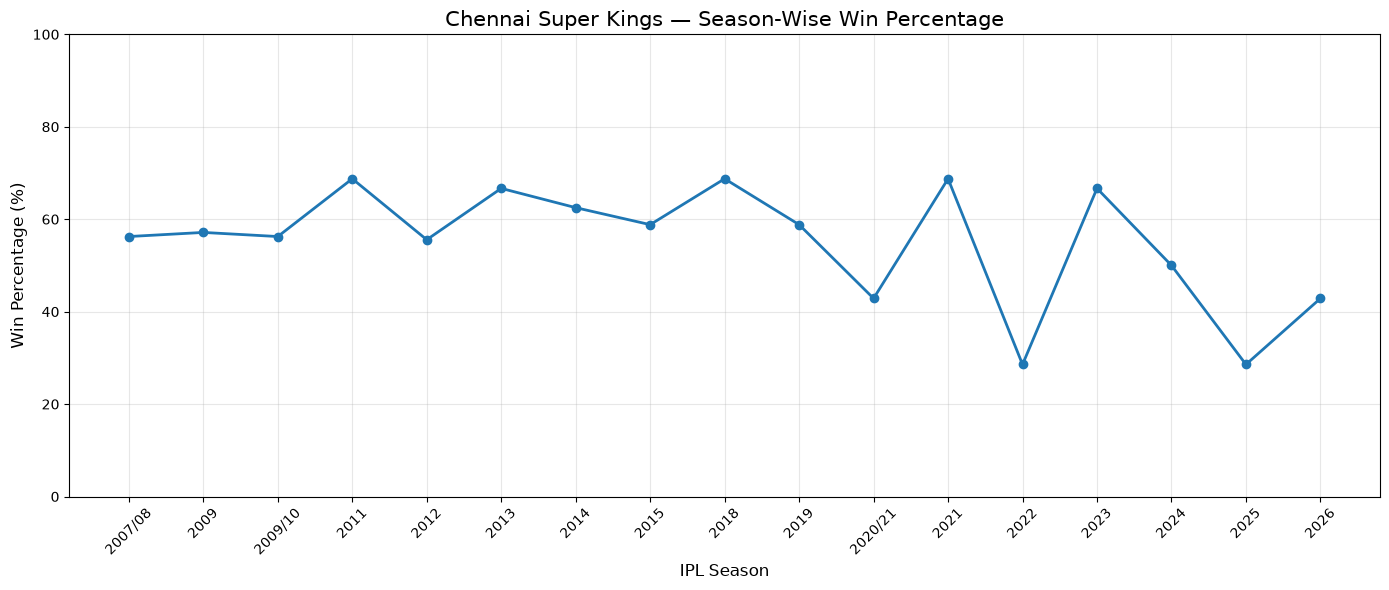

,season,decided_matches,wins,losses,win_percentage
0,2007/08,16,9,7,56.25
1,2009,14,8,6,57.14
2,2009/10,16,9,7,56.25
3,2011,16,11,5,68.75
4,2012,18,10,8,55.56
5,2013,18,12,6,66.67
6,2014,16,10,6,62.50
7,2015,17,10,7,58.82
8,2018,16,11,5,68.75
9,2019,17,10,7,58.82


In [14]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# 1. Connect to your existing DuckDB database
db_path = r"C:\Users\Raghuvanshii38\indian-premier-league\ipl.duckdb"
con = duckdb.connect(db_path, read_only=True)

# 2. Calculate CSK season-wise performance
csk_season_performance = con.sql("""
    SELECT
        season,
        COUNT(*) FILTER (
            WHERE winner IS NOT NULL
        ) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner = 'Chennai Super Kings'
        ) AS wins,
        COUNT(*) FILTER (
            WHERE winner IS NOT NULL
              AND winner <> 'Chennai Super Kings'
        ) AS losses,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner = 'Chennai Super Kings'
            )
            / NULLIF(
                COUNT(*) FILTER (WHERE winner IS NOT NULL),
                0
            ),
            2
        ) AS win_percentage
    FROM dbt_prod.fct_matches
    WHERE
        team1 = 'Chennai Super Kings'
        OR team2 = 'Chennai Super Kings'
    GROUP BY season
    ORDER BY season
""").df()

# 3. Prepare the chart data
season_chart = csk_season_performance.copy()
season_chart["season"] = season_chart["season"].astype(str)

# Sort seasons chronologically using the season labels
season_chart = season_chart.sort_values(
    "season",
    key=lambda col: col.str.split("/").str[0].astype(int)
)

# 4. Plot season-wise win percentage
plt.figure(figsize=(14, 6))

plt.plot(
    season_chart["season"],
    season_chart["win_percentage"],
    marker="o",
    linewidth=2
)

# 5. Add labels and formatting
plt.title(
    "Chennai Super Kings — Season-Wise Win Percentage",
    fontsize=15
)
plt.xlabel("IPL Season", fontsize=12)
plt.ylabel("Win Percentage (%)", fontsize=12)
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Display the underlying values
display(csk_season_performance)

In [15]:
display(csk_season_performance)

,season,decided_matches,wins,losses,win_percentage
0,2007/08,16,9,7,56.25
1,2009,14,8,6,57.14
2,2009/10,16,9,7,56.25
3,2011,16,11,5,68.75
4,2012,18,10,8,55.56
5,2013,18,12,6,66.67
6,2014,16,10,6,62.50
7,2015,17,10,7,58.82
8,2018,16,11,5,68.75
9,2019,17,10,7,58.82


In [16]:

result_check = con.sql("""
    SELECT
        result,
        COUNT(*) AS match_count,
        SUM(
            CASE WHEN winner IS NULL THEN 1 ELSE 0 END
        ) AS matches_without_winner
    FROM dbt_prod.fct_matches
    WHERE LOWER(team1) LIKE '%chennai super kings%'
       OR LOWER(team2) LIKE '%chennai super kings%'
    GROUP BY result
    ORDER BY match_count DESC
""").df()

display(result_check)


,result,match_count,matches_without_winner
0,NaN,264,0.0
1,no result,1,1.0
2,tie,1,0.0


In [17]:

csk_opponent_performance = con.sql("""
    WITH csk_matches AS (
        SELECT
            season,
            match_id,
            team1,
            team2,
            winner,
            CASE
                WHEN LOWER(team1) LIKE '%chennai super kings%'
                THEN team2
                ELSE team1
            END AS opponent
        FROM dbt_prod.fct_matches
        WHERE LOWER(team1) LIKE '%chennai super kings%'
           OR LOWER(team2) LIKE '%chennai super kings%'
    )
    SELECT
        opponent,
        COUNT(*) AS matches_played,
        SUM(
            CASE
                WHEN LOWER(winner) LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS csk_wins,
        SUM(
            CASE
                WHEN winner IS NOT NULL
                 AND LOWER(winner) NOT LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS csk_losses,
        SUM(
            CASE WHEN winner IS NULL THEN 1 ELSE 0 END
        ) AS matches_without_winner,
        ROUND(
            100.0 * SUM(
                CASE
                    WHEN LOWER(winner) LIKE '%chennai super kings%'
                    THEN 1 ELSE 0
                END
            ) / NULLIF(COUNT(winner), 0),
            2
        ) AS win_percentage
    FROM csk_matches
    GROUP BY opponent
    ORDER BY win_percentage DESC, matches_played DESC
""").df()

display(csk_opponent_performance)


,opponent,matches_played,csk_wins,csk_losses,matches_without_winner,win_percentage
0,Pune Warriors,6,4.0,2.0,0.0,66.67
1,Kolkata Knight Riders,32,21.0,11.0,0.0,65.63
2,Delhi Capitals,33,21.0,12.0,0.0,63.64
3,Sunrisers Hyderabad,24,15.0,9.0,0.0,62.50
4,Royal Challengers Bengaluru,35,21.0,14.0,0.0,60.00
5,Deccan Chargers,10,6.0,4.0,0.0,60.00
6,Rajasthan Royals,32,16.0,16.0,0.0,50.00
7,Kochi Tuskers Kerala,2,1.0,1.0,0.0,50.00
8,Mumbai Indians,41,20.0,21.0,0.0,48.78
9,Punjab Kings,33,16.0,17.0,0.0,48.48


In [18]:

csk_season_performance = con.sql("""
    SELECT
        season,
        COUNT(*) AS matches_played,

        COUNT(winner) AS matches_with_recorded_winner,

        SUM(
            CASE
                WHEN LOWER(winner) LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS matches_won,

        SUM(
            CASE
                WHEN winner IS NOT NULL
                 AND LOWER(winner) NOT LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS matches_lost,

        SUM(
            CASE WHEN winner IS NULL THEN 1 ELSE 0 END
        ) AS matches_without_winner,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN LOWER(winner) LIKE '%chennai super kings%'
                    THEN 1 ELSE 0
                END
            ) / NULLIF(COUNT(winner), 0),
            2
        ) AS win_percentage

    FROM dbt_prod.fct_matches
    WHERE LOWER(team1) LIKE '%chennai super kings%'
       OR LOWER(team2) LIKE '%chennai super kings%'

    GROUP BY season
    ORDER BY season
""").df()

display(csk_season_performance)


,season,matches_played,matches_with_recorded_winner,matches_won,matches_lost,matches_without_winner,win_percentage
0,2007/08,16,16,9.0,7.0,0.0,56.25
1,2009,14,14,8.0,6.0,0.0,57.14
2,2009/10,16,16,9.0,7.0,0.0,56.25
3,2011,16,16,11.0,5.0,0.0,68.75
4,2012,18,18,10.0,8.0,0.0,55.56
5,2013,18,18,12.0,6.0,0.0,66.67
6,2014,16,16,10.0,6.0,0.0,62.50
7,2015,17,17,10.0,7.0,0.0,58.82
8,2018,16,16,11.0,5.0,0.0,68.75
9,2019,17,17,10.0,7.0,0.0,58.82


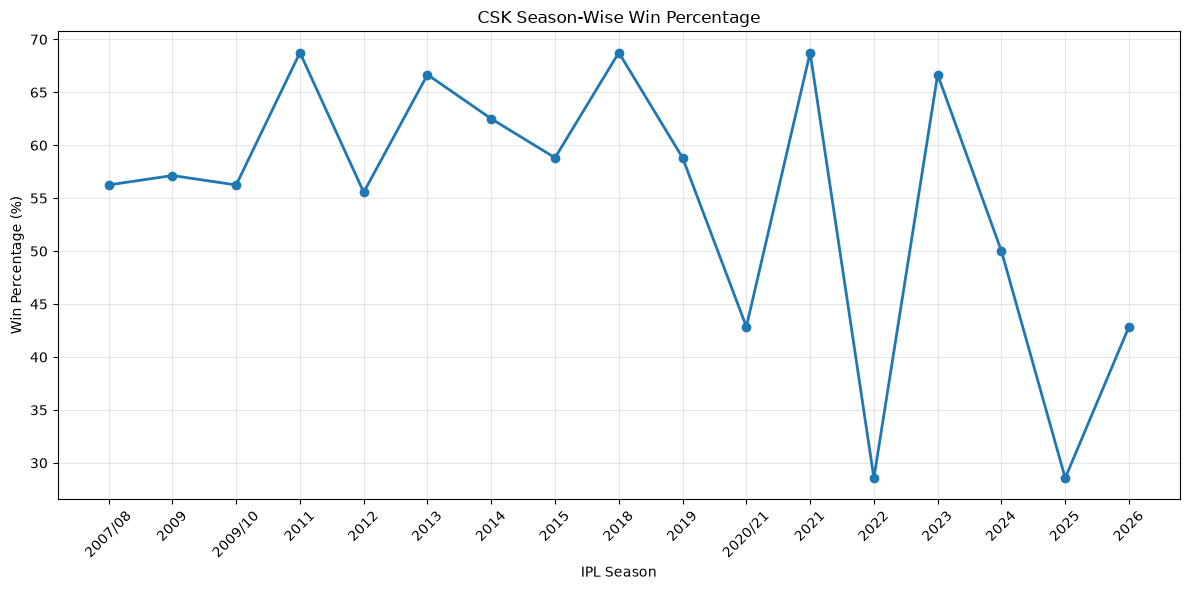

In [19]:

import matplotlib.pyplot as plt

season_chart = csk_season_performance.copy()
season_chart["season"] = season_chart["season"].astype(str)

plt.figure(figsize=(12, 6))
plt.plot(
    season_chart["season"],
    season_chart["win_percentage"],
    marker="o",
    linewidth=2
)

plt.title("CSK Season-Wise Win Percentage")
plt.xlabel("IPL Season")
plt.ylabel("Win Percentage (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

csk_opponent_performance = con.sql("""
    WITH csk_matches AS (
        SELECT
            match_id,
            team1,
            team2,
            winner,
            CASE
                WHEN LOWER(team1) LIKE '%chennai super kings%'
                THEN team2
                ELSE team1
            END AS opponent
        FROM dbt_prod.fct_matches
        WHERE LOWER(team1) LIKE '%chennai super kings%'
           OR LOWER(team2) LIKE '%chennai super kings%'
    )
    SELECT
        opponent,
        COUNT(*) AS matches_played,

        COUNT(winner) AS matches_with_recorded_winner,

        SUM(
            CASE
                WHEN LOWER(winner) LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS csk_wins,

        SUM(
            CASE
                WHEN winner IS NOT NULL
                 AND LOWER(winner) NOT LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS csk_losses,

        SUM(
            CASE WHEN winner IS NULL THEN 1 ELSE 0 END
        ) AS matches_without_winner,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN LOWER(winner) LIKE '%chennai super kings%'
                    THEN 1 ELSE 0
                END
            ) / NULLIF(COUNT(winner), 0),
            2
        ) AS win_percentage

    FROM csk_matches
    GROUP BY opponent
    ORDER BY win_percentage DESC, matches_played DESC
""").df()

display(csk_opponent_performance)


,opponent,matches_played,matches_with_recorded_winner,csk_wins,csk_losses,matches_without_winner,win_percentage
0,Pune Warriors,6,6,4.0,2.0,0.0,66.67
1,Kolkata Knight Riders,32,32,21.0,11.0,0.0,65.63
2,Delhi Capitals,33,33,21.0,12.0,0.0,63.64
3,Sunrisers Hyderabad,24,24,15.0,9.0,0.0,62.50
4,Royal Challengers Bengaluru,35,35,21.0,14.0,0.0,60.00
5,Deccan Chargers,10,10,6.0,4.0,0.0,60.00
6,Rajasthan Royals,32,32,16.0,16.0,0.0,50.00
7,Kochi Tuskers Kerala,2,2,1.0,1.0,0.0,50.00
8,Mumbai Indians,41,41,20.0,21.0,0.0,48.78
9,Punjab Kings,33,33,16.0,17.0,0.0,48.48


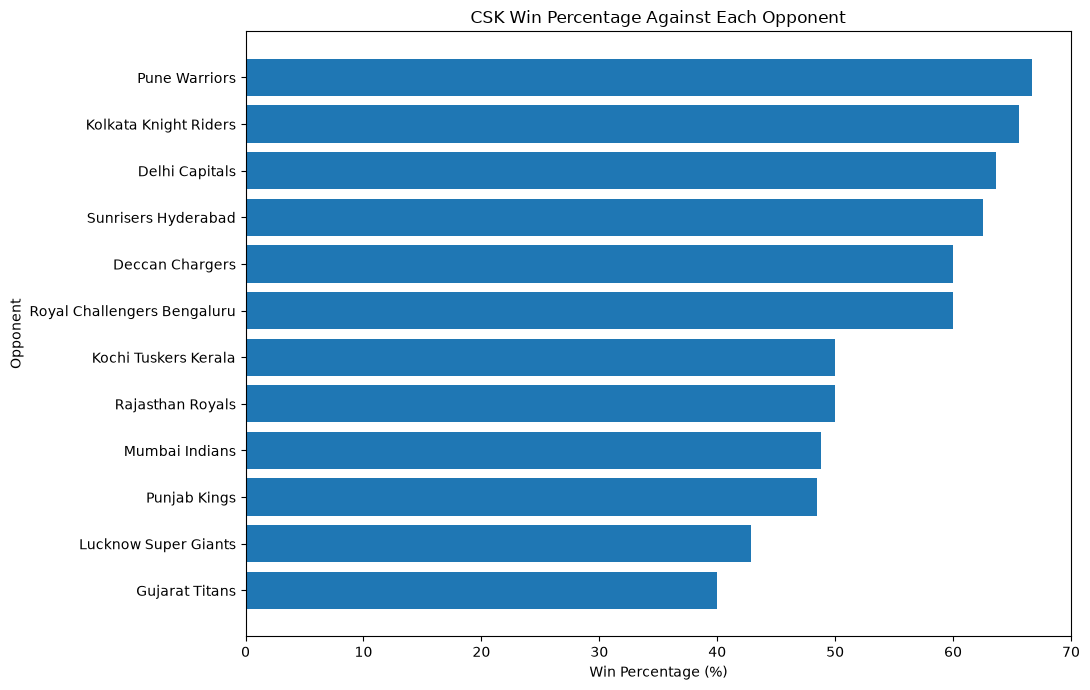

In [21]:

import matplotlib.pyplot as plt

opponent_chart = csk_opponent_performance.dropna(
    subset=["win_percentage"]
).sort_values("win_percentage", ascending=True)

plt.figure(figsize=(11, 7))
plt.barh(
    opponent_chart["opponent"],
    opponent_chart["win_percentage"]
)

plt.title("CSK Win Percentage Against Each Opponent")
plt.xlabel("Win Percentage (%)")
plt.ylabel("Opponent")
plt.tight_layout()
plt.show()


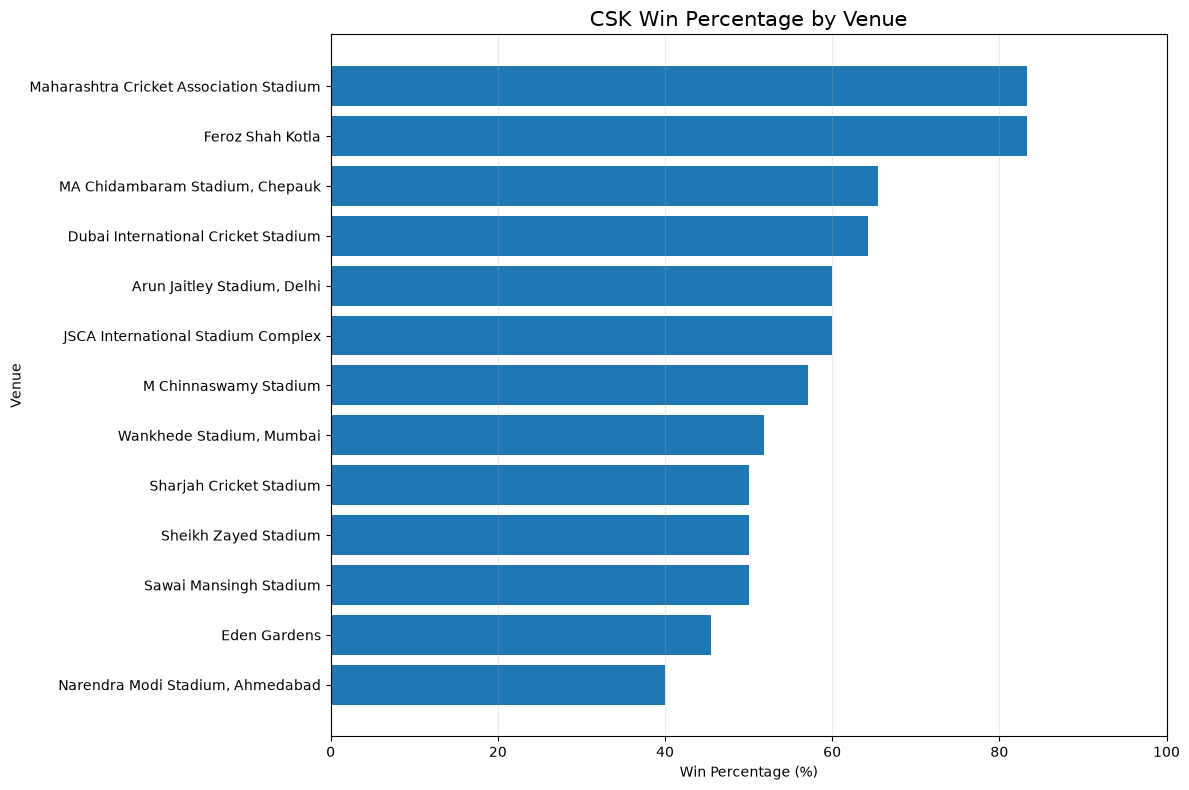

,venue,decided_matches,csk_wins,csk_losses,win_percentage
0,"Narendra Modi Stadium, Ahmedabad",5,2,3,40.00
1,Eden Gardens,11,5,6,45.45
2,Sawai Mansingh Stadium,6,3,3,50.00
3,Sheikh Zayed Stadium,6,3,3,50.00
4,Sharjah Cricket Stadium,6,3,3,50.00
5,"Wankhede Stadium, Mumbai",27,14,13,51.85
6,M Chinnaswamy Stadium,7,4,3,57.14
7,JSCA International Stadium Complex,5,3,2,60.00
8,"Arun Jaitley Stadium, Delhi",5,3,2,60.00
9,Dubai International Cricket Stadium,14,9,5,64.29


In [22]:
import duckdb
import matplotlib.pyplot as plt

# Connect to the IPL database
db_path = r"C:\Users\Raghuvanshii38\indian-premier-league\ipl.duckdb"
con = duckdb.connect(db_path, read_only=True)

# Calculate CSK win percentage by venue
csk_venue_analysis = con.sql("""
    WITH venue_results AS (
        SELECT
            CASE
                WHEN venue IN (
                    'MA Chidambaram Stadium',
                    'MA Chidambaram Stadium, Chepauk',
                    'MA Chidambaram Stadium, Chepauk, Chennai'
                )
                    THEN 'MA Chidambaram Stadium, Chepauk'
                WHEN venue IN (
                    'Wankhede Stadium',
                    'Wankhede Stadium, Mumbai'
                )
                    THEN 'Wankhede Stadium, Mumbai'
                ELSE venue
            END AS venue,
            winner
        FROM dbt_prod.fct_matches
        WHERE (
            team1 = 'Chennai Super Kings'
            OR team2 = 'Chennai Super Kings'
        )
        AND winner IS NOT NULL
        AND venue IS NOT NULL
    )
    SELECT
        venue,
        COUNT(*) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner = 'Chennai Super Kings'
        ) AS csk_wins,
        COUNT(*) FILTER (
            WHERE winner <> 'Chennai Super Kings'
        ) AS csk_losses,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner = 'Chennai Super Kings'
            ) / COUNT(*),
            2
        ) AS win_percentage
    FROM venue_results
    GROUP BY venue
    HAVING COUNT(*) >= 5
    ORDER BY win_percentage
""").df()

# Sort venues from lowest to highest win percentage
venue_plot = csk_venue_analysis.sort_values(
    "win_percentage",
    ascending=True
)

# Plot the horizontal bar chart
plt.figure(figsize=(12, 8))

plt.barh(
    venue_plot["venue"],
    venue_plot["win_percentage"]
)

plt.title("CSK Win Percentage by Venue", fontsize=15)
plt.xlabel("Win Percentage (%)")
plt.ylabel("Venue")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# Display the data behind the chart
display(csk_venue_analysis)

In [23]:
csk_venue_performance = con.sql("""
    SELECT
        venue,
        COUNT(*) AS matches_played,

        SUM(
            CASE
                WHEN LOWER(winner) LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS csk_wins,

        SUM(
            CASE
                WHEN winner IS NOT NULL
                 AND LOWER(winner) NOT LIKE '%chennai super kings%'
                THEN 1 ELSE 0
            END
        ) AS csk_losses,

        SUM(
            CASE WHEN winner IS NULL THEN 1 ELSE 0 END
        ) AS matches_without_winner,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN LOWER(winner) LIKE '%chennai super kings%'
                    THEN 1 ELSE 0
                END
            ) / NULLIF(COUNT(winner), 0),
            2
        ) AS win_percentage

    FROM dbt_prod.fct_matches
    WHERE (
        LOWER(team1) LIKE '%chennai super kings%'
        OR LOWER(team2) LIKE '%chennai super kings%'
    )
    AND venue IS NOT NULL

    GROUP BY venue
    HAVING COUNT(*) >= 3
    ORDER BY win_percentage DESC, matches_played DESC
""").df()

display(csk_venue_performance)

,venue,matches_played,csk_wins,csk_losses,matches_without_winner,win_percentage
0,Maharashtra Cricket Association Stadium,6,5.0,1.0,0.0,83.33
1,Feroz Shah Kotla,6,5.0,1.0,0.0,83.33
2,MA Chidambaram Stadium,9,7.0,2.0,0.0,77.78
3,"Punjab Cricket Association Stadium, Mohali",4,3.0,1.0,0.0,75.00
4,Dr DY Patil Sports Academy,4,3.0,1.0,0.0,75.00
5,"Dr DY Patil Sports Academy, Mumbai",4,3.0,1.0,0.0,75.00
6,"MA Chidambaram Stadium, Chepauk",47,33.0,14.0,0.0,70.21
7,SuperSport Park,3,2.0,1.0,0.0,66.67
8,"Rajiv Gandhi International Stadium, Uppal",3,2.0,1.0,0.0,66.67
9,Dubai International Cricket Stadium,14,9.0,5.0,0.0,64.29


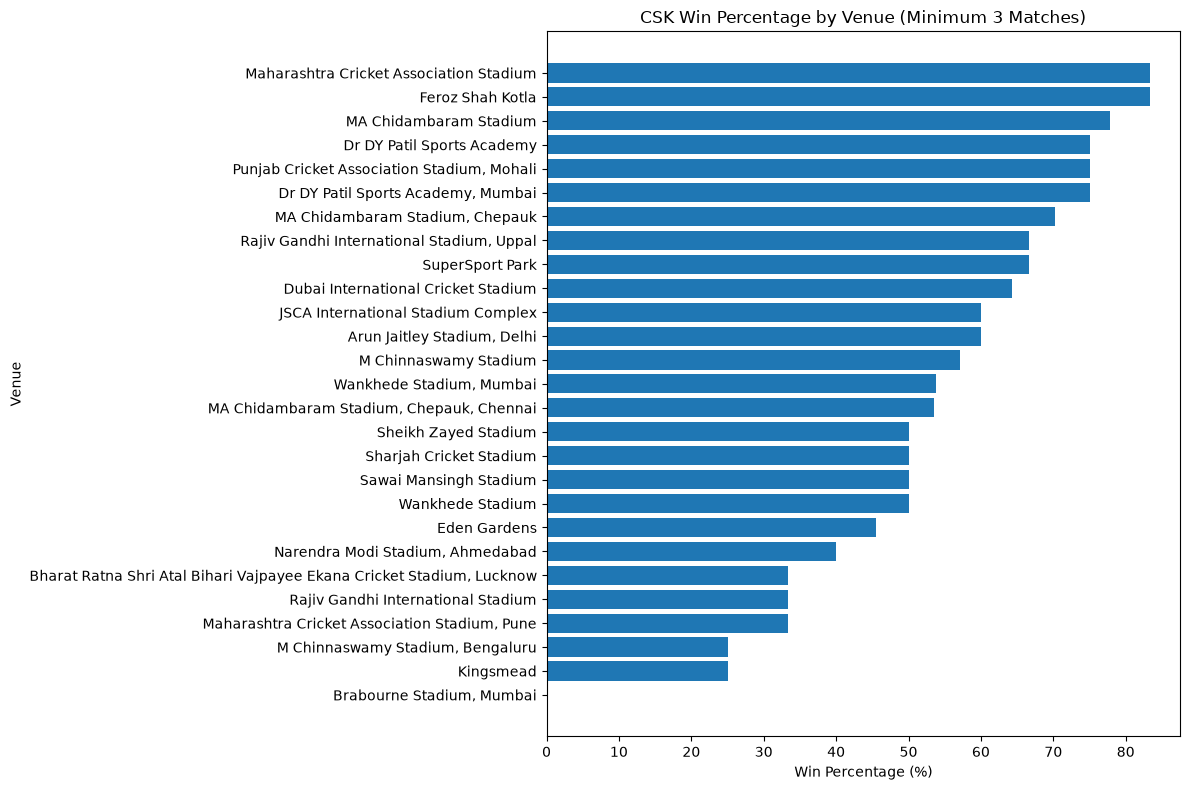

In [24]:
import matplotlib.pyplot as plt

venue_chart = csk_venue_performance.dropna(
    subset=["win_percentage"]
).sort_values("win_percentage", ascending=True)

plt.figure(figsize=(12, 8))
plt.barh(
    venue_chart["venue"],
    venue_chart["win_percentage"]
)

plt.title("CSK Win Percentage by Venue (Minimum 3 Matches)")
plt.xlabel("Win Percentage (%)")
plt.ylabel("Venue")
plt.tight_layout()
plt.show()

In [25]:
jadeja_diagnostic = con.sql("""
    SELECT
        bowler,
        team,
        batting_team,
        dismissal_kind,
        COUNT(*) AS delivery_rows,

        SUM(
            CASE WHEN is_wicket THEN 1 ELSE 0 END
        ) AS wicket_event_rows,

        SUM(bowler_wickets) AS summed_bowler_wickets,
        MIN(bowler_wickets) AS min_bowler_wickets,
        MAX(bowler_wickets) AS max_bowler_wickets

    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'

    GROUP BY
        bowler,
        team,
        batting_team,
        dismissal_kind

    ORDER BY delivery_rows DESC
""").df()

display(jadeja_diagnostic)

,bowler,team,batting_team,dismissal_kind,delivery_rows,wicket_event_rows,summed_bowler_wickets,min_bowler_wickets,max_bowler_wickets
0,RA Jadeja,Chennai Super Kings,Mumbai Indians,,450,0.0,164.0,0,3
1,RA Jadeja,Chennai Super Kings,Kolkata Knight Riders,,409,0.0,207.0,0,4
2,RA Jadeja,Chennai Super Kings,Royal Challengers Bengaluru,,401,0.0,172.0,0,3
3,RA Jadeja,Chennai Super Kings,Punjab Kings,,394,0.0,150.0,0,3
4,RA Jadeja,Chennai Super Kings,Rajasthan Royals,,377,0.0,210.0,0,4
...,...,...,...,...,...,...,...,...,...
110,RA Jadeja,Rajasthan Royals,Kolkata Knight Riders,caught,1,1.0,2.0,2,2
111,RA Jadeja,Rajasthan Royals,Delhi Capitals,run out,1,1.0,0.0,0,0
112,RA Jadeja,Chennai Super Kings,Royal Challengers Bengaluru,stumped,1,1.0,1.0,1,1
113,RA Jadeja,Gujarat Lions,Punjab Kings,caught,1,1.0,1.0,1,1


In [26]:

bowling_team_check = con.sql("""
    SELECT
        team,
        batting_team,
        COUNT(*) AS delivery_rows,
        COUNT(DISTINCT match_id) AS matches
    FROM dbt_prod.mart_bowler_spell
    GROUP BY
        team,
        batting_team
    ORDER BY delivery_rows DESC
""").df()

display(bowling_team_check)


,team,batting_team,delivery_rows,matches
0,Mumbai Indians,Chennai Super Kings,4982,41
1,Chennai Super Kings,Mumbai Indians,4896,41
2,Delhi Capitals,Mumbai Indians,4649,38
3,Mumbai Indians,Delhi Capitals,4500,38
4,Mumbai Indians,Punjab Kings,4439,36
...,...,...,...,...
161,Kochi Tuskers Kerala,Pune Warriors,123,1
162,Pune Warriors,Kochi Tuskers Kerala,123,1
163,Mumbai Indians,Kochi Tuskers Kerala,121,1
164,Kochi Tuskers Kerala,Punjab Kings,118,1


In [27]:
bowling_schema_check = con.sql("""
    DESCRIBE SELECT *
    FROM dbt_prod.mart_bowler_spell
""").df()

display(bowling_schema_check)

,column_name,column_type,null,key,default,extra
0,match_id,BIGINT,YES,None,None,None
1,match_date,TIMESTAMP_NS,YES,None,None,None
2,match_date_str,VARCHAR,YES,None,None,None
3,season,VARCHAR,YES,None,None,None
4,match_number,INTEGER,YES,None,None,None
5,innings,INTEGER,YES,None,None,None
6,innings_role,VARCHAR,YES,None,None,None
7,team,VARCHAR,YES,None,None,None
8,batting_team,VARCHAR,YES,None,None,None
9,over,INTEGER,YES,None,None,None


In [28]:
jadeja_sample = con.sql("""
    SELECT
        match_id,
        season,
        innings,
        team,
        batting_team,
        over,
        ball,
        bowler,
        bowler_wickets,
        is_wicket,
        player_out,
        dismissal_kind
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'
    ORDER BY match_date DESC, match_id DESC, innings, over, ball
    LIMIT 30
""").df()

display(jadeja_sample)

,match_id,season,innings,team,batting_team,over,ball,bowler,bowler_wickets,is_wicket,player_out,dismissal_kind
0,1535464,2026,2,Rajasthan Royals,Gujarat Titans,10,1,RA Jadeja,0,False,,
1,1535464,2026,2,Rajasthan Royals,Gujarat Titans,10,2,RA Jadeja,0,False,,
2,1535464,2026,2,Rajasthan Royals,Gujarat Titans,10,3,RA Jadeja,0,False,,
3,1535464,2026,2,Rajasthan Royals,Gujarat Titans,10,4,RA Jadeja,0,False,,
4,1535464,2026,2,Rajasthan Royals,Gujarat Titans,10,5,RA Jadeja,0,False,,
5,1535464,2026,2,Rajasthan Royals,Gujarat Titans,10,6,RA Jadeja,0,False,,
6,1535464,2026,2,Rajasthan Royals,Gujarat Titans,14,1,RA Jadeja,0,False,,
7,1535464,2026,2,Rajasthan Royals,Gujarat Titans,14,2,RA Jadeja,0,False,,
8,1535464,2026,2,Rajasthan Royals,Gujarat Titans,14,3,RA Jadeja,0,False,,
9,1535464,2026,2,Rajasthan Royals,Gujarat Titans,14,4,RA Jadeja,0,False,,


In [29]:
batting_schema = con.sql("""
    DESCRIBE dbt_prod.mart_batter_innings
""").df()

display(batting_schema)

,column_name,column_type,null,key,default,extra
0,match_id,BIGINT,YES,None,None,None
1,match_date,TIMESTAMP_NS,YES,None,None,None
2,match_date_str,VARCHAR,YES,None,None,None
3,season,VARCHAR,YES,None,None,None
4,innings,INTEGER,YES,None,None,None
5,team,VARCHAR,YES,None,None,None
6,bowling_team,VARCHAR,YES,None,None,None
7,over,INTEGER,YES,None,None,None
8,ball,INTEGER,YES,None,None,None
9,phase,VARCHAR,YES,None,None,None


In [30]:
batting_sample = con.sql("""
    SELECT *
    FROM dbt_prod.mart_batter_innings
    LIMIT 10
""").df()

display(batting_sample)

,match_id,match_date,match_date_str,season,innings,team,bowling_team,over,ball,phase,...,ball_faced,batter_runs_cumulative,batter_balls_faced,batter_strike_rate,batter_fours,batter_sixes,batter_boundaries,balls_per_boundary,batter_dismissed,dismissal_kind
0,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,2,Powerplay,...,1,0,1,0.00,0,0,0,NaN,False,
1,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,3,Powerplay,...,0,0,1,0.00,0,0,0,NaN,False,
2,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,4,Powerplay,...,1,0,2,0.00,0,0,0,NaN,False,
3,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,5,Powerplay,...,1,0,3,0.00,0,0,0,NaN,False,
4,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,6,Powerplay,...,1,0,4,0.00,0,0,0,NaN,False,
5,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,1,7,Powerplay,...,1,0,5,0.00,0,0,0,NaN,False,
6,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,2,1,Powerplay,...,1,0,6,0.00,0,0,0,NaN,False,
7,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,2,2,Powerplay,...,1,4,7,57.14,1,0,1,7.0,False,
8,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,2,3,Powerplay,...,1,8,8,100.00,2,0,2,4.0,False,
9,335982,2008-04-18,2008-04-18,2007/08,1,Kolkata Knight Riders,Royal Challengers Bengaluru,2,4,Powerplay,...,1,14,9,155.56,2,1,3,3.0,False,


In [31]:
batting_columns = set(batting_schema["column_name"].str.lower())

print("Available batting columns:")
print(batting_schema["column_name"].tolist())

required_columns = {"season", "batter", "batter_runs"}

if required_columns.issubset(batting_columns):
    csk_batting_performance = con.sql("""
        SELECT
            season,
            batter,
            COUNT(DISTINCT match_id) AS matches_recorded,
            SUM(batter_runs) AS total_runs
        FROM dbt_prod.mart_batter_innings
        WHERE LOWER(team) LIKE '%chennai super kings%'
        GROUP BY season, batter
        ORDER BY season, total_runs DESC
    """).df()

    display(csk_batting_performance)
else:
    print(
        "The expected columns are not all present. "
        "Use the displayed schema to build the query accurately."
    )

Available batting columns:
['match_id', 'match_date', 'match_date_str', 'season', 'innings', 'team', 'bowling_team', 'over', 'ball', 'phase', 'batter', 'batter_id', 'bowler', 'bowler_id', 'non_striker', 'non_striker_id', 'batter_runs', 'ball_faced', 'batter_runs_cumulative', 'batter_balls_faced', 'batter_strike_rate', 'batter_fours', 'batter_sixes', 'batter_boundaries', 'balls_per_boundary', 'batter_dismissed', 'dismissal_kind']


,season,batter,matches_recorded,total_runs
0,2007/08,SK Raina,14,421.0
1,2007/08,MS Dhoni,14,414.0
2,2007/08,PA Patel,13,302.0
3,2007/08,JA Morkel,10,241.0
4,2007/08,SP Fleming,10,196.0
...,...,...,...,...
252,2026,Noor Ahmad,4,11.0
253,2026,MJ Henry,2,7.0
254,2026,AJ Hosein,2,5.0
255,2026,Mukesh Choudhary,1,2.0


In [32]:
batting_grain_check = con.sql("""
    SELECT
        season,
        match_id,
        batter,
        team,
        COUNT(*) AS rows_per_player_match,
        SUM(batter_runs) AS summed_batter_runs,
        MIN(batter_runs) AS min_batter_runs,
        MAX(batter_runs) AS max_batter_runs
    FROM dbt_prod.mart_batter_innings
    WHERE LOWER(team) LIKE '%chennai super kings%'
    GROUP BY
        season,
        match_id,
        batter,
        team
    HAVING COUNT(*) > 1
    ORDER BY rows_per_player_match DESC
    LIMIT 50
""").df()

display(batting_grain_check)

,season,match_id,batter,team,rows_per_player_match,summed_batter_runs,min_batter_runs,max_batter_runs
0,2026,1529280,RD Gaikwad,Chennai Super Kings,63,74.0,0,6
1,2015,829797,BB McCullum,Chennai Super Kings,63,81.0,0,6
2,2021,1254072,F du Plessis,Chennai Super Kings,63,95.0,0,6
3,2021,1254089,RD Gaikwad,Chennai Super Kings,62,101.0,0,6
4,2019,1181768,SR Watson,Chennai Super Kings,62,80.0,0,6
5,2018,1136606,AT Rayudu,Chennai Super Kings,62,100.0,0,6
6,2024,1426277,RD Gaikwad,Chennai Super Kings,61,108.0,0,6
7,2021,1254094,F du Plessis,Chennai Super Kings,61,76.0,0,6
8,2012,548380,M Vijay,Chennai Super Kings,61,113.0,0,6
9,2021,1254117,F du Plessis,Chennai Super Kings,61,86.0,0,6


In [33]:
batting_innings_grain_check = con.sql("""
    SELECT
        season,
        match_id,
        innings,
        batter,
        team,
        COUNT(*) AS delivery_rows,
        COUNT(DISTINCT batter_runs) AS distinct_run_values,
        MIN(batter_runs) AS min_batter_runs,
        MAX(batter_runs) AS max_batter_runs
    FROM dbt_prod.mart_batter_innings
    WHERE LOWER(team) LIKE '%chennai super kings%'
    GROUP BY
        season,
        match_id,
        innings,
        batter,
        team
    ORDER BY
        delivery_rows DESC
    LIMIT 50
""").df()

display(batting_innings_grain_check)

,season,match_id,innings,batter,team,delivery_rows,distinct_run_values,min_batter_runs,max_batter_runs
0,2021,1254072,1,F du Plessis,Chennai Super Kings,63,6,0,6
1,2026,1529280,1,RD Gaikwad,Chennai Super Kings,63,6,0,6
2,2015,829797,1,BB McCullum,Chennai Super Kings,63,5,0,6
3,2018,1136606,2,AT Rayudu,Chennai Super Kings,62,5,0,6
4,2021,1254089,1,RD Gaikwad,Chennai Super Kings,62,5,0,6
5,2019,1181768,2,SR Watson,Chennai Super Kings,62,5,0,6
6,2021,1254117,1,F du Plessis,Chennai Super Kings,61,5,0,6
7,2009,392227,2,ML Hayden,Chennai Super Kings,61,5,0,6
8,2012,548380,1,M Vijay,Chennai Super Kings,61,5,0,6
9,2021,1254094,1,F du Plessis,Chennai Super Kings,61,5,0,6


In [34]:

batting_value_check = con.sql("""
    SELECT
        season,
        match_id,
        innings,
        batter,
        team,
        over,
        ball,
        batter_runs,
        batter_runs_cumulative
    FROM dbt_prod.mart_batter_innings
    WHERE LOWER(team) LIKE '%chennai super kings%'
    ORDER BY match_date DESC, match_id DESC, innings, over, ball
    LIMIT 30
""").df()

display(batting_value_check)


,season,match_id,innings,batter,team,over,ball,batter_runs,batter_runs_cumulative
0,2026,1529309,2,SV Samson,Chennai Super Kings,1,1,0,0
1,2026,1529309,2,RD Gaikwad,Chennai Super Kings,1,2,0,0
2,2026,1529309,2,RD Gaikwad,Chennai Super Kings,1,3,0,0
3,2026,1529309,2,RD Gaikwad,Chennai Super Kings,1,4,4,4
4,2026,1529309,2,RD Gaikwad,Chennai Super Kings,1,5,6,10
5,2026,1529309,2,RD Gaikwad,Chennai Super Kings,1,6,0,10
6,2026,1529309,2,MW Short,Chennai Super Kings,2,1,4,4
7,2026,1529309,2,MW Short,Chennai Super Kings,2,2,0,4
8,2026,1529309,2,MW Short,Chennai Super Kings,2,3,2,6
9,2026,1529309,2,MW Short,Chennai Super Kings,2,4,0,6


In [35]:

batting_cumulative_check = con.sql("""
    WITH batting_rows AS (
        SELECT
            season,
            match_id,
            innings,
            batter,
            team,
            over,
            ball,
            batter_runs,
            batter_runs_cumulative,
            ROW_NUMBER() OVER (
                PARTITION BY match_id, innings, batter
                ORDER BY over DESC, ball DESC
            ) AS reverse_row_num
        FROM dbt_prod.mart_batter_innings
        WHERE LOWER(team) LIKE '%chennai super kings%'
    )
    SELECT
        season,
        match_id,
        innings,
        batter,
        team,
        COUNT(*) AS recorded_rows,
        SUM(batter_runs) AS sum_of_batter_runs,
        MAX(batter_runs_cumulative) AS max_cumulative_runs,
        MAX(
            CASE
                WHEN reverse_row_num = 1
                THEN batter_runs_cumulative
            END
        ) AS final_recorded_cumulative_runs
    FROM batting_rows
    GROUP BY season, match_id, innings, batter, team
    ORDER BY season DESC, match_id DESC, innings, batter
    LIMIT 50
""").df()

display(batting_cumulative_check)


,season,match_id,innings,batter,team,recorded_rows,sum_of_batter_runs,max_cumulative_runs,final_recorded_cumulative_runs
0,2026,1529309,2,A Kamboj,Chennai Super Kings,8,19.0,19,19
1,2026,1529309,2,D Brevis,Chennai Super Kings,11,8.0,8,8
2,2026,1529309,2,Kartik Sharma,Chennai Super Kings,15,19.0,19,19
3,2026,1529309,2,MW Short,Chennai Super Kings,15,24.0,24,24
4,2026,1529309,2,Mukesh Choudhary,Chennai Super Kings,2,2.0,2,2
5,2026,1529309,2,Noor Ahmad,Chennai Super Kings,5,1.0,1,1
6,2026,1529309,2,RD Gaikwad,Chennai Super Kings,7,16.0,16,16
7,2026,1529309,2,S Dube,Chennai Super Kings,19,47.0,47,47
8,2026,1529309,2,SH Johnson,Chennai Super Kings,1,0.0,0,0
9,2026,1529309,2,SV Samson,Chennai Super Kings,1,0.0,0,0


In [36]:
batting_final_innings_check = con.sql("""
    WITH ranked_rows AS (
        SELECT
            season,
            match_id,
            innings,
            batter,
            team,
            over,
            ball,
            batter_runs,
            batter_runs_cumulative,
            ROW_NUMBER() OVER (
                PARTITION BY match_id, innings, batter
                ORDER BY over DESC, ball DESC
            ) AS rn
        FROM dbt_prod.mart_batter_innings
        WHERE LOWER(team) LIKE '%chennai super kings%'
    )
    SELECT
        season,
        match_id,
        innings,
        batter,
        team,
        over AS final_over,
        ball AS final_ball,
        batter_runs,
        batter_runs_cumulative AS final_cumulative_runs
    FROM ranked_rows
    WHERE rn = 1
    ORDER BY season DESC, match_id DESC, innings, batter
    LIMIT 50
""").df()

display(batting_final_innings_check)

,season,match_id,innings,batter,team,final_over,final_ball,batter_runs,final_cumulative_runs
0,2026,1529309,2,A Kamboj,Chennai Super Kings,13,1,0,19
1,2026,1529309,2,D Brevis,Chennai Super Kings,13,5,0,8
2,2026,1529309,2,Kartik Sharma,Chennai Super Kings,7,6,0,19
3,2026,1529309,2,MW Short,Chennai Super Kings,6,1,0,24
4,2026,1529309,2,Mukesh Choudhary,Chennai Super Kings,13,7,0,2
5,2026,1529309,2,Noor Ahmad,Chennai Super Kings,14,3,0,1
6,2026,1529309,2,RD Gaikwad,Chennai Super Kings,3,2,0,16
7,2026,1529309,2,S Dube,Chennai Super Kings,11,3,0,47
8,2026,1529309,2,SH Johnson,Chennai Super Kings,14,4,0,0
9,2026,1529309,2,SV Samson,Chennai Super Kings,1,1,0,0


In [37]:
jadeja_wicket_validation = con.sql("""
    SELECT
        bowler,
        COUNT(*) AS delivery_rows,

        SUM(
            CASE WHEN is_wicket THEN 1 ELSE 0 END
        ) AS rows_marked_as_wickets,

        SUM(
            CASE
                WHEN player_out IS NOT NULL
                THEN 1 ELSE 0
            END
        ) AS rows_with_player_out,

        SUM(
            CASE
                WHEN dismissal_kind IS NOT NULL
                THEN 1 ELSE 0
            END
        ) AS rows_with_dismissal_kind,

        SUM(bowler_wickets) AS sum_bowler_wickets,
        MIN(bowler_wickets) AS min_bowler_wickets,
        MAX(bowler_wickets) AS max_bowler_wickets,
        COUNT(DISTINCT match_id) AS matches_covered

    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'
    GROUP BY bowler
""").df()

display(jadeja_wicket_validation)

,bowler,delivery_rows,rows_marked_as_wickets,rows_with_player_out,rows_with_dismissal_kind,sum_bowler_wickets,min_bowler_wickets,max_bowler_wickets,matches_covered
0,RA Jadeja,4329,189.0,4329.0,4329.0,1860.0,0,5,237


In [38]:
jadeja_wicket_detail = con.sql("""
    SELECT
        bowler,
        is_wicket,
        dismissal_kind,
        player_out,
        bowler_wickets,
        COUNT(*) AS row_count
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'
    GROUP BY
        bowler,
        is_wicket,
        dismissal_kind,
        player_out,
        bowler_wickets
    ORDER BY
        bowler_wickets DESC,
        row_count DESC
    LIMIT 50
""").df()

display(jadeja_wicket_detail)

,bowler,is_wicket,dismissal_kind,player_out,bowler_wickets,row_count
0,RA Jadeja,True,lbw,DW Steyn,5,1
1,RA Jadeja,False,,,4,25
2,RA Jadeja,True,bowled,TG Southee,4,1
3,RA Jadeja,True,caught,DJ Hooda,4,1
4,RA Jadeja,True,caught,RV Uthappa,4,1
5,RA Jadeja,True,stumped,DB Ravi Teja,4,1
6,RA Jadeja,False,,,3,63
7,RA Jadeja,True,lbw,Tilak Varma,3,1
8,RA Jadeja,True,caught,KA Pollard,3,1
9,RA Jadeja,True,caught,MS Gony,3,1


In [39]:

jadeja_wicket_pattern = con.sql("""
    SELECT
        bowler_wickets,
        is_wicket,
        dismissal_kind,
        COUNT(*) AS delivery_rows,
        COUNT(DISTINCT match_id) AS matches,
        SUM(
            CASE
                WHEN player_out IS NOT NULL
                THEN 1 ELSE 0
            END
        ) AS rows_with_player_out
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'
    GROUP BY
        bowler_wickets,
        is_wicket,
        dismissal_kind
    ORDER BY
        bowler_wickets DESC,
        is_wicket DESC,
        delivery_rows DESC
""").df()

display(jadeja_wicket_pattern)


,bowler_wickets,is_wicket,dismissal_kind,delivery_rows,matches,rows_with_player_out
0,5,True,lbw,1,1,1.0
1,4,True,caught,2,2,2.0
2,4,True,stumped,1,1,1.0
3,4,True,bowled,1,1,1.0
4,4,False,,25,4,25.0
5,3,True,caught,11,11,11.0
6,3,True,lbw,2,2,2.0
7,3,True,stumped,2,2,2.0
8,3,True,bowled,1,1,1.0
9,3,True,caught and bowled,1,1,1.0


In [40]:

jadeja_credited_wicket_check = con.sql("""
    SELECT
        bowler,

        COUNT(*) AS delivery_rows,

        SUM(
            CASE
                WHEN is_wicket THEN 1
                ELSE 0
            END
        ) AS all_wicket_events,

        SUM(
            CASE
                WHEN LOWER(COALESCE(dismissal_kind, ''))
                     IN (
                         'bowled',
                         'caught',
                         'caught and bowled',
                         'lbw',
                         'stumped',
                         'hit wicket'
                     )
                THEN 1
                ELSE 0
            END
        ) AS potentially_bowler_credited_wickets,

        SUM(
            CASE
                WHEN LOWER(COALESCE(dismissal_kind, ''))
                     NOT IN (
                         'bowled',
                         'caught',
                         'caught and bowled',
                         'lbw',
                         'stumped',
                         'hit wicket'
                     )
                 AND is_wicket
                THEN 1
                ELSE 0
            END
        ) AS other_wicket_events

    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'
    GROUP BY bowler
""").df()

display(jadeja_credited_wicket_check)


,bowler,delivery_rows,all_wicket_events,potentially_bowler_credited_wickets,other_wicket_events
0,RA Jadeja,4329,189.0,180.0,9.0


In [41]:

jadeja_match_wicket_check = con.sql("""
    SELECT
        match_id,
        season,
        innings,
        bowler,
        COUNT(*) AS delivery_rows,
        SUM(bowler_wickets) AS summed_bowler_wickets,
        MIN(bowler_wickets) AS min_bowler_wickets,
        MAX(bowler_wickets) AS max_bowler_wickets,
        SUM(
            CASE
                WHEN is_wicket
                 AND LOWER(COALESCE(dismissal_kind, '')) IN (
                     'bowled',
                     'caught',
                     'caught and bowled',
                     'lbw',
                     'stumped',
                     'hit wicket'
                 )
                THEN 1 ELSE 0
            END
        ) AS credited_wicket_events
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'
    GROUP BY match_id, season, innings, bowler
    ORDER BY season DESC, match_id DESC, innings
    LIMIT 30
""").df()

display(jadeja_match_wicket_check)


,match_id,season,innings,bowler,delivery_rows,summed_bowler_wickets,min_bowler_wickets,max_bowler_wickets,credited_wicket_events
0,1535464,2026,2,RA Jadeja,12,0.0,0,0,0.0
1,1535463,2026,2,RA Jadeja,20,19.0,0,2,2.0
2,1529312,2026,2,RA Jadeja,12,0.0,0,0,0.0
3,1529295,2026,1,RA Jadeja,24,5.0,0,1,1.0
4,1529286,2026,2,RA Jadeja,18,10.0,0,1,1.0
5,1529283,2026,1,RA Jadeja,24,0.0,0,0,0.0
6,1529279,2026,2,RA Jadeja,7,0.0,0,0,0.0
7,1529275,2026,2,RA Jadeja,25,16.0,0,1,1.0
8,1529271,2026,2,RA Jadeja,18,19.0,0,2,2.0
9,1527689,2026,1,RA Jadeja,12,1.0,0,1,1.0


In [42]:

jadeja_match_validation = con.sql("""
    SELECT
        season,
        match_id,
        innings,
        bowler,

        COUNT(*) AS delivery_rows,

        SUM(
            CASE
                WHEN is_wicket THEN 1
                ELSE 0
            END
        ) AS wicket_event_rows,

        SUM(
            CASE
                WHEN is_wicket
                 AND LOWER(COALESCE(dismissal_kind, '')) IN (
                     'bowled',
                     'caught',
                     'caught and bowled',
                     'lbw',
                     'stumped',
                     'hit wicket'
                 )
                THEN 1
                ELSE 0
            END
        ) AS potentially_credited_wickets,

        SUM(bowler_wickets) AS summed_bowler_wickets,
        MIN(bowler_wickets) AS min_bowler_wickets,
        MAX(bowler_wickets) AS max_bowler_wickets

    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'
    GROUP BY season, match_id, innings, bowler
    ORDER BY season DESC, match_id DESC, innings
    LIMIT 30
""").df()

display(jadeja_match_validation)


,season,match_id,innings,bowler,delivery_rows,wicket_event_rows,potentially_credited_wickets,summed_bowler_wickets,min_bowler_wickets,max_bowler_wickets
0,2026,1535464,2,RA Jadeja,12,0.0,0.0,0.0,0,0
1,2026,1535463,2,RA Jadeja,20,2.0,2.0,19.0,0,2
2,2026,1529312,2,RA Jadeja,12,0.0,0.0,0.0,0,0
3,2026,1529295,1,RA Jadeja,24,1.0,1.0,5.0,0,1
4,2026,1529286,2,RA Jadeja,18,1.0,1.0,10.0,0,1
5,2026,1529283,1,RA Jadeja,24,0.0,0.0,0.0,0,0
6,2026,1529279,2,RA Jadeja,7,0.0,0.0,0.0,0,0
7,2026,1529275,2,RA Jadeja,25,1.0,1.0,16.0,0,1
8,2026,1529271,2,RA Jadeja,18,2.0,2.0,19.0,0,2
9,2026,1527689,1,RA Jadeja,12,1.0,1.0,1.0,0,1


In [43]:

bowler_wicket_validation = con.sql("""
    SELECT
        bowler,

        COUNT(*) AS delivery_rows,
        COUNT(DISTINCT match_id) AS matches_covered,

        SUM(
            CASE
                WHEN is_wicket
                 AND LOWER(COALESCE(dismissal_kind, '')) IN (
                     'bowled',
                     'caught',
                     'caught and bowled',
                     'lbw',
                     'stumped',
                     'hit wicket'
                 )
                THEN 1 ELSE 0
            END
        ) AS potentially_credited_wickets,

        SUM(bowler_wickets) AS summed_bowler_wickets,

        SUM(
            CASE
                WHEN is_wicket
                 AND LOWER(COALESCE(dismissal_kind, '')) IN (
                     'bowled',
                     'caught',
                     'caught and bowled',
                     'lbw',
                     'stumped',
                     'hit wicket'
                 )
                THEN 1 ELSE 0
            END
        ) - SUM(bowler_wickets) AS wicket_count_difference

    FROM dbt_prod.mart_bowler_spell
    GROUP BY bowler
    ORDER BY wicket_count_difference DESC
""").df()

display(bowler_wicket_validation.head(30))


,bowler,delivery_rows,matches_covered,potentially_credited_wickets,summed_bowler_wickets,wicket_count_difference
0,GF Linde,37,3,1.0,1.0,0.0
1,P Prasanth,6,1,0.0,0.0,0.0
2,AA Jhunjhunwala,88,10,1.0,1.0,0.0
3,SR Tendulkar,37,4,0.0,0.0,0.0
4,Mohit Rathee,12,1,0.0,0.0,0.0
5,Jalaj S Saxena,18,1,0.0,0.0,0.0
6,N Wadhera,17,2,0.0,0.0,0.0
7,P Ray Barman,24,1,0.0,0.0,0.0
8,RA Tripathi,6,1,0.0,0.0,0.0
9,Tejas Baroka,21,1,0.0,0.0,0.0


In [44]:

wicket_column_check = con.sql("""
    SELECT
        bowler,
        match_id,
        innings,
        over,
        ball,
        is_wicket,
        dismissal_kind,
        player_out,
        bowler_wickets
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) IN (
        'naman dhir',
        'sn khan',
        'mandeep singh',
        'ra jadeja'
    )
      AND (
          is_wicket = TRUE
          OR bowler_wickets > 0
      )
    ORDER BY bowler, match_id, innings, over, ball
    LIMIT 100
""").df()

display(wicket_column_check)


,bowler,match_id,innings,over,ball,is_wicket,dismissal_kind,player_out,bowler_wickets
0,Naman Dhir,1473440,2,19,4,True,run out,RA Jadeja,0
1,RA Jadeja,336038,2,17,1,True,run out,Mohammad Asif,0
2,RA Jadeja,392205,1,10,5,True,caught,AC Gilchrist,1
3,RA Jadeja,392205,1,10,6,False,,,1
4,RA Jadeja,392205,1,12,1,False,,,1
...,...,...,...,...,...,...,...,...,...
95,RA Jadeja,501219,2,6,6,True,bowled,MS Bisla,1
96,RA Jadeja,501219,2,11,1,False,,,1
97,RA Jadeja,501219,2,11,2,False,,,1
98,RA Jadeja,501219,2,11,3,False,,,1


In [45]:

jadeja_wicket_event_audit = con.sql("""
    SELECT
        bowler,
        dismissal_kind,
        bowler_wickets,
        COUNT(*) AS event_rows,
        COUNT(DISTINCT match_id) AS matches
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(bowler) LIKE '%jadeja%'
      AND is_wicket = TRUE
    GROUP BY
        bowler,
        dismissal_kind,
        bowler_wickets
    ORDER BY
        dismissal_kind,
        bowler_wickets
""").df()

display(jadeja_wicket_event_audit)


,bowler,dismissal_kind,bowler_wickets,event_rows,matches
0,RA Jadeja,bowled,1,27,27
1,RA Jadeja,bowled,2,11,11
2,RA Jadeja,bowled,3,1,1
3,RA Jadeja,bowled,4,1,1
4,RA Jadeja,caught,1,67,67
5,RA Jadeja,caught,2,23,23
6,RA Jadeja,caught,3,11,11
7,RA Jadeja,caught,4,2,2
8,RA Jadeja,caught and bowled,1,3,3
9,RA Jadeja,caught and bowled,2,3,3


In [46]:

# FIX: Aggregate cumulative wickets at match + innings level first

bowler_wicket_totals = con.sql("""
    WITH innings_wickets AS (
        SELECT
            match_id,
            season,
            innings,
            bowler,
            MAX(bowler_wickets) AS innings_wickets
        FROM dbt_prod.mart_bowler_spell
        WHERE bowler IS NOT NULL
        GROUP BY
            match_id,
            season,
            innings,
            bowler
    )

    SELECT
        bowler,
        SUM(innings_wickets) AS total_wickets,
        COUNT(DISTINCT match_id) AS matches_bowled
    FROM innings_wickets
    GROUP BY bowler
    ORDER BY total_wickets DESC, matches_bowled DESC
""").df()

display(bowler_wicket_totals.head(20))

# Verify Jadeja separately using the same corrected aggregation
display(
    bowler_wicket_totals[
        bowler_wicket_totals["bowler"].str.contains(
            "Jadeja", case=False, na=False
        )
    ]
)


,bowler,total_wickets,matches_bowled
0,YS Chahal,233.0,184
1,B Kumar,226.0,206
2,SP Narine,212.0,200
3,PP Chawla,192.0,191
4,JJ Bumrah,190.0,158
5,R Ashwin,187.0,217
6,DJ Bravo,183.0,158
7,RA Jadeja,180.0,237
8,Rashid Khan,179.0,153
9,A Mishra,174.0,162


,bowler,total_wickets,matches_bowled
7,RA Jadeja,180.0,237


In [47]:

wicket_total_crosscheck = con.sql("""
    WITH innings_summary AS (
        SELECT
            match_id,
            season,
            innings,
            bowler,
            MAX(bowler_wickets) AS cumulative_wickets,
            SUM(
                CASE
                    WHEN is_wicket
                     AND LOWER(COALESCE(dismissal_kind, '')) IN (
                         'bowled',
                         'caught',
                         'caught and bowled',
                         'lbw',
                         'stumped',
                         'hit wicket'
                     )
                    THEN 1 ELSE 0
                END
            ) AS credited_wicket_events
        FROM dbt_prod.mart_bowler_spell
        WHERE bowler IS NOT NULL
        GROUP BY match_id, season, innings, bowler
    )
    SELECT
        bowler,
        SUM(cumulative_wickets) AS cumulative_total,
        SUM(credited_wicket_events) AS event_total,
        SUM(cumulative_wickets) - SUM(credited_wicket_events) AS difference
    FROM innings_summary
    GROUP BY bowler
    HAVING SUM(cumulative_wickets) <> SUM(credited_wicket_events)
    ORDER BY ABS(
        SUM(cumulative_wickets) - SUM(credited_wicket_events)
    ) DESC
    LIMIT 30
""").df()

display(wicket_total_crosscheck)

,bowler,cumulative_total,event_total,difference


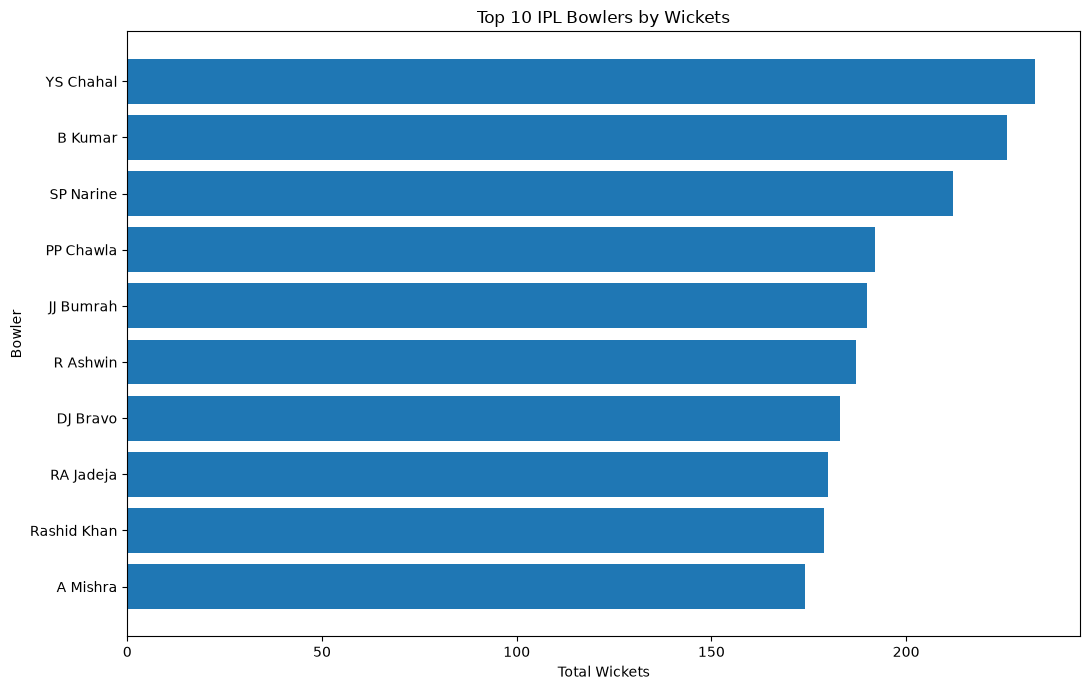

In [48]:

import matplotlib.pyplot as plt

top_10_bowlers = (
    bowler_wicket_totals
    .sort_values("total_wickets", ascending=False)
    .head(10)
    .sort_values("total_wickets", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_10_bowlers["bowler"],
    top_10_bowlers["total_wickets"]
)

plt.title("Top 10 IPL Bowlers by Wickets")
plt.xlabel("Total Wickets")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()


In [49]:

csk_bowler_wickets = con.sql("""
    WITH innings_wickets AS (
        SELECT
            match_id,
            season,
            innings,
            bowler,
            team,
            MAX(bowler_wickets) AS innings_wickets
        FROM dbt_prod.mart_bowler_spell
        WHERE bowler IS NOT NULL
        GROUP BY
            match_id,
            season,
            innings,
            bowler,
            team
    )
    SELECT
        bowler,
        SUM(innings_wickets) AS total_wickets,
        COUNT(DISTINCT match_id) AS matches_bowled
    FROM innings_wickets
    WHERE LOWER(team) LIKE '%chennai super kings%'
    GROUP BY bowler
    ORDER BY total_wickets DESC, matches_bowled DESC
""").df()

display(csk_bowler_wickets.head(15))


,bowler,total_wickets,matches_bowled
0,RA Jadeja,143.0,173
1,DJ Bravo,140.0,113
2,R Ashwin,97.0,103
3,DL Chahar,76.0,76
4,JA Morkel,76.0,75
5,SN Thakur,60.0,56
6,MM Sharma,58.0,48
7,M Pathirana,47.0,32
8,SB Jakati,45.0,48
9,M Muralitharan,44.0,40


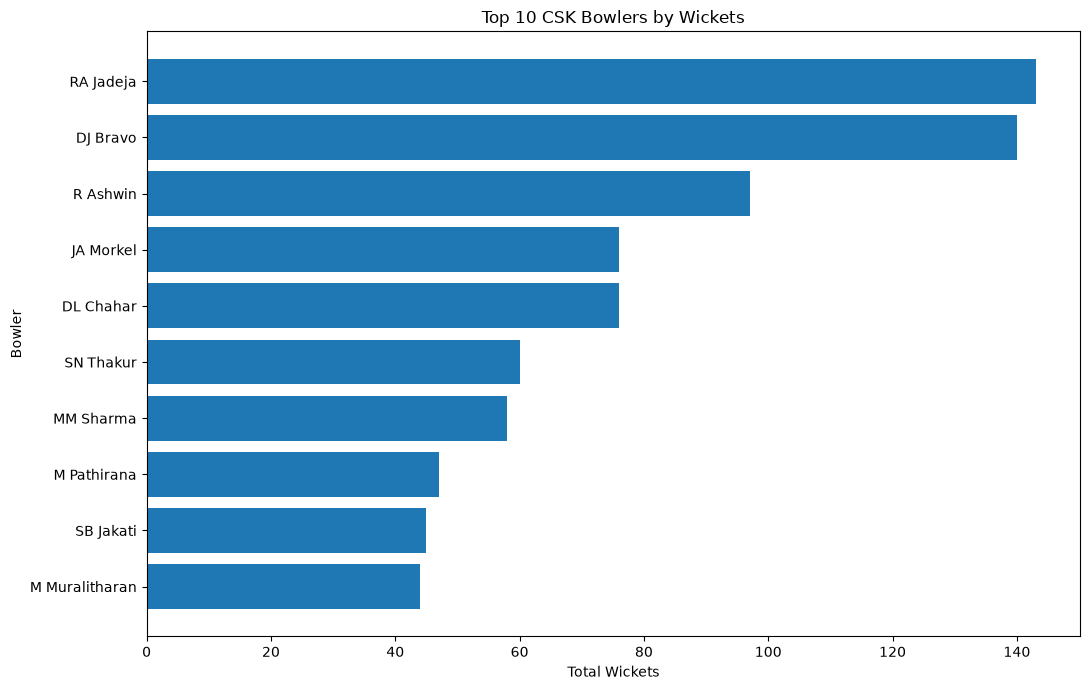

In [50]:

import matplotlib.pyplot as plt

top_csk_bowlers = (
    csk_bowler_wickets
    .sort_values("total_wickets", ascending=False)
    .head(10)
    .sort_values("total_wickets", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_csk_bowlers["bowler"],
    top_csk_bowlers["total_wickets"]
)

plt.title("Top 10 CSK Bowlers by Wickets")
plt.xlabel("Total Wickets")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()


In [51]:
csk_bowler_economy = con.sql("""
    WITH bowler_innings AS (
        SELECT
            match_id,
            season,
            innings,
            bowler,
            team,
            MAX(bowler_runs_conceded) AS runs_conceded,
            MAX(bowler_balls_bowled) AS legal_balls
        FROM dbt_prod.mart_bowler_spell
        WHERE bowler IS NOT NULL
          AND LOWER(team) LIKE '%chennai super kings%'
        GROUP BY match_id, season, innings, bowler, team
    )
    SELECT
        bowler,
        SUM(runs_conceded) AS total_runs_conceded,
        SUM(legal_balls) AS legal_balls,
        ROUND(
            6.0 * SUM(runs_conceded)
            / NULLIF(SUM(legal_balls), 0),
            2
        ) AS economy_rate,
        COUNT(DISTINCT match_id) AS matches_bowled
    FROM bowler_innings
    GROUP BY bowler
    HAVING SUM(legal_balls) > 0
    ORDER BY economy_rate ASC
""").df()

display(csk_bowler_economy.head(15))

,bowler,total_runs_conceded,legal_balls,economy_rate,matches_bowled
0,R Ravindra,7.0,12.0,3.50,2
1,PH Solanki,38.0,36.0,6.33,2
2,M Muralitharan,1004.0,943.0,6.39,40
3,R Ashwin,2463.0,2212.0,6.68,103
4,M Ntini,242.0,210.0,6.91,9
5,MJ Santner,422.0,366.0,6.92,18
6,S Badree,97.0,84.0,6.93,4
7,MM Ali,585.0,499.0,7.03,35
8,KMDN Kulasekara,120.0,102.0,7.06,5
9,Imran Tahir,711.0,600.0,7.11,27


In [52]:
con.sql("""
    SELECT
        bowler,
        match_id,
        innings,
        COUNT(*) AS delivery_rows,
        MIN(bowler_runs_conceded) AS min_runs_value,
        MAX(bowler_runs_conceded) AS max_runs_value,
        MIN(bowler_balls_bowled) AS min_balls_value,
        MAX(bowler_balls_bowled) AS max_balls_value
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(team) LIKE '%chennai super kings%'
      AND bowler IN ('RA Jadeja', 'R Ravindra', 'R Ashwin')
    GROUP BY bowler, match_id, innings
    ORDER BY bowler, match_id, innings
    LIMIT 15
""").df()

,bowler,match_id,innings,delivery_rows,min_runs_value,max_runs_value,min_balls_value,max_balls_value
0,R Ashwin,392234,2,24,2,13,1,24
1,R Ashwin,419110,1,26,1,26,1,24
2,R Ashwin,419113,2,24,0,22,1,24
3,R Ashwin,419116,1,25,0,40,1,24
4,R Ashwin,419121,1,24,2,32,1,24
5,R Ashwin,419123,1,24,4,40,1,24
6,R Ashwin,419142,2,26,1,22,0,24
7,R Ashwin,419147,2,25,0,13,1,24
8,R Ashwin,419153,1,25,0,16,1,24
9,R Ashwin,419155,2,24,1,24,1,24


In [53]:
csk_economy_check = con.sql("""
    SELECT
        bowler,
        COUNT(*) AS delivery_rows,
        SUM(bowler_runs_conceded) AS runs_conceded_sum,
        SUM(bowler_balls_bowled) AS balls_bowled_sum,
        MIN(bowler_runs_conceded) AS min_runs,
        MAX(bowler_runs_conceded) AS max_runs,
        MIN(bowler_balls_bowled) AS min_balls,
        MAX(bowler_balls_bowled) AS max_balls
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(team) LIKE '%chennai super kings%'
      AND bowler IN ('RA Jadeja', 'R Ashwin', 'R Ravindra')
    GROUP BY bowler
""").df()

display(csk_economy_check)

,bowler,delivery_rows,runs_conceded_sum,balls_bowled_sum,min_runs,max_runs,min_balls,max_balls
0,R Ashwin,2270,28076.0,26571.0,0,48,0,24
1,RA Jadeja,3233,41172.0,34752.0,0,50,0,24
2,R Ravindra,12,23.0,42.0,0,4,1,6


In [54]:
# Inspect the available delivery-level fields for calculating economy
print(
    con.sql("""
        DESCRIBE
        SELECT *
        FROM dbt_prod.mart_bowler_spell
    """).df()["column_name"].tolist()
)

['match_id', 'match_date', 'match_date_str', 'season', 'match_number', 'innings', 'innings_role', 'team', 'batting_team', 'over', 'ball', 'phase', 'bowler', 'bowler_id', 'batter', 'batter_id', 'non_striker', 'non_striker_id', 'bowler_runs_conceded', 'bowler_wickets', 'bowler_balls_bowled', 'bowler_overs_bowled', 'bowler_economy', 'bowler_dots', 'bowler_dot_ball_pct', 'bowler_extras', 'fours_conceded', 'sixes_conceded', 'balls_since_last_boundary', 'balls_since_last_wicket', 'wicket_streak', 'batter_runs', 'total_runs', 'wides', 'noballs', 'is_wicket', 'player_out', 'player_out_id', 'dismissal_kind']


In [55]:

csk_bowler_economy = con.sql("""
    SELECT
        bowler,
        SUM(bowler_runs_conceded) AS total_runs_conceded,

        SUM(
            CASE
                WHEN COALESCE(wides, 0) = 0
                 AND COALESCE(noballs, 0) = 0
                THEN 1
                ELSE 0
            END
        ) AS legal_balls,

        ROUND(
            6.0 * SUM(bowler_runs_conceded)
            / NULLIF(
                SUM(
                    CASE
                        WHEN COALESCE(wides, 0) = 0
                         AND COALESCE(noballs, 0) = 0
                        THEN 1
                        ELSE 0
                    END
                ),
                0
            ),
            2
        ) AS economy_rate,

        COUNT(DISTINCT match_id) AS matches_bowled

    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(team) LIKE '%chennai super kings%'
      AND bowler IS NOT NULL
    GROUP BY bowler
    ORDER BY economy_rate ASC
""").df()

display(csk_bowler_economy.head(15))


,bowler,total_runs_conceded,legal_balls,economy_rate,matches_bowled
0,R Ravindra,23.0,12.0,11.50,2
1,C Ganapathy,31.0,6.0,31.00,1
2,AF Milne,89.0,15.0,35.60,1
3,JM Kemp,327.0,44.0,44.59,5
4,V Shankar,45.0,6.0,45.00,1
5,SB Styris,47.0,6.0,47.00,1
6,AS Rajpoot,223.0,24.0,55.75,2
7,F du Plessis,56.0,6.0,56.00,1
8,MM Ali,4727.0,499.0,56.84,35
9,SK Raina,7495.0,776.0,57.95,59


In [56]:

con.sql("""
    SELECT
        bowler,
        match_id,
        innings,
        COUNT(*) AS delivery_rows,
        MIN(bowler_economy) AS min_economy,
        MAX(bowler_economy) AS max_economy
    FROM dbt_prod.mart_bowler_spell
    WHERE LOWER(team) LIKE '%chennai super kings%'
      AND bowler IN ('RA Jadeja', 'R Ashwin', 'MM Ali', 'SK Raina')
    GROUP BY bowler, match_id, innings
    ORDER BY bowler, match_id, innings
    LIMIT 12
""").df()


,bowler,match_id,innings,delivery_rows,min_economy,max_economy
0,MM Ali,1254059,2,19,4.00,11.29
1,MM Ali,1254065,1,18,0.00,6.46
2,MM Ali,1254069,2,18,0.00,2.33
3,MM Ali,1254080,1,12,6.00,18.00
4,MM Ali,1254084,2,6,0.00,3.00
5,MM Ali,1254089,2,14,5.14,24.00
6,MM Ali,1254091,1,6,3.00,6.00
7,MM Ali,1254104,2,18,2.00,6.00
8,MM Ali,1254110,2,18,0.00,14.00
9,MM Ali,1254114,1,25,0.00,7.04


In [57]:

con.sql("""
    SELECT
        match_id,
        innings,
        over,
        ball,
        bowler,
        batter_runs,
        total_runs,
        bowler_runs_conceded,
        wides,
        noballs,
        bowler_balls_bowled,
        bowler_economy
    FROM dbt_prod.mart_bowler_spell
    WHERE bowler = 'MM Ali'
      AND match_id = 1254059
    ORDER BY over, ball
    LIMIT 15
""").df()


,match_id,innings,over,ball,bowler,batter_runs,total_runs,bowler_runs_conceded,wides,noballs,bowler_balls_bowled,bowler_economy
0,1254059,2,8,1,MM Ali,1,1,1,0,0,1,6.00
1,1254059,2,8,2,MM Ali,1,1,2,0,0,2,6.00
2,1254059,2,8,3,MM Ali,0,0,2,0,0,3,4.00
3,1254059,2,8,4,MM Ali,1,1,3,0,0,4,4.50
4,1254059,2,8,5,MM Ali,1,1,4,0,0,5,4.80
5,1254059,2,8,6,MM Ali,1,1,5,0,0,6,5.00
6,1254059,2,10,1,MM Ali,6,6,11,0,0,7,9.43
7,1254059,2,10,2,MM Ali,1,1,12,0,0,8,9.00
8,1254059,2,10,3,MM Ali,1,1,13,0,0,9,8.67
9,1254059,2,10,4,MM Ali,0,0,13,0,0,10,7.80


In [58]:

csk_bowler_economy = con.sql("""
    WITH innings_totals AS (
        SELECT
            match_id,
            innings,
            bowler,
            MAX(bowler_runs_conceded) AS runs_conceded,
            MAX(bowler_balls_bowled) AS legal_balls
        FROM dbt_prod.mart_bowler_spell
        WHERE LOWER(team) LIKE '%chennai super kings%'
          AND bowler IS NOT NULL
        GROUP BY match_id, innings, bowler
    )
    SELECT
        bowler,
        SUM(runs_conceded) AS total_runs_conceded,
        SUM(legal_balls) AS legal_balls,
        ROUND(
            6.0 * SUM(runs_conceded)
            / NULLIF(SUM(legal_balls), 0),
            2
        ) AS economy_rate,
        COUNT(DISTINCT match_id) AS matches_bowled
    FROM innings_totals
    GROUP BY bowler
    HAVING SUM(legal_balls) > 0
    ORDER BY economy_rate ASC
""").df()

display(csk_bowler_economy.head(15))


,bowler,total_runs_conceded,legal_balls,economy_rate,matches_bowled
0,R Ravindra,7.0,12.0,3.50,2
1,PH Solanki,38.0,36.0,6.33,2
2,M Muralitharan,1004.0,943.0,6.39,40
3,R Ashwin,2463.0,2212.0,6.68,103
4,M Ntini,242.0,210.0,6.91,9
5,MJ Santner,422.0,366.0,6.92,18
6,S Badree,97.0,84.0,6.93,4
7,MM Ali,585.0,499.0,7.03,35
8,KMDN Kulasekara,120.0,102.0,7.06,5
9,Imran Tahir,711.0,600.0,7.11,27


In [59]:
con.sql("""
    SELECT table_schema, table_name
    FROM information_schema.tables
    WHERE table_schema = 'ipl_cricket'
    ORDER BY table_name
""").df()

,table_schema,table_name
0,ipl_cricket,batter_scorecard
1,ipl_cricket,bowler_scorecard
2,ipl_cricket,deliveries
3,ipl_cricket,ipl_2026_schedule
4,ipl_cricket,match_players
5,ipl_cricket,matches
6,ipl_cricket,people
7,ipl_cricket,squads


In [60]:
con.sql("""
    DESCRIBE
    SELECT *
    FROM ipl_cricket.deliveries
""").df()

,column_name,column_type,null,key,default,extra
0,match_id,BIGINT,YES,None,None,None
1,date,VARCHAR,YES,None,None,None
2,venue,VARCHAR,YES,None,None,None
3,city,VARCHAR,YES,None,None,None
4,team1,VARCHAR,YES,None,None,None
5,team2,VARCHAR,YES,None,None,None
6,season,VARCHAR,YES,None,None,None
7,innings,BIGINT,YES,None,None,None
8,batting_team,VARCHAR,YES,None,None,None
9,bowling_team,VARCHAR,YES,None,None,None


In [61]:

csk_bowler_economy = con.sql("""
    WITH bowler_match_innings AS (
        SELECT
            match_id,
            innings,
            bowler,
            SUM(
                batter_runs
                + COALESCE(wides, 0)
                + COALESCE(noballs, 0)
            ) AS runs_conceded,
            SUM(
                CASE
                    WHEN COALESCE(wides, 0) = 0
                     AND COALESCE(noballs, 0) = 0
                    THEN 1
                    ELSE 0
                END
            ) AS legal_balls
        FROM ipl_cricket.deliveries
        WHERE LOWER(bowling_team) LIKE '%chennai super kings%'
          AND bowler IS NOT NULL
        GROUP BY match_id, innings, bowler
    )
    SELECT
        bowler,
        SUM(runs_conceded) AS total_runs_conceded,
        SUM(legal_balls) AS legal_balls,
        ROUND(
            6.0 * SUM(runs_conceded)
            / NULLIF(SUM(legal_balls), 0),
            2
        ) AS economy_rate,
        COUNT(DISTINCT match_id) AS matches_bowled
    FROM bowler_match_innings
    GROUP BY bowler
    HAVING SUM(legal_balls) > 0
    ORDER BY economy_rate ASC
""").df()

display(csk_bowler_economy.head(15))


,bowler,total_runs_conceded,legal_balls,economy_rate,matches_bowled
0,R Ravindra,7.0,12.0,3.50,2
1,PH Solanki,38.0,36.0,6.33,2
2,M Muralitharan,1004.0,940.0,6.41,40
3,R Ashwin,2463.0,2212.0,6.68,103
4,M Ntini,242.0,210.0,6.91,9
5,MJ Santner,422.0,366.0,6.92,18
6,S Badree,97.0,84.0,6.93,4
7,MM Ali,585.0,499.0,7.03,35
8,KMDN Kulasekara,120.0,102.0,7.06,5
9,Imran Tahir,711.0,600.0,7.11,27


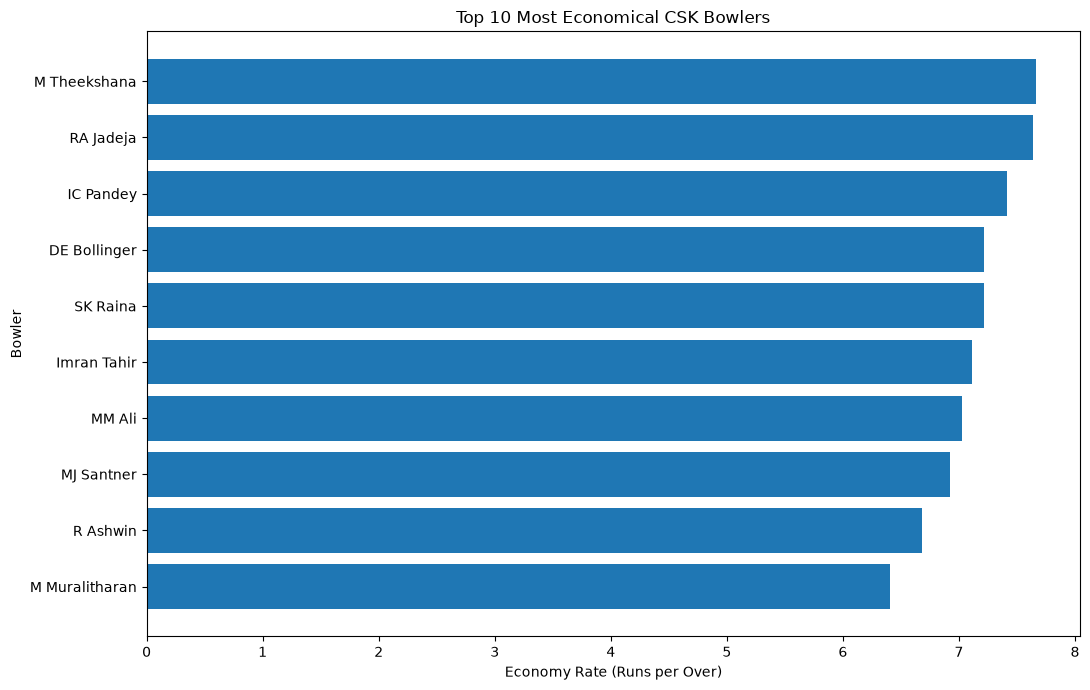

In [62]:

import matplotlib.pyplot as plt

# Select the 10 lowest economy rates
# Require at least 10 matches for a fairer comparison
top_csk_economy = (
    csk_bowler_economy[
        csk_bowler_economy["matches_bowled"] >= 10
    ]
    .sort_values("economy_rate", ascending=True)
    .head(10)
    .sort_values("economy_rate", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_csk_economy["bowler"],
    top_csk_economy["economy_rate"]
)

plt.title("Top 10 Most Economical CSK Bowlers")
plt.xlabel("Economy Rate (Runs per Over)")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()


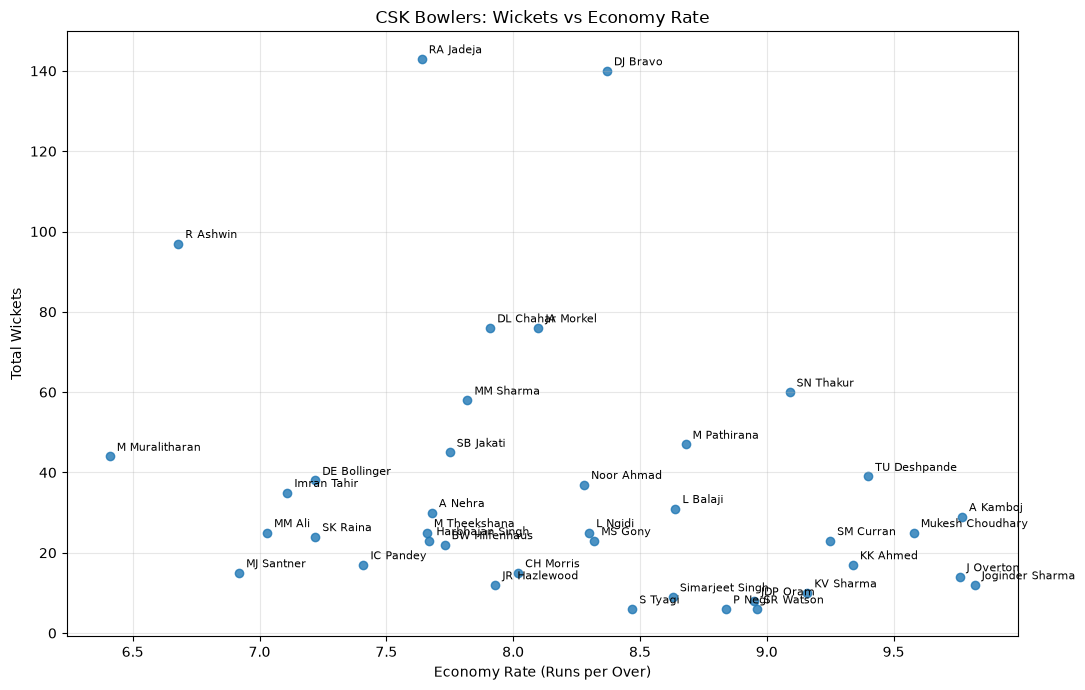

In [63]:

import matplotlib.pyplot as plt

# Combine wicket totals and economy rates
csk_bowler_comparison = csk_bowler_wickets.merge(
    csk_bowler_economy[
        ["bowler", "economy_rate", "matches_bowled"]
    ],
    on="bowler",
    how="inner",
    suffixes=("_wickets", "_economy")
)

# Keep bowlers with at least 10 matches
csk_bowler_comparison = csk_bowler_comparison[
    csk_bowler_comparison["matches_bowled_economy"] >= 10
].copy()

plt.figure(figsize=(11, 7))

plt.scatter(
    csk_bowler_comparison["economy_rate"],
    csk_bowler_comparison["total_wickets"],
    alpha=0.8
)

for _, row in csk_bowler_comparison.iterrows():
    plt.annotate(
        row["bowler"],
        (row["economy_rate"], row["total_wickets"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.title("CSK Bowlers: Wickets vs Economy Rate")
plt.xlabel("Economy Rate (Runs per Over)")
plt.ylabel("Total Wickets")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


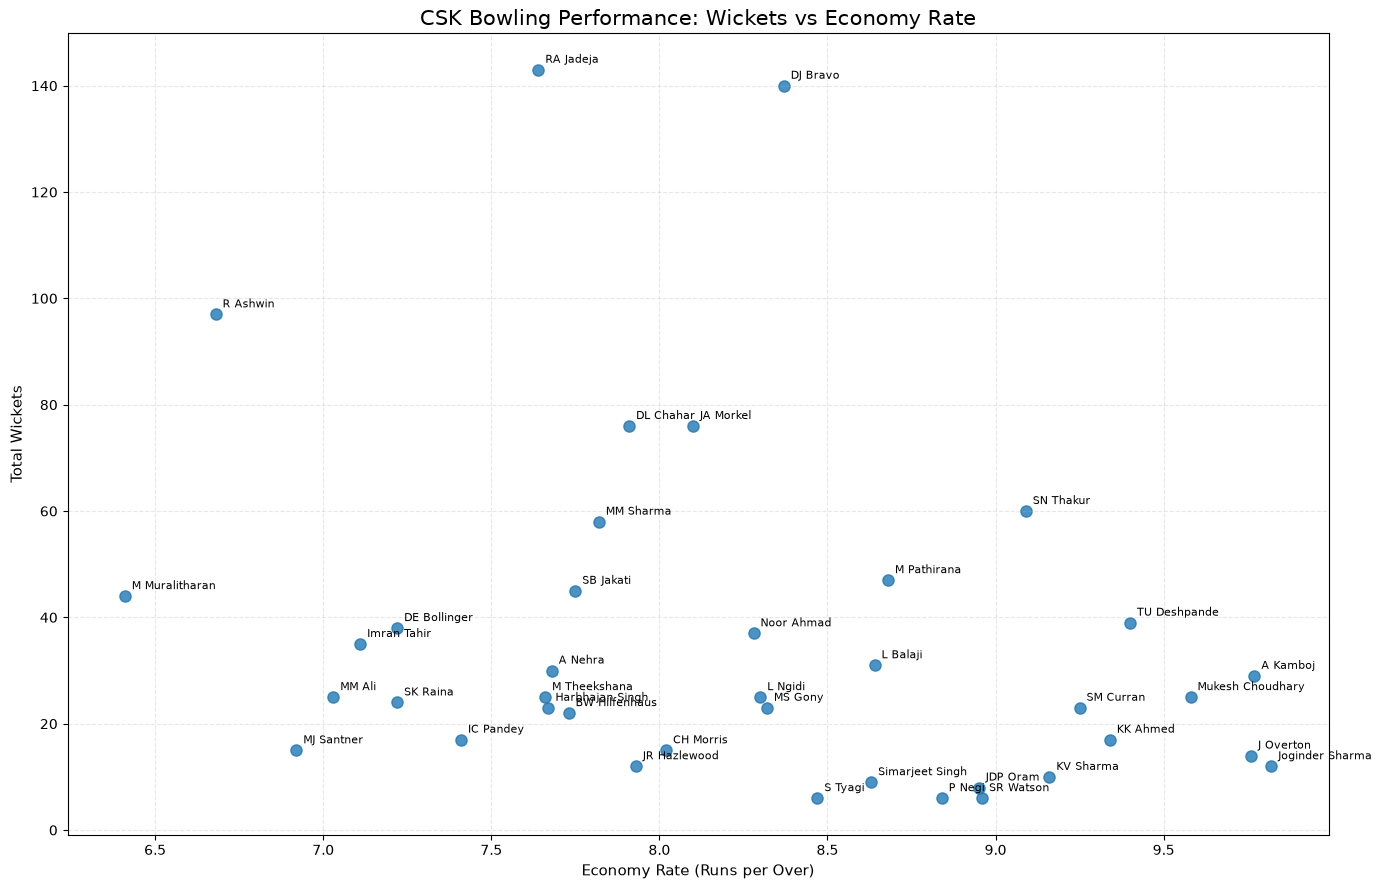

In [64]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 9))

plt.scatter(
    csk_bowler_comparison["economy_rate"],
    csk_bowler_comparison["total_wickets"],
    s=65,
    alpha=0.8
)

for _, row in csk_bowler_comparison.iterrows():
    plt.annotate(
        row["bowler"],
        (row["economy_rate"], row["total_wickets"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(
    "CSK Bowling Performance: Wickets vs Economy Rate",
    fontsize=15
)
plt.xlabel("Economy Rate (Runs per Over)", fontsize=11)
plt.ylabel("Total Wickets", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [65]:
%pip install adjustText

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


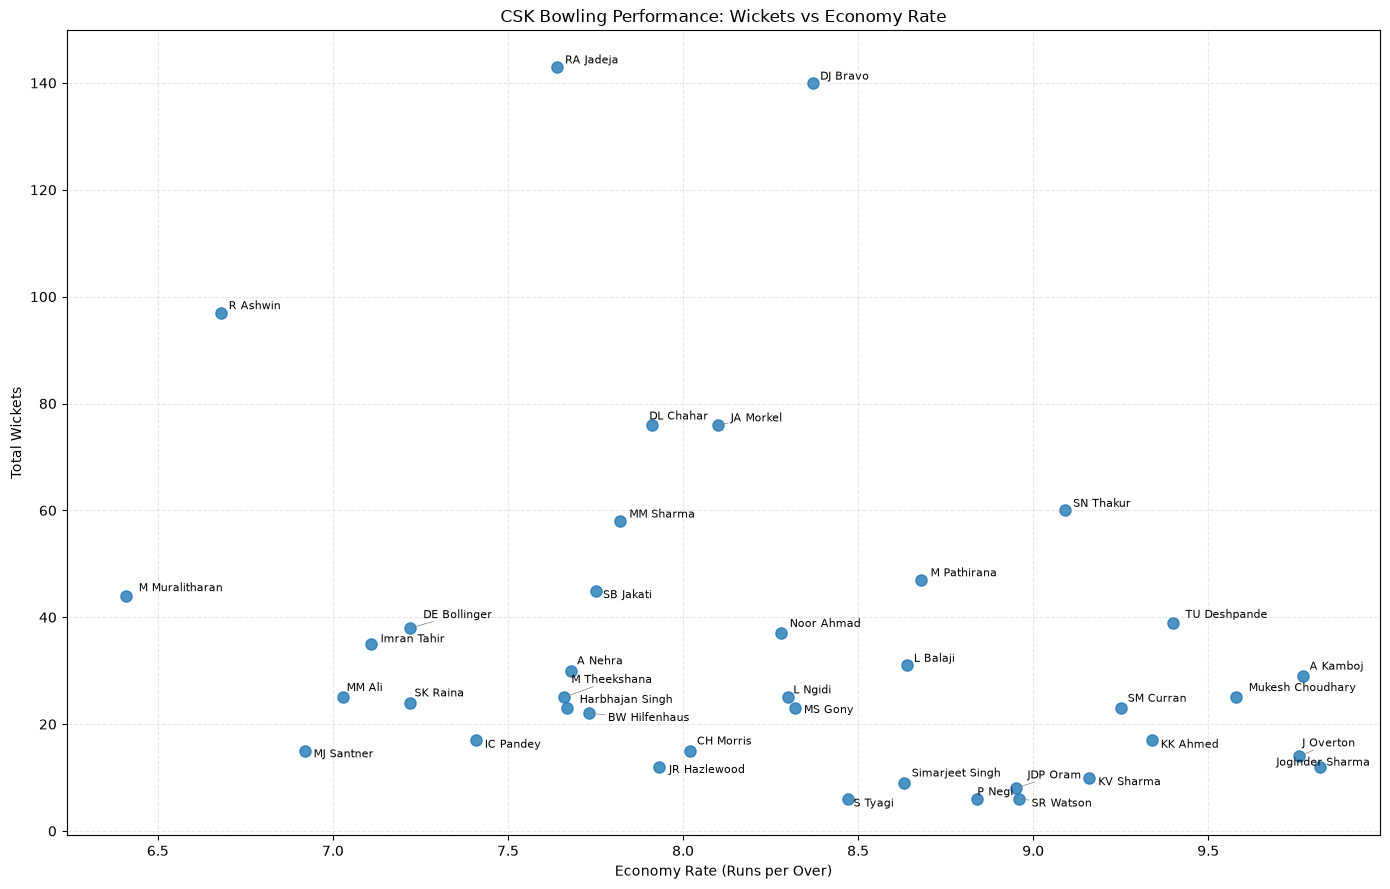

In [66]:

import matplotlib.pyplot as plt
from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(14, 9))

ax.scatter(
    csk_bowler_comparison["economy_rate"],
    csk_bowler_comparison["total_wickets"],
    s=65,
    alpha=0.8
)

texts = []

for _, row in csk_bowler_comparison.iterrows():
    texts.append(
        ax.text(
            row["economy_rate"],
            row["total_wickets"],
            row["bowler"],
            fontsize=8
        )
    )

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
)

ax.set_title("CSK Bowling Performance: Wickets vs Economy Rate")
ax.set_xlabel("Economy Rate (Runs per Over)")
ax.set_ylabel("Total Wickets")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [67]:

csk_top_run_scorers = con.sql("""
    SELECT
        batter AS player,
        SUM(batter_runs) AS total_runs,
        COUNT(DISTINCT match_id) AS matches_played,
        COUNT(*) FILTER (WHERE batter_runs = 4) AS fours,
        COUNT(*) FILTER (WHERE batter_runs = 6) AS sixes
    FROM ipl_cricket.deliveries
    WHERE LOWER(batting_team) LIKE '%chennai super kings%'
    GROUP BY batter
    ORDER BY total_runs DESC
    LIMIT 15
""").df()

display(csk_top_run_scorers)


,player,total_runs,matches_played,fours,sixes
0,MS Dhoni,4865.0,214,342,234
1,SK Raina,4695.0,171,425,181
2,RD Gaikwad,2839.0,84,260,107
3,F du Plessis,2721.0,86,248,87
4,RA Jadeja,2198.0,135,161,83
5,AT Rayudu,1932.0,80,154,94
6,MEK Hussey,1768.0,49,181,45
7,S Dube,1730.0,65,108,115
8,M Vijay,1708.0,69,150,68
9,S Badrinath,1441.0,65,154,28


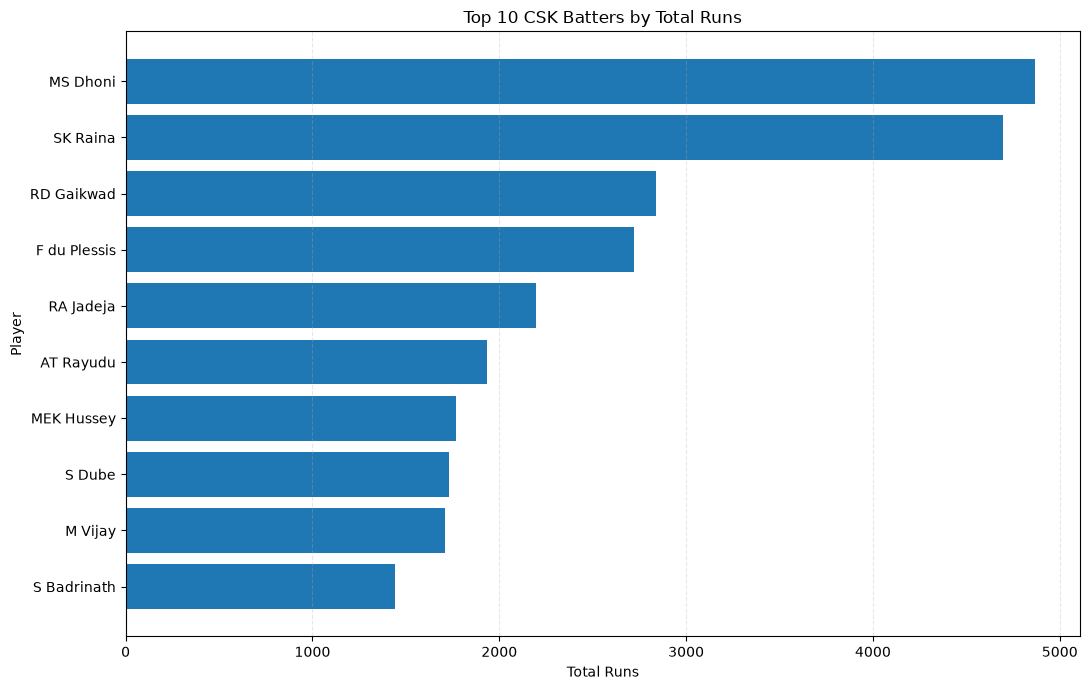

In [68]:

import matplotlib.pyplot as plt

top_10_batters = (
    csk_top_run_scorers
    .head(10)
    .sort_values("total_runs", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_10_batters["player"],
    top_10_batters["total_runs"]
)

plt.title("Top 10 CSK Batters by Total Runs")
plt.xlabel("Total Runs")
plt.ylabel("Player")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [69]:

csk_batting_strike_rate = con.sql("""
    SELECT
        batter AS player,
        SUM(batter_runs) AS total_runs,
        COUNT(*) FILTER (
            WHERE COALESCE(wides, 0) = 0
        ) AS balls_faced,
        ROUND(
            100.0 * SUM(batter_runs)
            / NULLIF(
                COUNT(*) FILTER (
                    WHERE COALESCE(wides, 0) = 0
                ),
                0
            ),
            2
        ) AS strike_rate,
        COUNT(DISTINCT match_id) AS matches_played
    FROM ipl_cricket.deliveries
    WHERE LOWER(batting_team) LIKE '%chennai super kings%'
    GROUP BY batter
    HAVING COUNT(DISTINCT match_id) >= 10
    ORDER BY strike_rate DESC
""").df()

display(csk_batting_strike_rate.head(15))


,player,total_runs,balls_faced,strike_rate,matches_played
0,Urvil Patel,197.0,96,205.21,10
1,A Mhatre,441.0,240,183.75,13
2,SV Samson,477.0,288,165.63,14
3,D Brevis,376.0,243,154.73,14
4,S Dube,1730.0,1133,152.69,65
5,AM Rahane,568.0,385,147.53,23
6,JA Morkel,828.0,572,144.76,58
7,R Ravindra,413.0,287,143.90,18
8,DJ Mitchell,318.0,223,142.60,13
9,SM Curran,356.0,254,140.16,20


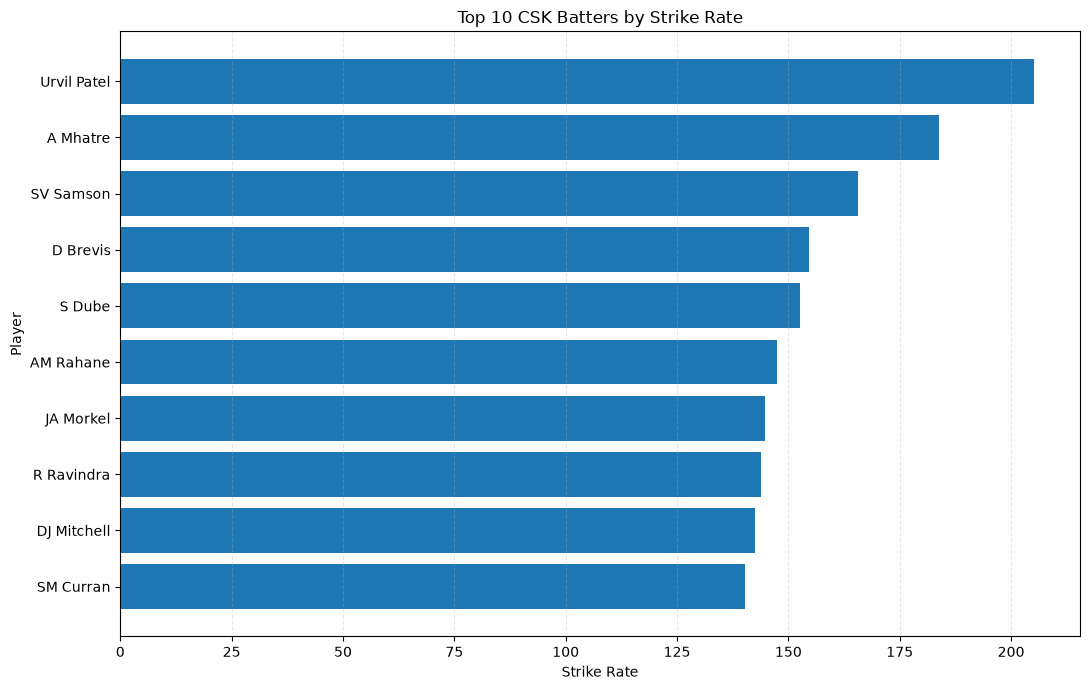

In [70]:

import matplotlib.pyplot as plt

top_10_strike_rate = (
    csk_batting_strike_rate
    .head(10)
    .sort_values("strike_rate", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_10_strike_rate["player"],
    top_10_strike_rate["strike_rate"]
)

plt.title("Top 10 CSK Batters by Strike Rate")
plt.xlabel("Strike Rate")
plt.ylabel("Player")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [71]:

csk_batting_consistency = con.sql("""
    WITH innings_scores AS (
        SELECT
            match_id,
            innings,
            batter AS player,
            SUM(batter_runs) AS runs_in_innings
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY match_id, innings, batter
    )
    SELECT
        player,
        COUNT(*) AS innings_batted,
        SUM(CASE WHEN runs_in_innings >= 30 THEN 1 ELSE 0 END) AS scores_30_plus,
        SUM(CASE WHEN runs_in_innings >= 50 THEN 1 ELSE 0 END) AS fifties_plus,
        SUM(CASE WHEN runs_in_innings >= 100 THEN 1 ELSE 0 END) AS hundreds,
        ROUND(AVG(runs_in_innings), 2) AS average_runs_per_innings
    FROM innings_scores
    GROUP BY player
    HAVING COUNT(*) >= 10
    ORDER BY scores_30_plus DESC, fifties_plus DESC
""").df()

display(csk_batting_consistency.head(15))


,player,innings_batted,scores_30_plus,fifties_plus,hundreds,average_runs_per_innings
0,SK Raina,172,66.0,34.0,1.0,27.30
1,MS Dhoni,214,61.0,22.0,0.0,22.73
2,RD Gaikwad,84,41.0,24.0,2.0,33.80
3,F du Plessis,86,41.0,20.0,0.0,31.64
4,MEK Hussey,49,25.0,14.0,1.0,36.08
5,AT Rayudu,80,25.0,9.0,1.0,24.15
6,S Dube,65,24.0,9.0,0.0,26.62
7,S Badrinath,65,23.0,11.0,0.0,22.17
8,M Vijay,69,23.0,9.0,2.0,24.75
9,RA Jadeja,135,19.0,5.0,0.0,16.28


In [72]:

csk_batting_consistency = con.sql("""
    WITH innings_scores AS (
        SELECT
            match_id,
            innings,
            batter AS player,
            SUM(batter_runs) AS runs_in_innings
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY match_id, innings, batter
    )
    SELECT
        player,
        COUNT(*) AS innings_batted,
        SUM(CASE WHEN runs_in_innings >= 30 THEN 1 ELSE 0 END)
            AS innings_30_plus,
        SUM(CASE WHEN runs_in_innings >= 50 THEN 1 ELSE 0 END)
            AS innings_50_plus,
        SUM(CASE WHEN runs_in_innings >= 100 THEN 1 ELSE 0 END)
            AS innings_100_plus,
        ROUND(AVG(runs_in_innings), 2)
            AS average_runs_per_batter_innings
    FROM innings_scores
    GROUP BY player
    HAVING COUNT(*) >= 10
    ORDER BY innings_30_plus DESC, innings_50_plus DESC
""").df()

display(csk_batting_consistency.head(15))


,player,innings_batted,innings_30_plus,innings_50_plus,innings_100_plus,average_runs_per_batter_innings
0,SK Raina,172,66.0,34.0,1.0,27.30
1,MS Dhoni,214,61.0,22.0,0.0,22.73
2,RD Gaikwad,84,41.0,24.0,2.0,33.80
3,F du Plessis,86,41.0,20.0,0.0,31.64
4,MEK Hussey,49,25.0,14.0,1.0,36.08
5,AT Rayudu,80,25.0,9.0,1.0,24.15
6,S Dube,65,24.0,9.0,0.0,26.62
7,S Badrinath,65,23.0,11.0,0.0,22.17
8,M Vijay,69,23.0,9.0,2.0,24.75
9,RA Jadeja,135,19.0,5.0,0.0,16.28


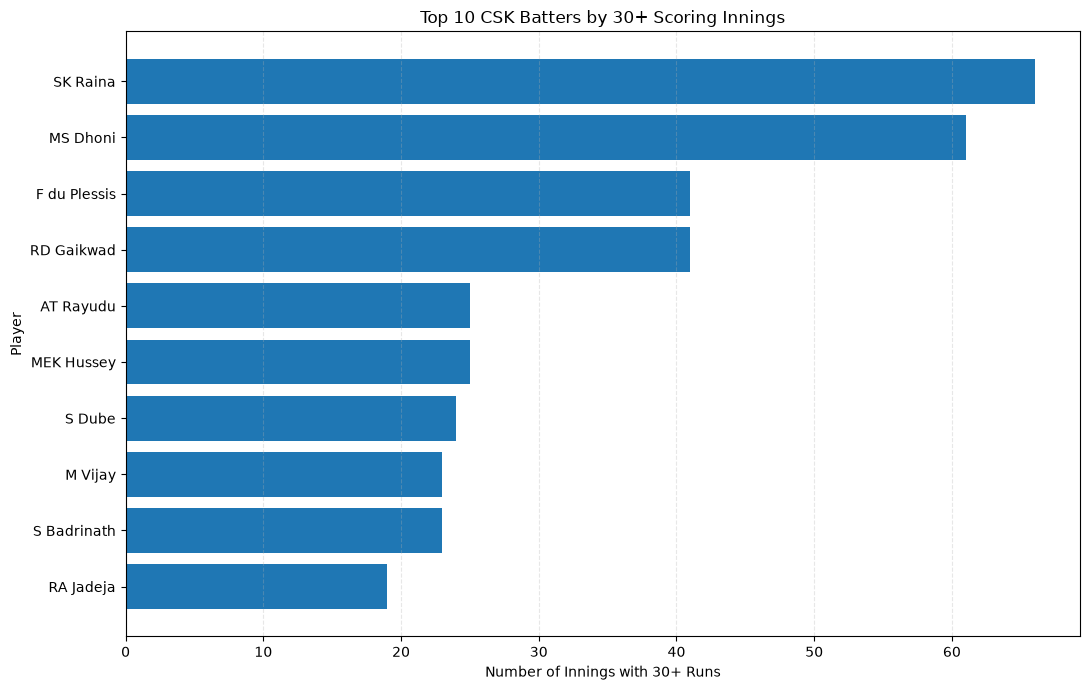

In [73]:

import matplotlib.pyplot as plt

top_10_consistent = (
    csk_batting_consistency
    .sort_values("innings_30_plus", ascending=False)
    .head(10)
    .sort_values("innings_30_plus", ascending=True)
)

plt.figure(figsize=(11, 7))

plt.barh(
    top_10_consistent["player"],
    top_10_consistent["innings_30_plus"]
)

plt.title("Top 10 CSK Batters by 30+ Scoring Innings")
plt.xlabel("Number of Innings with 30+ Runs")
plt.ylabel("Player")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [74]:

csk_batting_summary = (
    csk_top_run_scorers[
        ["player", "total_runs", "matches_played", "fours", "sixes"]
    ]
    .merge(
        csk_batting_strike_rate[["player", "strike_rate"]],
        on="player",
        how="left"
    )
    .merge(
        csk_batting_consistency[["player", "innings_30_plus"]],
        on="player",
        how="left"
    )
    .sort_values("total_runs", ascending=False)
    .reset_index(drop=True)
)

display(csk_batting_summary.head(15))


,player,total_runs,matches_played,fours,sixes,strike_rate,innings_30_plus
0,MS Dhoni,4865.0,214,342,234,139.12,61.0
1,SK Raina,4695.0,171,425,181,137.00,66.0
2,RD Gaikwad,2839.0,84,260,107,135.64,41.0
3,F du Plessis,2721.0,86,248,87,131.45,41.0
4,RA Jadeja,2198.0,135,161,83,136.10,19.0
5,AT Rayudu,1932.0,80,154,94,129.32,25.0
6,MEK Hussey,1768.0,49,181,45,123.64,25.0
7,S Dube,1730.0,65,108,115,152.69,24.0
8,M Vijay,1708.0,69,150,68,125.13,23.0
9,S Badrinath,1441.0,65,154,28,118.89,23.0


In [75]:
print(csk_batting_summary.columns.tolist())
display(csk_batting_summary.head(5).to_string(index=False))

['player', 'total_runs', 'matches_played', 'fours', 'sixes', 'strike_rate', 'innings_30_plus']


'      player  total_runs  matches_played  fours  sixes  strike_rate  innings_30_plus\n    MS Dhoni      4865.0             214    342    234       139.12             61.0\n    SK Raina      4695.0             171    425    181       137.00             66.0\n  RD Gaikwad      2839.0              84    260    107       135.64             41.0\nF du Plessis      2721.0              86    248     87       131.45             41.0\n   RA Jadeja      2198.0             135    161     83       136.10             19.0'

In [76]:
import os

output_dir = "outputs"
os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "csk_batting_summary.csv"
)

csk_batting_summary.to_csv(output_path, index=False)

print(f"Saved successfully: {os.path.abspath(output_path)}")

Saved successfully: C:\Users\Raghuvanshii38\outputs\csk_batting_summary.csv


Data validation and quality

In [77]:

# PHASE 1 — DATA VALIDATION
# Check match table filenames

import duckdb
import pandas as pd

match_filename_check = con.sql("""
    SELECT
        COUNT(*) AS match_rows,
        COUNT(DISTINCT filename) AS distinct_filenames,
        COUNT(*) FILTER (
            WHERE filename IS NULL
        ) AS missing_filenames
    FROM ipl_cricket.matches
""").df()

print("MATCH FILENAME VALIDATION")
display(match_filename_check)


MATCH FILENAME VALIDATION


,match_rows,distinct_filenames,missing_filenames
0,1243,1243,0


In [78]:
con.sql("""
    DESCRIBE
    SELECT *
    FROM ipl_cricket.matches
""").df()

,column_name,column_type,null,key,default,extra
0,filename,VARCHAR,YES,None,None,None
1,season,VARCHAR,YES,None,None,None
2,match_number,DOUBLE,YES,None,None,None
3,date,VARCHAR,YES,None,None,None
4,team1,VARCHAR,YES,None,None,None
5,team2,VARCHAR,YES,None,None,None
6,city,VARCHAR,YES,None,None,None
7,venue,VARCHAR,YES,None,None,None
8,neutral_venue,DOUBLE,YES,None,None,None
9,toss_winner,VARCHAR,YES,None,None,None


In [79]:
# Inspect match filenames and their associated metadata

match_samples = con.sql("""
    SELECT
        filename,
        season,
        match_number,
        date,
        team1,
        team2
    FROM ipl_cricket.matches
    ORDER BY date
    LIMIT 10
""").df()

display(match_samples)

,filename,season,match_number,date,team1,team2
0,335982.yaml,2007/08,1.0,2008-04-18,Royal Challengers Bangalore,Kolkata Knight Riders
1,335983.yaml,2007/08,2.0,2008-04-19,Kings XI Punjab,Chennai Super Kings
2,335984.yaml,2007/08,3.0,2008-04-19,Delhi Daredevils,Rajasthan Royals
3,335985.yaml,2007/08,5.0,2008-04-20,Mumbai Indians,Royal Challengers Bangalore
4,335986.yaml,2007/08,4.0,2008-04-20,Kolkata Knight Riders,Deccan Chargers
5,335987.yaml,2007/08,6.0,2008-04-21,Rajasthan Royals,Kings XI Punjab
6,335988.yaml,2007/08,7.0,2008-04-22,Deccan Chargers,Delhi Daredevils
7,335989.yaml,2007/08,8.0,2008-04-23,Chennai Super Kings,Mumbai Indians
8,335990.yaml,2007/08,9.0,2008-04-24,Deccan Chargers,Rajasthan Royals
9,335991.yaml,2007/08,10.0,2008-04-25,Kings XI Punjab,Mumbai Indians


In [80]:

# Verify whether raw match filenames map to modeled match IDs

filename_mapping_check = con.sql("""
    SELECT
        r.filename AS raw_filename,
        r.season AS raw_season,
        r.team1 AS raw_team1,
        r.team2 AS raw_team2,
        f.match_id AS modeled_match_id,
        f.filename AS modeled_filename,
        f.season AS modeled_season
    FROM ipl_cricket.matches r
    LEFT JOIN dbt_prod.fct_matches f
        ON r.filename = f.filename
    ORDER BY r.date
    LIMIT 15
""").df()

display(filename_mapping_check)

# Count unmatched raw match filenames
unmatched_filename_count = con.sql("""
    SELECT COUNT(*) AS unmatched_raw_matches
    FROM ipl_cricket.matches r
    LEFT JOIN dbt_prod.fct_matches f
        ON r.filename = f.filename
    WHERE f.filename IS NULL
""").df()

print("UNMATCHED RAW MATCHES")
display(unmatched_filename_count)


,raw_filename,raw_season,raw_team1,raw_team2,modeled_match_id,modeled_filename,modeled_season
0,335982.yaml,2007/08,Royal Challengers Bangalore,Kolkata Knight Riders,335982,335982.yaml,2007/08
1,335983.yaml,2007/08,Kings XI Punjab,Chennai Super Kings,335983,335983.yaml,2007/08
2,335984.yaml,2007/08,Delhi Daredevils,Rajasthan Royals,335984,335984.yaml,2007/08
3,335985.yaml,2007/08,Mumbai Indians,Royal Challengers Bangalore,335985,335985.yaml,2007/08
4,335986.yaml,2007/08,Kolkata Knight Riders,Deccan Chargers,335986,335986.yaml,2007/08
5,335987.yaml,2007/08,Rajasthan Royals,Kings XI Punjab,335987,335987.yaml,2007/08
6,335988.yaml,2007/08,Deccan Chargers,Delhi Daredevils,335988,335988.yaml,2007/08
7,335989.yaml,2007/08,Chennai Super Kings,Mumbai Indians,335989,335989.yaml,2007/08
8,335990.yaml,2007/08,Deccan Chargers,Rajasthan Royals,335990,335990.yaml,2007/08
9,335991.yaml,2007/08,Kings XI Punjab,Mumbai Indians,335991,335991.yaml,2007/08


UNMATCHED RAW MATCHES


,unmatched_raw_matches
0,1


In [81]:
unmatched_match = con.sql("""
    SELECT
        r.filename,
        r.season,
        r.match_number,
        r.date,
        r.team1,
        r.team2,
        r.venue,
        r.result,
        r.method,
        r.winner
    FROM ipl_cricket.matches r
    LEFT JOIN dbt_prod.fct_matches f
        ON r.filename = f.filename
    WHERE f.filename IS NULL
""").df()

display(unmatched_match)

,filename,season,match_number,date,team1,team2,venue,result,method,winner
0,1473495.yaml,2025,58.0,2025-05-08,Punjab Kings,Delhi Capitals,"Himachal Pradesh Cricket Association Stadium, ...",no result,None,None


In [82]:
abandoned_match_check = con.sql("""
    SELECT
        m.filename,
        m.season,
        m.date,
        m.team1,
        m.team2,
        m.result,
        COUNT(d.match_id) AS delivery_rows,
        COUNT(DISTINCT d.match_id) AS distinct_delivery_match_ids
    FROM ipl_cricket.matches m
    LEFT JOIN ipl_cricket.deliveries d
        ON TRY_CAST(
            REGEXP_EXTRACT(m.filename, '([0-9]+)', 1)
            AS BIGINT
        ) = d.match_id
    WHERE m.filename = '1473495.yaml'
    GROUP BY
        m.filename, m.season, m.date,
        m.team1, m.team2, m.result
""").df()

display(abandoned_match_check)

,filename,season,date,team1,team2,result,delivery_rows,distinct_delivery_match_ids
0,1473495.yaml,2025,2025-05-08,Punjab Kings,Delhi Capitals,no result,63,1


In [83]:
match_reconciliation = con.sql("""
    WITH raw_matches AS (
        SELECT
            filename,
            TRY_CAST(
                REGEXP_EXTRACT(filename, '([0-9]+)', 1)
                AS BIGINT
            ) AS match_id,
            season,
            team1,
            team2,
            result
        FROM ipl_cricket.matches
    ),
    delivery_matches AS (
        SELECT
            match_id,
            COUNT(*) AS delivery_rows
        FROM ipl_cricket.deliveries
        GROUP BY match_id
    )
    SELECT
        COUNT(*) AS raw_match_count,
        COUNT(*) FILTER (
            WHERE f.filename IS NOT NULL
        ) AS modeled_match_count,
        COUNT(*) FILTER (
            WHERE f.filename IS NULL
        ) AS unmatched_raw_match_count,
        COUNT(*) FILTER (
            WHERE d.match_id IS NOT NULL
        ) AS matches_with_deliveries,
        COUNT(*) FILTER (
            WHERE f.filename IS NULL
              AND d.match_id IS NOT NULL
        ) AS unmatched_matches_with_deliveries,
        SUM(
            CASE
                WHEN f.filename IS NULL
                 AND d.match_id IS NOT NULL
                THEN d.delivery_rows
                ELSE 0
            END
        ) AS deliveries_in_unmatched_matches
    FROM raw_matches r
    LEFT JOIN dbt_prod.fct_matches f
        ON r.filename = f.filename
    LEFT JOIN delivery_matches d
        ON r.match_id = d.match_id
""").df()

display(match_reconciliation)

,raw_match_count,modeled_match_count,unmatched_raw_match_count,matches_with_deliveries,unmatched_matches_with_deliveries,deliveries_in_unmatched_matches
0,1243,1242,1,1243,1,63.0


In [84]:
audit_counts = con.sql("""
    SELECT
        (SELECT COUNT(*)
         FROM ipl_cricket.matches) AS raw_match_count,

        (SELECT COUNT(*)
         FROM dbt_prod.fct_matches) AS modeled_match_count,

        (SELECT COUNT(DISTINCT match_id)
         FROM ipl_cricket.deliveries) AS matches_with_deliveries,

        (SELECT COUNT(*)
         FROM ipl_cricket.deliveries) AS total_delivery_rows
""").df()

display(audit_counts)

,raw_match_count,modeled_match_count,matches_with_deliveries,total_delivery_rows
0,1243,1242,1243,295732


In [85]:
print(audit_counts.to_dict(orient="records")[0])

{'raw_match_count': 1243, 'modeled_match_count': 1242, 'matches_with_deliveries': 1243, 'total_delivery_rows': 295732}


In [86]:
delivery_id_audit = con.sql("""
    WITH raw_match_ids AS (
        SELECT
            TRY_CAST(
                REGEXP_EXTRACT(filename, '([0-9]+)', 1)
                AS BIGINT
            ) AS match_id
        FROM ipl_cricket.matches
    ),
    delivery_match_ids AS (
        SELECT DISTINCT match_id
        FROM ipl_cricket.deliveries
    )
    SELECT
        COUNT(*) AS distinct_delivery_match_ids,
        COUNT(*) FILTER (
            WHERE r.match_id IS NOT NULL
        ) AS matched_to_raw_match,
        COUNT(*) FILTER (
            WHERE r.match_id IS NULL
        ) AS delivery_ids_missing_from_raw_matches
    FROM delivery_match_ids d
    LEFT JOIN raw_match_ids r
        ON d.match_id = r.match_id
""").df()

# 1. Delivery data quality audit
delivery_quality = con.sql("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (WHERE match_id IS NULL) AS missing_match_id,
        COUNT(*) FILTER (WHERE innings IS NULL) AS missing_innings,
        COUNT(*) FILTER (WHERE batter IS NULL) AS missing_batter,
        COUNT(*) FILTER (WHERE bowler IS NULL) AS missing_bowler,
        COUNT(*) FILTER (WHERE batter_runs IS NULL) AS missing_batter_runs,
        COUNT(*) FILTER (WHERE total_runs IS NULL) AS missing_total_runs,
        COUNT(*) FILTER (
            WHERE batter_runs < 0 OR total_runs < 0
        ) AS negative_run_rows,
        COUNT(*) FILTER (
            WHERE innings < 1 OR innings > 4
        ) AS unusual_innings_rows
    FROM ipl_cricket.deliveries
""").df()

# 2. Run reconciliation audit
run_reconciliation = con.sql("""
    SELECT
        COUNT(*) AS checked_deliveries,
        COUNT(*) FILTER (
            WHERE total_runs != batter_runs + COALESCE(extras_total, 0)
        ) AS run_mismatch_rows
    FROM ipl_cricket.deliveries
    WHERE total_runs IS NOT NULL
      AND batter_runs IS NOT NULL
""").df()

# 3. Print the results
print("DELIVERY QUALITY AUDIT")
print(delivery_quality.to_dict(orient="records")[0])

print("\nRUN RECONCILIATION AUDIT")
print(run_reconciliation.to_dict(orient="records")[0])
print(delivery_id_audit.to_dict(orient="records")[0])

DELIVERY QUALITY AUDIT
{'total_rows': 295732, 'missing_match_id': 0, 'missing_innings': 0, 'missing_batter': 0, 'missing_bowler': 0, 'missing_batter_runs': 0, 'missing_total_runs': 0, 'negative_run_rows': 0, 'unusual_innings_rows': 12}

RUN RECONCILIATION AUDIT
{'checked_deliveries': 295732, 'run_mismatch_rows': 0}
{'distinct_delivery_match_ids': 1243, 'matched_to_raw_match': 1243, 'delivery_ids_missing_from_raw_matches': 0}


In [87]:
print(delivery_quality.to_dict(orient="records")[0])
print(run_reconciliation.to_dict(orient="records")[0])

{'total_rows': 295732, 'missing_match_id': 0, 'missing_innings': 0, 'missing_batter': 0, 'missing_bowler': 0, 'missing_batter_runs': 0, 'missing_total_runs': 0, 'negative_run_rows': 0, 'unusual_innings_rows': 12}
{'checked_deliveries': 295732, 'run_mismatch_rows': 0}


In [88]:
unusual_innings = con.sql("""
    SELECT
        match_id,
        date,
        season,
        innings,
        batting_team,
        bowling_team,
        COUNT(*) AS delivery_rows,
        MIN(over) AS first_over,
        MAX(over) AS last_over
    FROM ipl_cricket.deliveries
    WHERE innings < 1 OR innings > 4
    GROUP BY
        match_id, date, season, innings,
        batting_team, bowling_team
    ORDER BY date, match_id, innings
""").df()

display(unusual_innings)

,match_id,date,season,innings,batting_team,bowling_team,delivery_rows,first_over,last_over
0,1216517,2020-10-18,2020/21,5,Mumbai Indians,Kings XI Punjab,8,1,1
1,1216517,2020-10-18,2020/21,6,Kings XI Punjab,Mumbai Indians,4,1,1


In [89]:
innings_validation = con.sql("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(*) FILTER (
            WHERE innings IS NULL OR innings < 1
        ) AS invalid_innings_rows,
        COUNT(*) FILTER (
            WHERE innings BETWEEN 1 AND 4
        ) AS regular_innings_rows,
        COUNT(*) FILTER (
            WHERE innings > 4
        ) AS super_over_or_other_extra_innings_rows
    FROM ipl_cricket.deliveries
""").df()

print(innings_validation.to_dict(orient="records")[0])

{'total_rows': 295732, 'invalid_innings_rows': 0, 'regular_innings_rows': 295720, 'super_over_or_other_extra_innings_rows': 12}


In [90]:
over_numbering_check = con.sql("""
    SELECT
        MIN(over) AS minimum_over,
        MAX(over) AS maximum_over,
        COUNT(*) FILTER (WHERE over = 0) AS rows_in_over_zero,
        COUNT(*) FILTER (WHERE over = 1) AS rows_in_over_one,
        COUNT(*) FILTER (WHERE over = 19) AS rows_in_over_nineteen,
        COUNT(*) FILTER (WHERE over = 20) AS rows_in_over_twenty
    FROM ipl_cricket.deliveries
""").df()

print(over_numbering_check.to_dict(orient="records")[0])

{'minimum_over': 1, 'maximum_over': 20, 'rows_in_over_zero': 0, 'rows_in_over_one': 15788, 'rows_in_over_nineteen': 13065, 'rows_in_over_twenty': 11238}


In [91]:
csk_batting_phase = con.sql("""
    WITH phase_stats AS (
        SELECT
            match_id,
            season,
            innings,
            CASE
                WHEN "over" BETWEEN 1 AND 6 THEN 'Powerplay'
                WHEN "over" BETWEEN 7 AND 15 THEN 'Middle Overs'
                WHEN "over" BETWEEN 16 AND 20 THEN 'Death Overs'
            END AS phase,
            SUM(total_runs) AS total_runs,
            COUNT(*) FILTER (
                WHERE batter_runs = 4
            ) AS fours,
            COUNT(*) FILTER (
                WHERE batter_runs = 6
            ) AS sixes,
            COUNT(*) FILTER (
                WHERE is_wicket = TRUE
            ) AS wickets_lost
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY
            match_id, season, innings, phase
    )
    SELECT
        phase,
        SUM(total_runs) AS total_runs,
        SUM(fours) AS total_fours,
        SUM(sixes) AS total_sixes,
        SUM(wickets_lost) AS wickets_lost,
        COUNT(*) AS phase_innings,
        ROUND(AVG(total_runs), 2) AS avg_runs_per_phase_innings
    FROM phase_stats
    WHERE phase IS NOT NULL
    GROUP BY phase
    ORDER BY
        CASE phase
            WHEN 'Powerplay' THEN 1
            WHEN 'Middle Overs' THEN 2
            WHEN 'Death Overs' THEN 3
        END
""").df()

display(csk_batting_phase)

,phase,total_runs,total_fours,total_sixes,wickets_lost,phase_innings,avg_runs_per_phase_innings
0,Powerplay,12562.0,1471.0,400.0,357.0,266,47.23
1,Middle Overs,18646.0,1273.0,696.0,570.0,265,70.36
2,Death Overs,12392.0,871.0,639.0,496.0,259,47.85


In [92]:
csk_phase_scoring_rate = con.sql("""
    SELECT
        CASE
            WHEN "over" BETWEEN 1 AND 6 THEN 'Powerplay'
            WHEN "over" BETWEEN 7 AND 15 THEN 'Middle Overs'
            WHEN "over" BETWEEN 16 AND 20 THEN 'Death Overs'
        END AS phase,
        SUM(total_runs) AS total_runs,
        COUNT(DISTINCT match_id || '-' || innings || '-' || "over")
            AS match_innings_overs,
        ROUND(
            SUM(total_runs) * 1.0 /
            NULLIF(
                COUNT(DISTINCT match_id || '-' || innings || '-' || "over"),
                0
            ),
            2
        ) AS runs_per_over
    FROM ipl_cricket.deliveries
    WHERE LOWER(batting_team) LIKE '%chennai super kings%'
    GROUP BY phase
    HAVING phase IS NOT NULL
    ORDER BY
        CASE phase
            WHEN 'Powerplay' THEN 1
            WHEN 'Middle Overs' THEN 2
            WHEN 'Death Overs' THEN 3
        END
""").df()

display(csk_phase_scoring_rate)

,phase,total_runs,match_innings_overs,runs_per_over
0,Powerplay,12562.0,1591,7.90
1,Middle Overs,18646.0,2369,7.87
2,Death Overs,12392.0,1220,10.16


In [93]:
csk_phase_by_season = con.sql("""
    WITH phase_over_stats AS (
        SELECT
            season,
            CASE
                WHEN "over" BETWEEN 1 AND 6 THEN 'Powerplay'
                WHEN "over" BETWEEN 7 AND 15 THEN 'Middle Overs'
                WHEN "over" BETWEEN 16 AND 20 THEN 'Death Overs'
            END AS phase,
            SUM(total_runs) AS total_runs,
            COUNT(DISTINCT
                CAST(match_id AS VARCHAR) || '-' ||
                CAST(innings AS VARCHAR) || '-' ||
                CAST("over" AS VARCHAR)
            ) AS recorded_overs
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY season, phase
    )
    SELECT
        season,
        phase,
        total_runs,
        recorded_overs,
        ROUND(
            total_runs * 1.0 / NULLIF(recorded_overs, 0),
            2
        ) AS runs_per_over
    FROM phase_over_stats
    WHERE phase IS NOT NULL
    ORDER BY season,
        CASE phase
            WHEN 'Powerplay' THEN 1
            WHEN 'Middle Overs' THEN 2
            WHEN 'Death Overs' THEN 3
        END
""").df()

display(csk_phase_by_season)

,season,phase,total_runs,recorded_overs,runs_per_over
0,2007/08,Powerplay,722.0,96,7.52
1,2007/08,Middle Overs,1134.0,137,8.28
2,2007/08,Death Overs,664.0,66,10.06
3,2009,Powerplay,714.0,84,8.50
4,2009,Middle Overs,929.0,126,7.37
5,2009,Death Overs,588.0,67,8.78
6,2009/10,Powerplay,763.0,97,7.87
7,2009/10,Middle Overs,1132.0,143,7.92
8,2009/10,Death Overs,709.0,74,9.58
9,2011,Powerplay,614.0,96,6.40


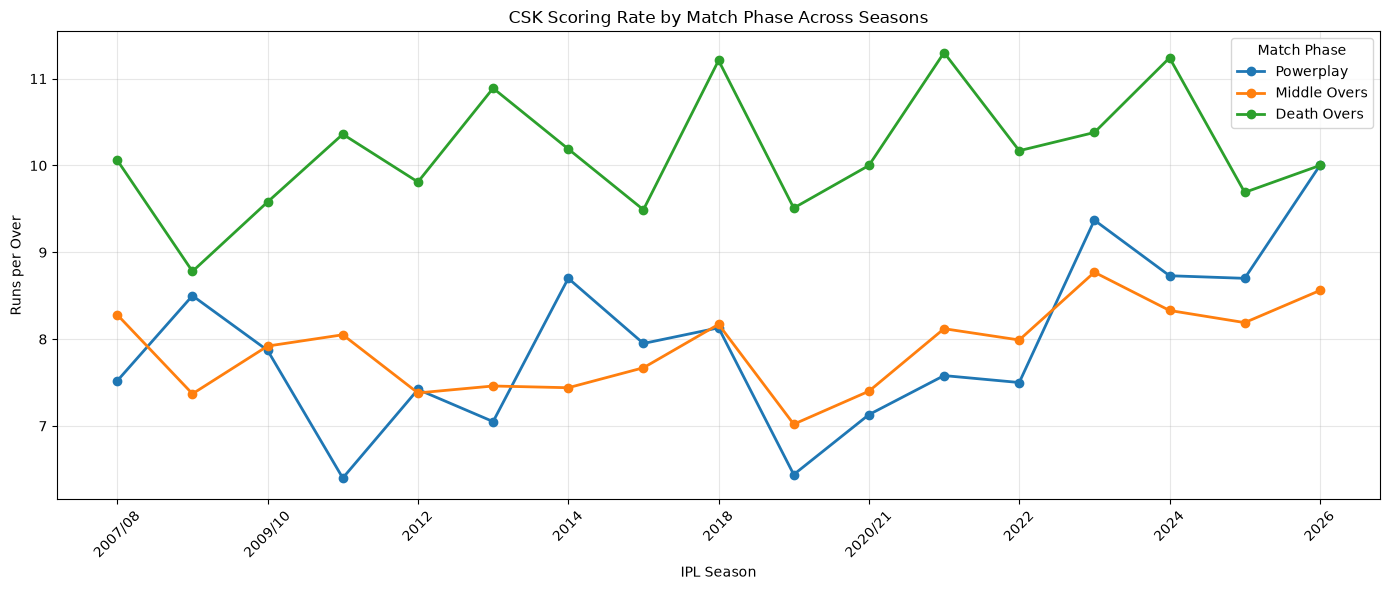

In [94]:
import matplotlib.pyplot as plt

phase_order = ["Powerplay", "Middle Overs", "Death Overs"]

phase_pivot = (
    csk_phase_by_season
    .pivot(index="season", columns="phase", values="runs_per_over")
    .reindex(columns=phase_order)
)

ax = phase_pivot.plot(
    kind="line",
    marker="o",
    figsize=(14, 6),
    linewidth=2
)

ax.set_title("CSK Scoring Rate by Match Phase Across Seasons")
ax.set_xlabel("IPL Season")
ax.set_ylabel("Runs per Over")
ax.legend(title="Match Phase")
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [95]:
best_seasons_by_phase = (
    csk_phase_by_season
    .loc[
        csk_phase_by_season
        .groupby("phase")["runs_per_over"]
        .idxmax()
    ]
    [["phase", "season", "runs_per_over", "recorded_overs"]]
    .sort_values("phase")
    .reset_index(drop=True)
)

display(best_seasons_by_phase)

,phase,season,runs_per_over,recorded_overs
0,Death Overs,2021,11.30,74
1,Middle Overs,2023,8.77,135
2,Powerplay,2026,10.00,84


In [96]:
csk_phase_wickets = con.sql("""
    SELECT
        CASE
            WHEN "over" BETWEEN 1 AND 6 THEN 'Powerplay'
            WHEN "over" BETWEEN 7 AND 15 THEN 'Middle Overs'
            WHEN "over" BETWEEN 16 AND 20 THEN 'Death Overs'
        END AS phase,
        COUNT(*) FILTER (
            WHERE is_wicket = TRUE
        ) AS recorded_dismissals,
        COUNT(DISTINCT
            CAST(match_id AS VARCHAR) || '-' ||
            CAST(innings AS VARCHAR) || '-' ||
            CAST("over" AS VARCHAR)
        ) AS recorded_overs,
        ROUND(
            COUNT(*) FILTER (WHERE is_wicket = TRUE) * 1.0
            / NULLIF(
                COUNT(DISTINCT
                    CAST(match_id AS VARCHAR) || '-' ||
                    CAST(innings AS VARCHAR) || '-' ||
                    CAST("over" AS VARCHAR)
                ),
                0
            ),
            3
        ) AS dismissals_per_over
    FROM ipl_cricket.deliveries
    WHERE LOWER(batting_team) LIKE '%chennai super kings%'
    GROUP BY phase
    HAVING phase IS NOT NULL
    ORDER BY
        CASE phase
            WHEN 'Powerplay' THEN 1
            WHEN 'Middle Overs' THEN 2
            WHEN 'Death Overs' THEN 3
        END
""").df()

display(csk_phase_wickets)

,phase,recorded_dismissals,recorded_overs,dismissals_per_over
0,Powerplay,357,1591,0.224
1,Middle Overs,570,2369,0.241
2,Death Overs,496,1220,0.407


In [97]:
csk_toss_analysis = con.sql("""
    SELECT
        toss_decision,
        COUNT(*) AS matches,
        COUNT(*) FILTER (
            WHERE winner = 'Chennai Super Kings'
        ) AS csk_wins,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner = 'Chennai Super Kings'
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS csk_win_percentage
    FROM dbt_prod.fct_matches
    WHERE
        (
            team1 = 'Chennai Super Kings'
            OR team2 = 'Chennai Super Kings'
        )
        AND winner IS NOT NULL
    GROUP BY toss_decision
    ORDER BY matches DESC
""").df()

display(csk_toss_analysis)

,toss_decision,matches,csk_wins,csk_win_percentage
0,field,154,81,52.60
1,bat,111,67,60.36


In [98]:
csk_toss_winner_analysis = con.sql("""
    SELECT
        CASE
            WHEN toss_winner = 'Chennai Super Kings'
                THEN 'CSK won toss'
            ELSE 'Opponent won toss'
        END AS toss_outcome,
        COUNT(*) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner = 'Chennai Super Kings'
        ) AS csk_wins,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner = 'Chennai Super Kings'
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS csk_win_percentage
    FROM dbt_prod.fct_matches
    WHERE
        (
            team1 = 'Chennai Super Kings'
            OR team2 = 'Chennai Super Kings'
        )
        AND winner IS NOT NULL
    GROUP BY toss_outcome
    ORDER BY toss_outcome
""").df()

display(csk_toss_winner_analysis)

,toss_outcome,decided_matches,csk_wins,csk_win_percentage
0,CSK won toss,132,79,59.85
1,Opponent won toss,133,69,51.88


In [99]:
csk_opponent_analysis = con.sql("""
    WITH csk_matches AS (
        SELECT
            CASE
                WHEN team1 = 'Chennai Super Kings' THEN team2
                ELSE team1
            END AS opponent,
            winner
        FROM dbt_prod.fct_matches
        WHERE
            (
                team1 = 'Chennai Super Kings'
                OR team2 = 'Chennai Super Kings'
            )
            AND winner IS NOT NULL
    )
    SELECT
        opponent,
        COUNT(*) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner = 'Chennai Super Kings'
        ) AS csk_wins,
        COUNT(*) FILTER (
            WHERE winner <> 'Chennai Super Kings'
        ) AS csk_losses,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner = 'Chennai Super Kings'
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS csk_win_percentage
    FROM csk_matches
    GROUP BY opponent
    HAVING COUNT(*) >= 5
    ORDER BY csk_win_percentage DESC, decided_matches DESC
""").df()

display(csk_opponent_analysis)

,opponent,decided_matches,csk_wins,csk_losses,csk_win_percentage
0,Pune Warriors,6,4,2,66.67
1,Kolkata Knight Riders,32,21,11,65.63
2,Delhi Capitals,33,21,12,63.64
3,Sunrisers Hyderabad,24,15,9,62.50
4,Royal Challengers Bengaluru,35,21,14,60.00
5,Deccan Chargers,10,6,4,60.00
6,Rajasthan Royals,32,16,16,50.00
7,Mumbai Indians,41,20,21,48.78
8,Punjab Kings,33,16,17,48.48
9,Lucknow Super Giants,7,3,4,42.86


In [100]:
csk_venue_analysis = con.sql("""
    SELECT
        venue,
        COUNT(*) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner = 'Chennai Super Kings'
        ) AS csk_wins,
        COUNT(*) FILTER (
            WHERE winner IS NOT NULL
              AND winner <> 'Chennai Super Kings'
        ) AS csk_losses,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner = 'Chennai Super Kings'
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS csk_win_percentage
    FROM dbt_prod.fct_matches
    WHERE
        (
            team1 = 'Chennai Super Kings'
            OR team2 = 'Chennai Super Kings'
        )
        AND winner IS NOT NULL
        AND venue IS NOT NULL
    GROUP BY venue
    HAVING COUNT(*) >= 5
    ORDER BY csk_win_percentage DESC, decided_matches DESC
""").df()

display(csk_venue_analysis)

,venue,decided_matches,csk_wins,csk_losses,csk_win_percentage
0,Feroz Shah Kotla,6,5,1,83.33
1,Maharashtra Cricket Association Stadium,6,5,1,83.33
2,MA Chidambaram Stadium,9,7,2,77.78
3,"MA Chidambaram Stadium, Chepauk",47,33,14,70.21
4,Dubai International Cricket Stadium,14,9,5,64.29
5,"Arun Jaitley Stadium, Delhi",5,3,2,60.00
6,JSCA International Stadium Complex,5,3,2,60.00
7,M Chinnaswamy Stadium,7,4,3,57.14
8,"Wankhede Stadium, Mumbai",13,7,6,53.85
9,"MA Chidambaram Stadium, Chepauk, Chennai",28,15,13,53.57


In [101]:
csk_venue_standardized = con.sql("""
    WITH csk_matches AS (
        SELECT
            CASE
                WHEN venue IN (
                    'MA Chidambaram Stadium',
                    'MA Chidambaram Stadium, Chepauk',
                    'MA Chidambaram Stadium, Chepauk, Chennai'
                )
                    THEN 'MA Chidambaram Stadium, Chepauk'
                WHEN venue IN (
                    'Wankhede Stadium',
                    'Wankhede Stadium, Mumbai'
                )
                    THEN 'Wankhede Stadium, Mumbai'
                ELSE venue
            END AS standardized_venue,
            winner
        FROM dbt_prod.fct_matches
        WHERE (
            team1 = 'Chennai Super Kings'
            OR team2 = 'Chennai Super Kings'
        )
        AND winner IS NOT NULL
        AND venue IS NOT NULL
    )
    SELECT
        standardized_venue AS venue,
        COUNT(*) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner = 'Chennai Super Kings'
        ) AS csk_wins,
        COUNT(*) FILTER (
            WHERE winner <> 'Chennai Super Kings'
        ) AS csk_losses,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner = 'Chennai Super Kings'
            ) / COUNT(*),
            2
        ) AS csk_win_percentage
    FROM csk_matches
    GROUP BY standardized_venue
    HAVING COUNT(*) >= 5
    ORDER BY csk_win_percentage DESC, decided_matches DESC
""").df()

display(csk_venue_standardized)

,venue,decided_matches,csk_wins,csk_losses,csk_win_percentage
0,Feroz Shah Kotla,6,5,1,83.33
1,Maharashtra Cricket Association Stadium,6,5,1,83.33
2,"MA Chidambaram Stadium, Chepauk",84,55,29,65.48
3,Dubai International Cricket Stadium,14,9,5,64.29
4,"Arun Jaitley Stadium, Delhi",5,3,2,60.00
5,JSCA International Stadium Complex,5,3,2,60.00
6,M Chinnaswamy Stadium,7,4,3,57.14
7,"Wankhede Stadium, Mumbai",27,14,13,51.85
8,Sawai Mansingh Stadium,6,3,3,50.00
9,Sheikh Zayed Stadium,6,3,3,50.00


In [102]:
csk_chase_analysis = con.sql("""
    WITH csk_match_results AS (
        SELECT
            CASE
                WHEN toss_winner = team1
                     AND toss_decision = 'bat'
                    THEN team1
                WHEN toss_winner = team1
                     AND toss_decision = 'field'
                    THEN team2
                WHEN toss_winner = team2
                     AND toss_decision = 'bat'
                    THEN team2
                WHEN toss_winner = team2
                     AND toss_decision = 'field'
                    THEN team1
            END AS batting_first_team,
            winner
        FROM dbt_prod.fct_matches
        WHERE (
            team1 = 'Chennai Super Kings'
            OR team2 = 'Chennai Super Kings'
        )
        AND winner IS NOT NULL
    )
    SELECT
        CASE
            WHEN batting_first_team = 'Chennai Super Kings'
                THEN 'Batting First'
            ELSE 'Chasing'
        END AS csk_batting_order,
        COUNT(*) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner = 'Chennai Super Kings'
        ) AS csk_wins,
        COUNT(*) FILTER (
            WHERE winner <> 'Chennai Super Kings'
        ) AS csk_losses,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner = 'Chennai Super Kings'
            ) / COUNT(*),
            2
        ) AS csk_win_percentage
    FROM csk_match_results
    WHERE batting_first_team IS NOT NULL
    GROUP BY csk_batting_order
    ORDER BY csk_batting_order
""").df()

display(csk_chase_analysis)

,csk_batting_order,decided_matches,csk_wins,csk_losses,csk_win_percentage
0,Batting First,144,74,70,51.39
1,Chasing,121,74,47,61.16


In [103]:
csk_player_contribution = con.sql("""
    SELECT
        batter AS player,
        SUM(batter_runs) AS total_runs,
        COUNT(DISTINCT match_id) AS matches_played,
        COUNT(*) FILTER (
            WHERE batter_runs = 4
        ) AS fours,
        COUNT(*) FILTER (
            WHERE batter_runs = 6
        ) AS sixes,
        COUNT(*) FILTER (
            WHERE COALESCE(wides, 0) = 0
        ) AS balls_faced,
        ROUND(
            100.0 * SUM(batter_runs)
            / NULLIF(
                COUNT(*) FILTER (
                    WHERE COALESCE(wides, 0) = 0
                ),
                0
            ),
            2
        ) AS strike_rate
    FROM ipl_cricket.deliveries
    WHERE LOWER(batting_team) LIKE '%chennai super kings%'
    GROUP BY batter
    HAVING COUNT(DISTINCT match_id) >= 10
    ORDER BY total_runs DESC
""").df()

display(csk_player_contribution.head(20))

,player,total_runs,matches_played,fours,sixes,balls_faced,strike_rate
0,MS Dhoni,4865.0,214,342,234,3497,139.12
1,SK Raina,4695.0,171,425,181,3427,137.00
2,RD Gaikwad,2839.0,84,260,107,2093,135.64
3,F du Plessis,2721.0,86,248,87,2070,131.45
4,RA Jadeja,2198.0,135,161,83,1615,136.10
5,AT Rayudu,1932.0,80,154,94,1494,129.32
6,MEK Hussey,1768.0,49,181,45,1430,123.64
7,S Dube,1730.0,65,108,115,1133,152.69
8,M Vijay,1708.0,69,150,68,1365,125.13
9,S Badrinath,1441.0,65,154,28,1212,118.89


In [104]:
csk_batter_consistency = con.sql("""
    WITH batter_innings AS (
        SELECT
            match_id,
            innings,
            batter AS player,
            SUM(batter_runs) AS runs_in_innings
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY match_id, innings, batter
    )
    SELECT
        player,
        COUNT(*) AS innings_batted,
        COUNT(*) FILTER (
            WHERE runs_in_innings >= 30
        ) AS innings_30_plus,
        COUNT(*) FILTER (
            WHERE runs_in_innings >= 50
        ) AS innings_50_plus,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE runs_in_innings >= 30
            ) / COUNT(*),
            2
        ) AS pct_innings_30_plus,
        ROUND(AVG(runs_in_innings), 2) AS avg_runs_per_batter_innings
    FROM batter_innings
    GROUP BY player
    HAVING COUNT(*) >= 10
    ORDER BY pct_innings_30_plus DESC, innings_30_plus DESC
""").df()

display(csk_batter_consistency.head(20))

,player,innings_batted,innings_30_plus,innings_50_plus,pct_innings_30_plus,avg_runs_per_batter_innings
0,A Mhatre,13,9,3,69.23,33.92
1,DP Conway,28,16,11,57.14,38.57
2,ML Hayden,33,17,8,51.52,33.55
3,MEK Hussey,49,25,14,51.02,36.08
4,D Brevis,14,7,2,50.00,26.86
5,RD Gaikwad,84,41,24,48.81,33.80
6,F du Plessis,86,41,20,47.67,31.64
7,DR Smith,32,13,7,40.63,30.16
8,SR Watson,43,17,9,39.53,29.12
9,BB McCullum,28,11,6,39.29,30.04


In [105]:
# Display the CSK batter consistency table cleanly
display(
    csk_batter_consistency
    .sort_values(
        ["pct_innings_30_plus", "innings_30_plus"],
        ascending=[False, False]
    )
    .head(20)
    .reset_index(drop=True)
    .style.format({
        "pct_innings_30_plus": "{:.2f}%",
        "avg_runs_per_batter_innings": "{:.2f}"
    })
)

,player,innings_batted,innings_30_plus,innings_50_plus,pct_innings_30_plus,avg_runs_per_batter_innings
0,A Mhatre,13,9,3,69.23%,33.92
1,DP Conway,28,16,11,57.14%,38.57
2,ML Hayden,33,17,8,51.52%,33.55
3,MEK Hussey,49,25,14,51.02%,36.08
4,D Brevis,14,7,2,50.00%,26.86
5,RD Gaikwad,84,41,24,48.81%,33.80
6,F du Plessis,86,41,20,47.67%,31.64
7,DR Smith,32,13,7,40.63%,30.16
8,SR Watson,43,17,9,39.53%,29.12
9,BB McCullum,28,11,6,39.29%,30.04


In [106]:
# Display the existing consistency analysis with correct column alignment

consistency_display = (
    csk_batter_consistency
    .sort_values(
        by=["pct_innings_30_plus", "innings_30_plus"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

display(consistency_display.style.format({
    "pct_innings_30_plus": "{:.2f}%",
    "avg_runs_per_batter_innings": "{:.2f}"
}))

,player,innings_batted,innings_30_plus,innings_50_plus,pct_innings_30_plus,avg_runs_per_batter_innings
0,A Mhatre,13,9,3,69.23%,33.92
1,DP Conway,28,16,11,57.14%,38.57
2,ML Hayden,33,17,8,51.52%,33.55
3,MEK Hussey,49,25,14,51.02%,36.08
4,D Brevis,14,7,2,50.00%,26.86
5,RD Gaikwad,84,41,24,48.81%,33.80
6,F du Plessis,86,41,20,47.67%,31.64
7,DR Smith,32,13,7,40.63%,30.16
8,SR Watson,43,17,9,39.53%,29.12
9,BB McCullum,28,11,6,39.29%,30.04


In [107]:
# CSK player contribution to total team batter runs

csk_player_contribution = con.sql("""
    WITH player_runs AS (
        SELECT
            batter AS player,
            SUM(batter_runs) AS total_runs,
            COUNT(DISTINCT match_id) AS matches_played
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY batter
    )

    SELECT
        player,
        total_runs,
        matches_played,
        ROUND(
            100.0 * total_runs
            / NULLIF(SUM(total_runs) OVER (), 0),
            2
        ) AS pct_of_csk_batter_runs
    FROM player_runs
    ORDER BY total_runs DESC
""").df()

display(csk_player_contribution.head(20))

,player,total_runs,matches_played,pct_of_csk_batter_runs
0,MS Dhoni,4865.0,214,11.74
1,SK Raina,4695.0,171,11.33
2,RD Gaikwad,2839.0,84,6.85
3,F du Plessis,2721.0,86,6.57
4,RA Jadeja,2198.0,135,5.30
5,AT Rayudu,1932.0,80,4.66
6,MEK Hussey,1768.0,49,4.27
7,S Dube,1730.0,65,4.17
8,M Vijay,1708.0,69,4.12
9,S Badrinath,1441.0,65,3.48


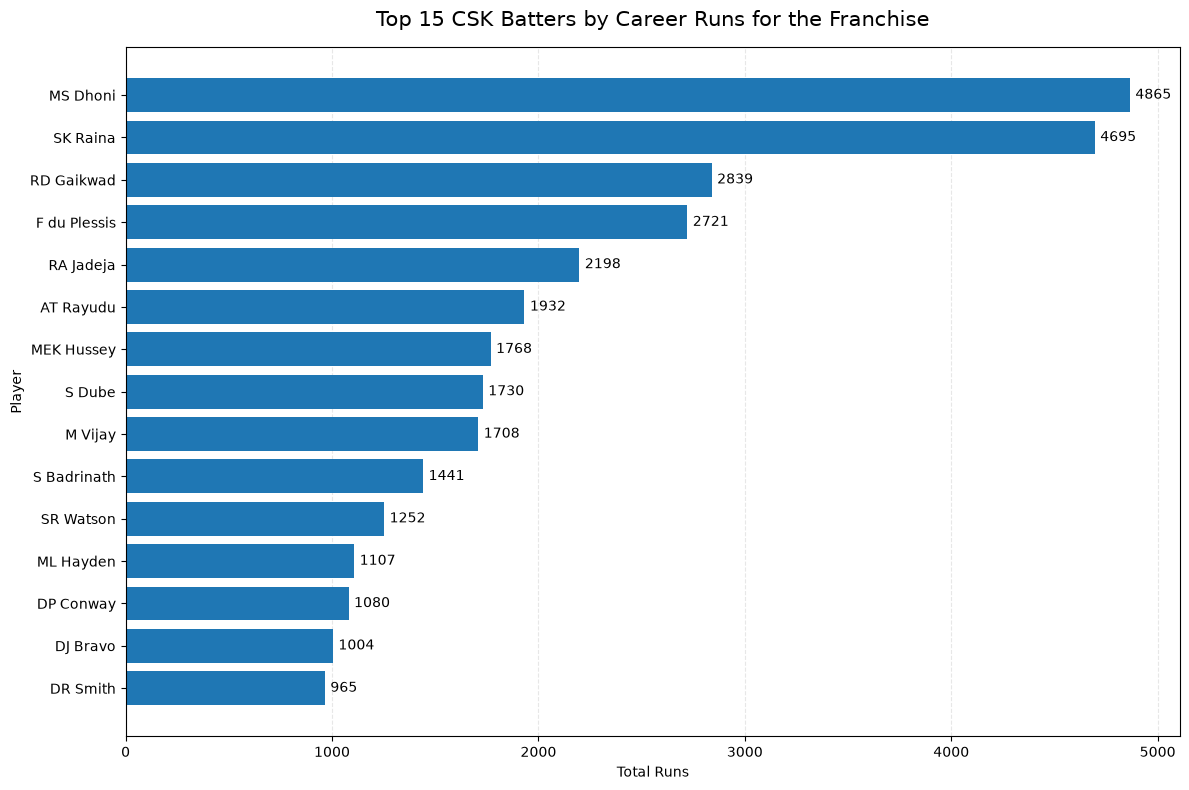

In [108]:
import matplotlib.pyplot as plt

# Top 15 CSK batters by total runs
plot_data = (
    csk_player_contribution
    .head(15)
    .sort_values("total_runs", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    plot_data["player"],
    plot_data["total_runs"]
)

ax.bar_label(bars, fmt="%.0f", padding=4)

ax.set_title(
    "Top 15 CSK Batters by Career Runs for the Franchise",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Total Runs")
ax.set_ylabel("Player")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

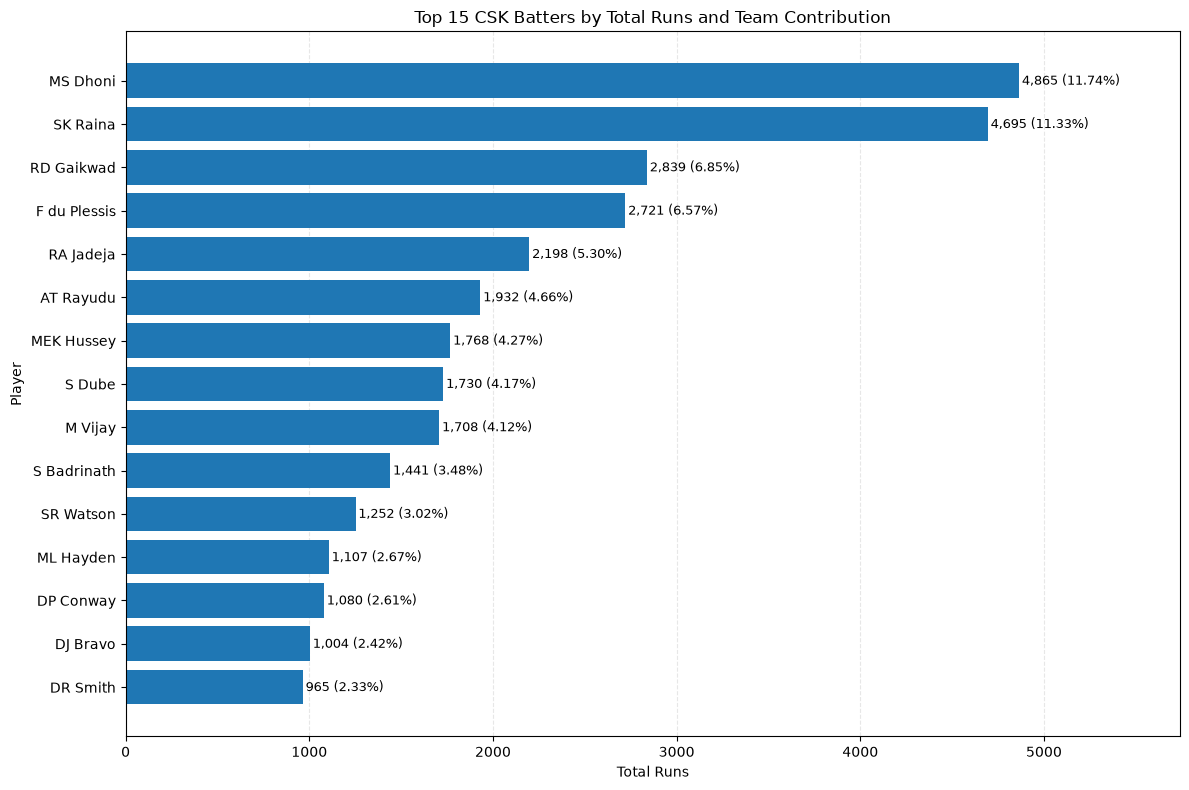

In [109]:
import matplotlib.pyplot as plt

plot_data = (
    csk_player_contribution
    .head(15)
    .sort_values("total_runs", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    plot_data["player"],
    plot_data["total_runs"]
)

for bar, runs, pct in zip(
    bars,
    plot_data["total_runs"],
    plot_data["pct_of_csk_batter_runs"]
):
    ax.text(
        bar.get_width() + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{runs:,.0f} ({pct:.2f}%)",
        va="center",
        fontsize=9
    )

ax.set_title("Top 15 CSK Batters by Total Runs and Team Contribution")
ax.set_xlabel("Total Runs")
ax.set_ylabel("Player")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.set_xlim(0, plot_data["total_runs"].max() * 1.18)

plt.tight_layout()
plt.show()

In [110]:
csk_batting_by_season = con.sql("""
    WITH season_innings AS (
        SELECT
            season,
            match_id,
            innings,
            SUM(total_runs) AS innings_total_runs,
            SUM(batter_runs) AS batter_runs
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY season, match_id, innings
    )
    SELECT
        season,
        COUNT(DISTINCT match_id) AS matches_played,
        COUNT(*) AS recorded_innings,
        SUM(batter_runs) AS total_batter_runs,
        SUM(innings_total_runs) AS total_team_runs,
        ROUND(AVG(innings_total_runs), 2) AS avg_runs_per_recorded_innings
    FROM season_innings
    GROUP BY season
    ORDER BY season
""").df()

display(csk_batting_by_season)

,season,matches_played,recorded_innings,total_batter_runs,total_team_runs,avg_runs_per_recorded_innings
0,2007/08,16,16,2365.0,2520.0,157.50
1,2009,14,14,2084.0,2231.0,159.36
2,2009/10,16,17,2442.0,2604.0,153.18
3,2011,16,16,2461.0,2560.0,160.00
4,2012,18,18,2717.0,2831.0,157.28
5,2013,18,18,2671.0,2778.0,154.33
6,2014,16,16,2519.0,2650.0,165.63
7,2015,17,17,2564.0,2725.0,160.29
8,2018,16,16,2698.0,2809.0,175.56
9,2019,17,17,2346.0,2473.0,145.47


In [111]:
# Validate the season-level averages using the displayed aggregate columns

csk_batting_by_season = csk_batting_by_season.copy()

csk_batting_by_season["avg_runs_per_recorded_innings"] = (
    csk_batting_by_season["total_team_runs"]
    / csk_batting_by_season["recorded_innings"]
).round(2)

# Check that each season's average matches its total and innings count
assert (
    csk_batting_by_season["recorded_innings"] > 0
).all(), "Found a season with zero recorded innings."

assert (
    csk_batting_by_season["total_team_runs"].notna()
).all(), "Missing total team runs."

display(
    csk_batting_by_season[
        [
            "season",
            "matches_played",
            "recorded_innings",
            "total_batter_runs",
            "total_team_runs",
            "avg_runs_per_recorded_innings",
        ]
    ].reset_index(drop=True)
)

,season,matches_played,recorded_innings,total_batter_runs,total_team_runs,avg_runs_per_recorded_innings
0,2007/08,16,16,2365.0,2520.0,157.50
1,2009,14,14,2084.0,2231.0,159.36
2,2009/10,16,17,2442.0,2604.0,153.18
3,2011,16,16,2461.0,2560.0,160.00
4,2012,18,18,2717.0,2831.0,157.28
5,2013,18,18,2671.0,2778.0,154.33
6,2014,16,16,2519.0,2650.0,165.62
7,2015,17,17,2564.0,2725.0,160.29
8,2018,16,16,2698.0,2809.0,175.56
9,2019,17,17,2346.0,2473.0,145.47


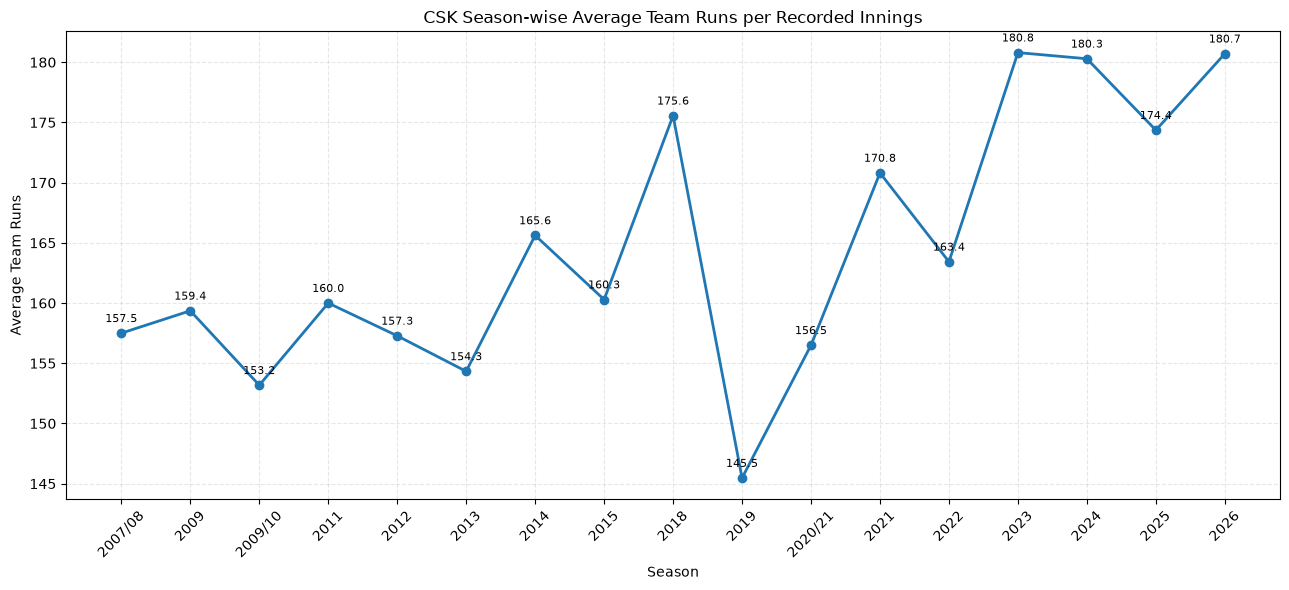

In [112]:
import matplotlib.pyplot as plt

plot_data = csk_batting_by_season.copy()

# Keep seasons in the order provided by the dataframe
plot_data["season"] = plot_data["season"].astype(str)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    plot_data["season"],
    plot_data["avg_runs_per_recorded_innings"],
    marker="o",
    linewidth=2
)

for _, row in plot_data.iterrows():
    ax.annotate(
        f'{row["avg_runs_per_recorded_innings"]:.1f}',
        (row["season"], row["avg_runs_per_recorded_innings"]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

ax.set_title("CSK Season-wise Average Team Runs per Recorded Innings")
ax.set_xlabel("Season")
ax.set_ylabel("Average Team Runs")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [113]:
csk_boundary_by_season = con.sql("""
    SELECT
        season,
        SUM(batter_runs) AS total_batter_runs,
        COUNT(*) FILTER (WHERE batter_runs = 4) AS fours,
        COUNT(*) FILTER (WHERE batter_runs = 6) AS sixes,
        4 * COUNT(*) FILTER (WHERE batter_runs = 4)
          + 6 * COUNT(*) FILTER (WHERE batter_runs = 6)
          AS boundary_runs,
        ROUND(
            100.0 * (
                4 * COUNT(*) FILTER (WHERE batter_runs = 4)
                + 6 * COUNT(*) FILTER (WHERE batter_runs = 6)
            ) / NULLIF(SUM(batter_runs), 0),
            2
        ) AS boundary_run_percentage
    FROM ipl_cricket.deliveries
    WHERE LOWER(batting_team) LIKE '%chennai super kings%'
    GROUP BY season
    ORDER BY season
""").df()

display(csk_boundary_by_season)

,season,total_batter_runs,fours,sixes,boundary_runs,boundary_run_percentage
0,2007/08,2365.0,244,86,1492,63.09
1,2009,2084.0,192,73,1206,57.87
2,2009/10,2442.0,212,98,1436,58.80
3,2011,2461.0,204,91,1362,55.34
4,2012,2717.0,223,102,1504,55.36
5,2013,2671.0,241,84,1468,54.96
6,2014,2519.0,205,112,1492,59.23
7,2015,2564.0,249,96,1572,61.31
8,2018,2698.0,211,145,1714,63.53
9,2019,2346.0,205,89,1354,57.72


In [114]:
# Validate the boundary analysis

csk_boundary_by_season = csk_boundary_by_season.copy()

csk_boundary_by_season["season"] = (
    csk_boundary_by_season["season"].astype(str)
)

csk_boundary_by_season["calculated_boundary_runs"] = (
    4 * csk_boundary_by_season["fours"]
    + 6 * csk_boundary_by_season["sixes"]
)

csk_boundary_by_season["calculated_boundary_percentage"] = (
    100 * csk_boundary_by_season["calculated_boundary_runs"]
    / csk_boundary_by_season["total_batter_runs"]
).round(2)

assert (
    csk_boundary_by_season["calculated_boundary_runs"]
    == csk_boundary_by_season["boundary_runs"]
).all(), "Boundary-run validation failed."

assert (
    csk_boundary_by_season["calculated_boundary_percentage"]
    - csk_boundary_by_season["boundary_run_percentage"]
).abs().max() < 0.02, "Boundary percentage validation failed."

display(
    csk_boundary_by_season[
        [
            "season",
            "total_batter_runs",
            "fours",
            "sixes",
            "boundary_runs",
            "boundary_run_percentage",
        ]
    ].reset_index(drop=True)
)

print("Validation passed: boundary runs and percentages are consistent.")

,season,total_batter_runs,fours,sixes,boundary_runs,boundary_run_percentage
0,2007/08,2365.0,244,86,1492,63.09
1,2009,2084.0,192,73,1206,57.87
2,2009/10,2442.0,212,98,1436,58.80
3,2011,2461.0,204,91,1362,55.34
4,2012,2717.0,223,102,1504,55.36
5,2013,2671.0,241,84,1468,54.96
6,2014,2519.0,205,112,1492,59.23
7,2015,2564.0,249,96,1572,61.31
8,2018,2698.0,211,145,1714,63.53
9,2019,2346.0,205,89,1354,57.72


Validation passed: boundary runs and percentages are consistent.


In [115]:
# Clean display of the existing boundary analysis
boundary_display = (
    csk_boundary_by_season[
        [
            "season",
            "total_batter_runs",
            "fours",
            "sixes",
            "boundary_runs",
            "boundary_run_percentage",
        ]
    ]
    .copy()
    .sort_values("season")
    .reset_index(drop=True)
)

display(
    boundary_display.style.format({
        "total_batter_runs": "{:,.0f}",
        "fours": "{:,.0f}",
        "sixes": "{:,.0f}",
        "boundary_runs": "{:,.0f}",
        "boundary_run_percentage": "{:.2f}%"
    })
)

,season,total_batter_runs,fours,sixes,boundary_runs,boundary_run_percentage
0,2007/08,"2,365",244,86,"1,492",63.09%
1,2009,"2,084",192,73,"1,206",57.87%
2,2009/10,"2,442",212,98,"1,436",58.80%
3,2011,"2,461",204,91,"1,362",55.34%
4,2012,"2,717",223,102,"1,504",55.36%
5,2013,"2,671",241,84,"1,468",54.96%
6,2014,"2,519",205,112,"1,492",59.23%
7,2015,"2,564",249,96,"1,572",61.31%
8,2018,"2,698",211,145,"1,714",63.53%
9,2019,"2,346",205,89,"1,354",57.72%


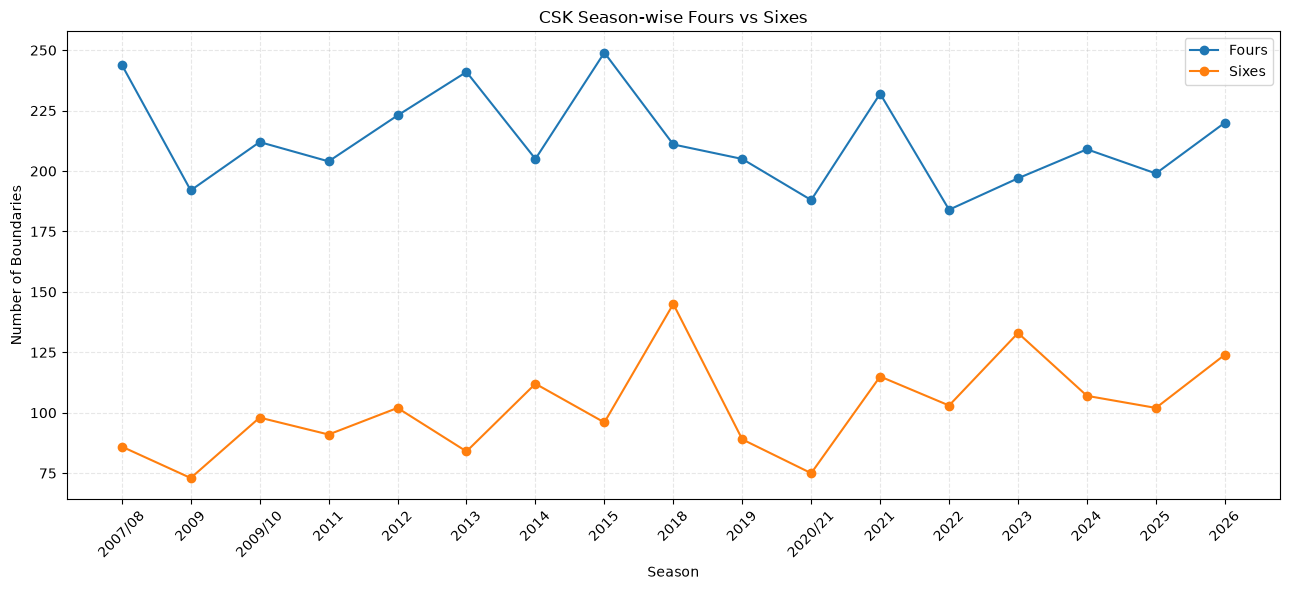

In [116]:
import matplotlib.pyplot as plt

plot_data = csk_boundary_by_season.copy()
plot_data["season"] = plot_data["season"].astype(str)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    plot_data["season"],
    plot_data["fours"],
    marker="o",
    label="Fours"
)

ax.plot(
    plot_data["season"],
    plot_data["sixes"],
    marker="o",
    label="Sixes"
)

ax.set_title("CSK Season-wise Fours vs Sixes")
ax.set_xlabel("Season")
ax.set_ylabel("Number of Boundaries")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [117]:
csk_scoring_efficiency = con.sql("""
    WITH season_over_runs AS (
        SELECT
            season,
            match_id,
            innings,
            "over" AS over_number,
            SUM(total_runs) AS runs_in_over
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY season, match_id, innings, "over"
    )
    SELECT
        season,
        COUNT(DISTINCT match_id) AS matches_played,
        COUNT(*) AS recorded_overs,
        SUM(runs_in_over) AS total_team_runs,
        ROUND(AVG(runs_in_over), 2) AS avg_runs_per_recorded_over
    FROM season_over_runs
    GROUP BY season
    ORDER BY season
""").df()

display(csk_scoring_efficiency)

,season,matches_played,recorded_overs,total_team_runs,avg_runs_per_recorded_over
0,2007/08,16,299,2520.0,8.43
1,2009,14,277,2231.0,8.05
2,2009/10,16,314,2604.0,8.29
3,2011,16,316,2560.0,8.10
4,2012,18,355,2831.0,7.97
5,2013,18,342,2778.0,8.12
6,2014,16,313,2650.0,8.47
7,2015,17,333,2725.0,8.18
8,2018,16,316,2809.0,8.89
9,2019,17,333,2473.0,7.43


In [118]:
# Validate the existing season-wise scoring-efficiency dataframe

efficiency_check = csk_scoring_efficiency.copy()

efficiency_check["season"] = efficiency_check["season"].astype(str)

efficiency_check["calculated_avg_runs_per_over"] = (
    efficiency_check["total_team_runs"]
    / efficiency_check["recorded_overs"]
).round(2)

assert (efficiency_check["recorded_overs"] > 0).all(), (
    "A season has zero recorded overs."
)

assert (
    efficiency_check["total_team_runs"].notna()
).all(), "Missing total team runs."

assert (
    efficiency_check["recorded_overs"].notna()
).all(), "Missing recorded-over counts."

assert (
    efficiency_check["calculated_avg_runs_per_over"]
    - efficiency_check["avg_runs_per_recorded_over"]
).abs().max() < 0.02, (
    "Average runs per recorded over does not match the totals."
)

display(
    efficiency_check[
        [
            "season",
            "matches_played",
            "recorded_overs",
            "total_team_runs",
            "avg_runs_per_recorded_over",
        ]
    ].reset_index(drop=True)
)

print("Validation passed: averages match the recorded totals and overs.")

,season,matches_played,recorded_overs,total_team_runs,avg_runs_per_recorded_over
0,2007/08,16,299,2520.0,8.43
1,2009,14,277,2231.0,8.05
2,2009/10,16,314,2604.0,8.29
3,2011,16,316,2560.0,8.10
4,2012,18,355,2831.0,7.97
5,2013,18,342,2778.0,8.12
6,2014,16,313,2650.0,8.47
7,2015,17,333,2725.0,8.18
8,2018,16,316,2809.0,8.89
9,2019,17,333,2473.0,7.43


Validation passed: averages match the recorded totals and overs.


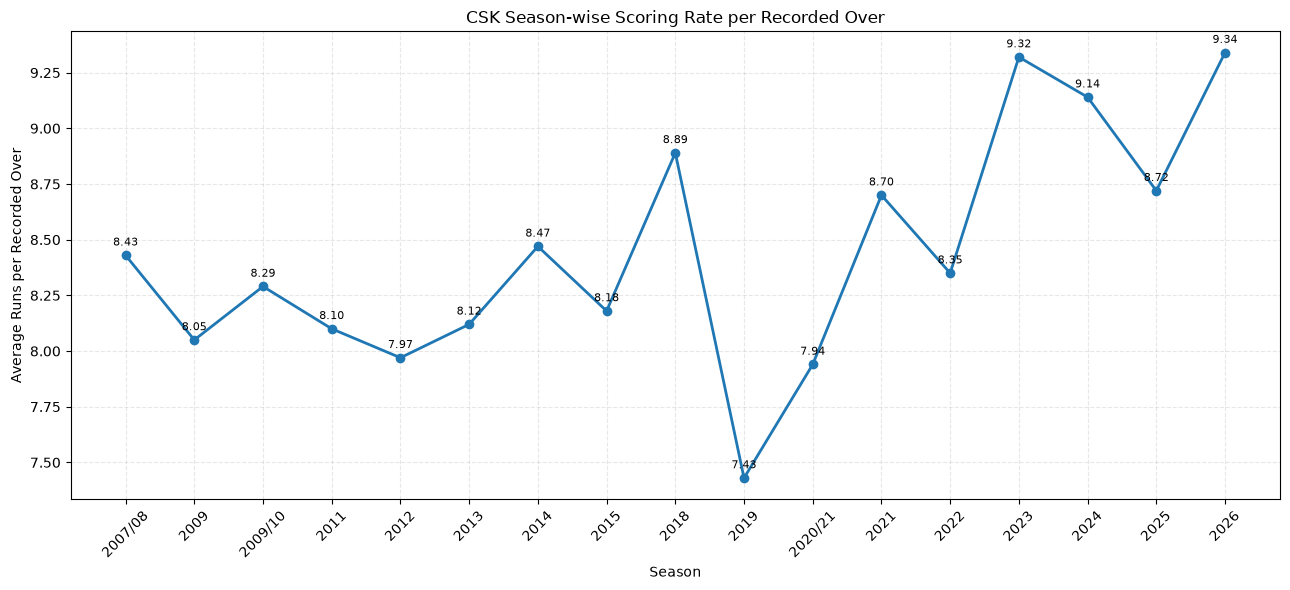

In [119]:
import matplotlib.pyplot as plt

plot_data = (
    csk_scoring_efficiency
    .copy()
    .sort_values("season")
)

plot_data["season"] = plot_data["season"].astype(str)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    plot_data["season"],
    plot_data["avg_runs_per_recorded_over"],
    marker="o",
    linewidth=2
)

for _, row in plot_data.iterrows():
    ax.annotate(
        f'{row["avg_runs_per_recorded_over"]:.2f}',
        (row["season"], row["avg_runs_per_recorded_over"]),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

ax.set_title("CSK Season-wise Scoring Rate per Recorded Over")
ax.set_xlabel("Season")
ax.set_ylabel("Average Runs per Recorded Over")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [120]:
csk_phase_efficiency = con.sql("""
    WITH over_level AS (
        SELECT
            season,
            match_id,
            innings,
            "over" AS over_number,
            SUM(total_runs) AS runs_in_over
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY season, match_id, innings, "over"
    ),
    phase_data AS (
        SELECT
            season,
            match_id,
            innings,
            CASE
                WHEN over_number BETWEEN 1 AND 6 THEN 'Powerplay'
                WHEN over_number BETWEEN 7 AND 15 THEN 'Middle Overs'
                WHEN over_number BETWEEN 16 AND 20 THEN 'Death Overs'
                ELSE 'Other'
            END AS innings_phase,
            runs_in_over
        FROM over_level
    )
    SELECT
        innings_phase,
        COUNT(*) AS recorded_overs,
        SUM(runs_in_over) AS total_runs,
        ROUND(AVG(runs_in_over), 2) AS avg_runs_per_recorded_over
    FROM phase_data
    WHERE innings_phase <> 'Other'
    GROUP BY innings_phase
    ORDER BY CASE innings_phase
        WHEN 'Powerplay' THEN 1
        WHEN 'Middle Overs' THEN 2
        WHEN 'Death Overs' THEN 3
        ELSE 4
    END
""").df()

display(csk_phase_efficiency)

,innings_phase,recorded_overs,total_runs,avg_runs_per_recorded_over
0,Powerplay,1591,12562.0,7.90
1,Middle Overs,2369,18646.0,7.87
2,Death Overs,1220,12392.0,10.16


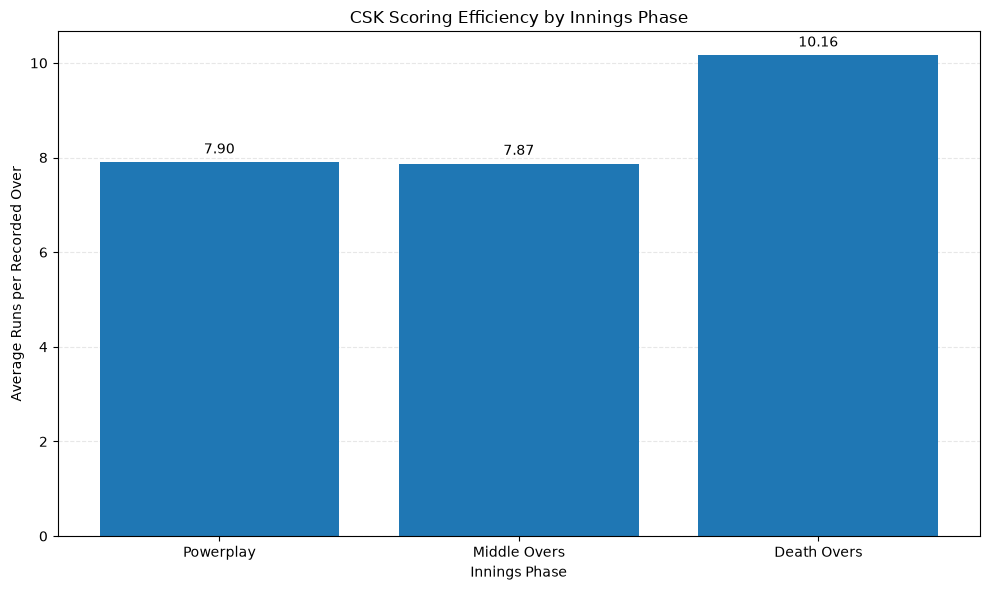

In [121]:
import matplotlib.pyplot as plt

phase_order = ["Powerplay", "Middle Overs", "Death Overs"]

plot_data = (
    csk_phase_efficiency
    .set_index("innings_phase")
    .reindex(phase_order)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    plot_data["innings_phase"],
    plot_data["avg_runs_per_recorded_over"]
)

ax.bar_label(bars, fmt="%.2f", padding=4)

ax.set_title("CSK Scoring Efficiency by Innings Phase")
ax.set_xlabel("Innings Phase")
ax.set_ylabel("Average Runs per Recorded Over")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [122]:
csk_phase_risk = con.sql("""
    WITH over_level AS (
        SELECT
            match_id,
            innings,
            "over" AS over_number,
            SUM(total_runs) AS runs_in_over,
            SUM(COALESCE(is_wicket, 0)) AS recorded_dismissals
        FROM ipl_cricket.deliveries
        WHERE LOWER(batting_team) LIKE '%chennai super kings%'
        GROUP BY match_id, innings, "over"
    ),
    phase_data AS (
        SELECT
            CASE
                WHEN over_number BETWEEN 1 AND 6 THEN 'Powerplay'
                WHEN over_number BETWEEN 7 AND 15 THEN 'Middle Overs'
                WHEN over_number BETWEEN 16 AND 20 THEN 'Death Overs'
            END AS innings_phase,
            runs_in_over,
            recorded_dismissals
        FROM over_level
        WHERE over_number BETWEEN 1 AND 20
    )
    SELECT
        innings_phase,
        COUNT(*) AS recorded_overs,
        SUM(runs_in_over) AS total_runs,
        ROUND(AVG(runs_in_over), 2) AS avg_runs_per_recorded_over,
        SUM(recorded_dismissals) AS recorded_dismissals,
        ROUND(
            1.0 * SUM(recorded_dismissals) / COUNT(*),
            3
        ) AS dismissals_per_recorded_over
    FROM phase_data
    GROUP BY innings_phase
    ORDER BY CASE innings_phase
        WHEN 'Powerplay' THEN 1
        WHEN 'Middle Overs' THEN 2
        WHEN 'Death Overs' THEN 3
    END
""").df()

display(csk_phase_risk)

,innings_phase,recorded_overs,total_runs,avg_runs_per_recorded_over,recorded_dismissals,dismissals_per_recorded_over
0,Powerplay,1591,12562.0,7.90,357.0,0.224
1,Middle Overs,2369,18646.0,7.87,570.0,0.241
2,Death Overs,1220,12392.0,10.16,496.0,0.407


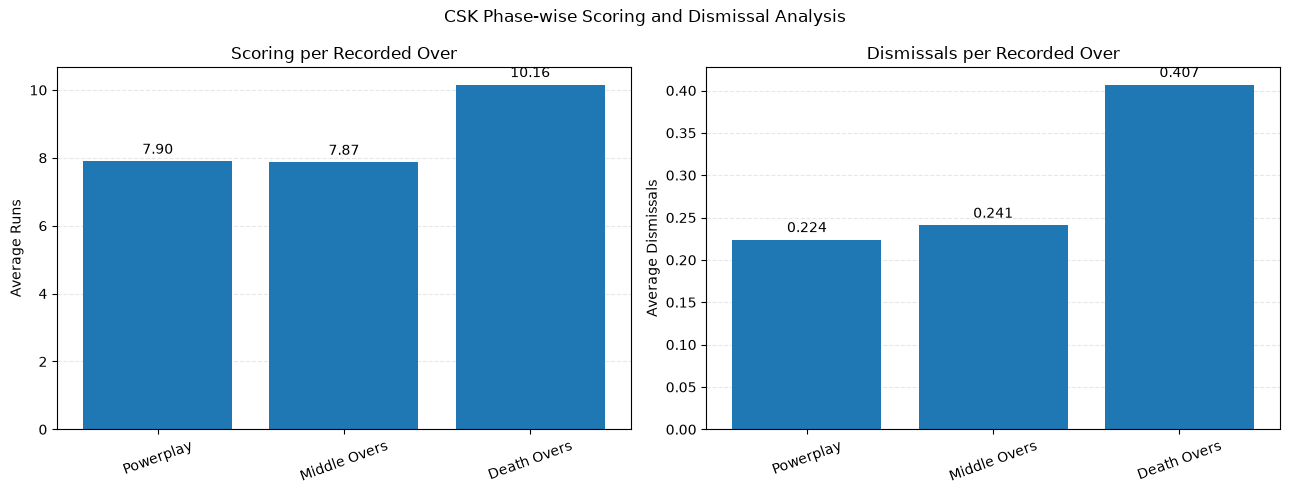

In [123]:
import matplotlib.pyplot as plt

phase_order = ["Powerplay", "Middle Overs", "Death Overs"]

plot_data = (
    csk_phase_risk
    .set_index("innings_phase")
    .reindex(phase_order)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: scoring efficiency
bars1 = axes[0].bar(
    plot_data["innings_phase"],
    plot_data["avg_runs_per_recorded_over"]
)
axes[0].bar_label(bars1, fmt="%.2f", padding=3)
axes[0].set_title("Scoring per Recorded Over")
axes[0].set_ylabel("Average Runs")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
axes[0].set_axisbelow(True)

# Chart 2: dismissal frequency
bars2 = axes[1].bar(
    plot_data["innings_phase"],
    plot_data["dismissals_per_recorded_over"]
)
axes[1].bar_label(bars2, fmt="%.3f", padding=3)
axes[1].set_title("Dismissals per Recorded Over")
axes[1].set_ylabel("Average Dismissals")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
axes[1].set_axisbelow(True)

fig.suptitle("CSK Phase-wise Scoring and Dismissal Analysis")
plt.tight_layout()
plt.show()

In [124]:
csk_match_winners = con.sql("""
    SELECT
        player_of_match AS player,
        COUNT(*) AS player_of_match_awards,
        COUNT(DISTINCT match_id) AS matches_awarded
    FROM dbt_prod.fct_matches
    WHERE LOWER(winner) LIKE '%chennai super kings%'
      AND player_of_match IS NOT NULL
    GROUP BY player_of_match
    ORDER BY player_of_match_awards DESC, player
""").df()

display(csk_match_winners.head(20))

,player,player_of_match_awards,matches_awarded
0,MS Dhoni,16,16
1,RA Jadeja,16,16
2,SK Raina,12,12
3,RD Gaikwad,11,11
4,MEK Hussey,10,10
5,F du Plessis,6,6
6,SR Watson,6,6
7,M Vijay,5,5
8,ML Hayden,4,4
9,A Nehra,3,3


Total player-of-the-match awards counted: 148
Players tied for the highest award count:


,player,player_of_match_awards,matches_awarded
0,MS Dhoni,16,16
1,RA Jadeja,16,16


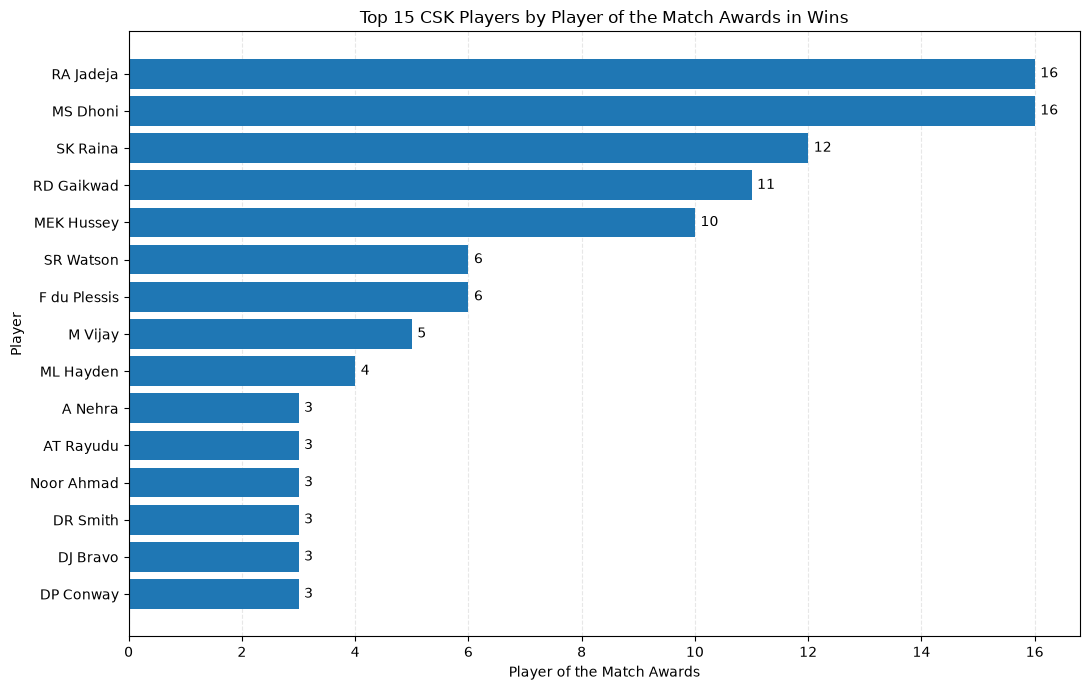

In [125]:
# Validate the player-of-the-match award summary

assert csk_match_winners["player"].notna().all(), (
    "Player names contain missing values."
)

assert (
    csk_match_winners["player_of_match_awards"]
    == csk_match_winners["matches_awarded"]
).all(), (
    "Award counts and distinct match counts differ; investigate duplicates."
)

print("Total player-of-the-match awards counted:",
      int(csk_match_winners["player_of_match_awards"].sum()))

print("Players tied for the highest award count:")
display(
    csk_match_winners[
        csk_match_winners["player_of_match_awards"]
        == csk_match_winners["player_of_match_awards"].max()
    ]
)

import matplotlib.pyplot as plt

plot_data = (
    csk_match_winners
    .head(15)
    .sort_values("player_of_match_awards", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data["player"],
    plot_data["player_of_match_awards"]
)

ax.bar_label(bars, padding=4, fmt="%.0f")

ax.set_title("Top 15 CSK Players by Player of the Match Awards in Wins")
ax.set_xlabel("Player of the Match Awards")
ax.set_ylabel("Player")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [126]:
csk_player_award_outcomes = con.sql("""
    SELECT
        player_of_match AS player,
        COUNT(*) AS matches_with_award,
        COUNT(*) FILTER (
            WHERE LOWER(winner) LIKE '%chennai super kings%'
        ) AS csk_wins,
        COUNT(*) FILTER (
            WHERE winner IS NOT NULL
              AND LOWER(winner) NOT LIKE '%chennai super kings%'
        ) AS csk_losses,
        COUNT(*) FILTER (WHERE winner IS NULL) AS no_result_or_unknown,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE LOWER(winner) LIKE '%chennai super kings%'
            ) / NULLIF(COUNT(*), 0),
            2
        ) AS csk_win_percentage_when_awarded
    FROM dbt_prod.fct_matches
    WHERE player_of_match IS NOT NULL
    GROUP BY player_of_match
    HAVING COUNT(*) >= 5
    ORDER BY csk_win_percentage_when_awarded DESC,
             matches_with_award DESC
""").df()

display(csk_player_award_outcomes)

,player,matches_with_award,csk_wins,csk_losses,no_result_or_unknown,csk_win_percentage_when_awarded
0,RA Jadeja,17,16,1,0,94.12
1,RD Gaikwad,12,11,1,0,91.67
2,MS Dhoni,18,16,2,0,88.89
3,SK Raina,14,12,2,0,85.71
4,MEK Hussey,12,10,2,0,83.33
...,...,...,...,...,...,...
80,BA Stokes,5,0,5,0,0.00
81,DW Steyn,5,0,5,0,0.00
82,SPD Smith,5,0,5,0,0.00
83,DPMD Jayawardene,5,0,5,0,0.00


In [127]:
# Validate the award-outcome summary

check = csk_player_award_outcomes.copy()

check["calculated_win_percentage"] = (
    100 * check["csk_wins"]
    / check["matches_with_award"]
).round(2)

assert (
    check["csk_wins"]
    + check["csk_losses"]
    + check["no_result_or_unknown"]
    == check["matches_with_award"]
).all(), "Outcome counts do not sum to matches with award."

assert (
    check["calculated_win_percentage"]
    - check["csk_win_percentage_when_awarded"]
).abs().max() < 0.02, "Win percentage validation failed."

print("Validation passed.")
display(
    check.sort_values(
        ["csk_win_percentage_when_awarded", "matches_with_award"],
        ascending=[False, False]
    ).head(15)
)

Validation passed.


,player,matches_with_award,csk_wins,csk_losses,no_result_or_unknown,csk_win_percentage_when_awarded,calculated_win_percentage
0,RA Jadeja,17,16,1,0,94.12,94.12
1,RD Gaikwad,12,11,1,0,91.67,91.67
2,MS Dhoni,18,16,2,0,88.89,88.89
3,SK Raina,14,12,2,0,85.71,85.71
4,MEK Hussey,12,10,2,0,83.33,83.33
5,M Vijay,6,5,1,0,83.33,83.33
6,F du Plessis,10,6,4,0,60.00,60.00
7,A Nehra,6,3,3,0,50.00,50.00
8,BB McCullum,5,2,3,0,40.00,40.00
9,SR Watson,16,6,10,0,37.50,37.50


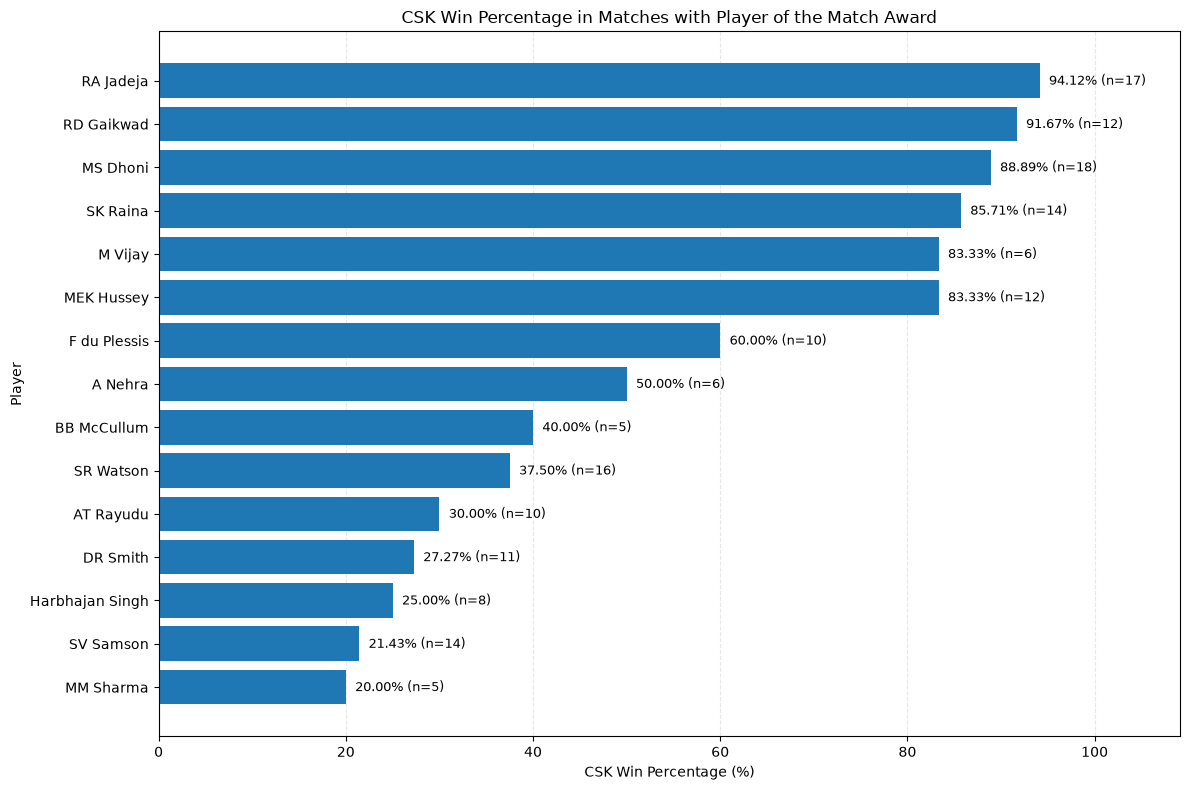

In [128]:
import matplotlib.pyplot as plt

plot_data = (
    csk_player_award_outcomes
    .sort_values(
        ["csk_win_percentage_when_awarded", "matches_with_award"],
        ascending=[False, False]
    )
    .head(15)
    .sort_values("csk_win_percentage_when_awarded")
    .copy()
)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    plot_data["player"],
    plot_data["csk_win_percentage_when_awarded"]
)

for bar, pct, matches in zip(
    bars,
    plot_data["csk_win_percentage_when_awarded"],
    plot_data["matches_with_award"]
):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.2f}% (n={matches})",
        va="center",
        fontsize=9
    )

ax.set_title(
    "CSK Win Percentage in Matches with Player of the Match Award"
)
ax.set_xlabel("CSK Win Percentage (%)")
ax.set_ylabel("Player")
ax.set_xlim(
    0,
    min(110, plot_data["csk_win_percentage_when_awarded"].max() + 15)
)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [129]:
csk_toss_by_season = con.sql("""
    SELECT
        season,
        COUNT(*) FILTER (
            WHERE LOWER(toss_winner) LIKE '%chennai super kings%'
              AND winner IS NOT NULL
        ) AS toss_won_decided_matches,
        COUNT(*) FILTER (
            WHERE LOWER(toss_winner) LIKE '%chennai super kings%'
              AND LOWER(winner) LIKE '%chennai super kings%'
        ) AS wins_after_winning_toss,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE LOWER(toss_winner) LIKE '%chennai super kings%'
                  AND LOWER(winner) LIKE '%chennai super kings%'
            ) / NULLIF(
                COUNT(*) FILTER (
                    WHERE LOWER(toss_winner) LIKE '%chennai super kings%'
                      AND winner IS NOT NULL
                ),
                0
            ),
            2
        ) AS win_pct_after_winning_toss
    FROM dbt_prod.fct_matches
    WHERE LOWER(team1) LIKE '%chennai super kings%'
       OR LOWER(team2) LIKE '%chennai super kings%'
    GROUP BY season
    ORDER BY season
""").df()

display(csk_toss_by_season)

,season,toss_won_decided_matches,wins_after_winning_toss,win_pct_after_winning_toss
0,2007/08,5,3,60.00
1,2009,7,4,57.14
2,2009/10,10,6,60.00
3,2011,9,7,77.78
4,2012,7,4,57.14
5,2013,8,7,87.50
6,2014,10,6,60.00
7,2015,10,5,50.00
8,2018,11,8,72.73
9,2019,12,7,58.33


In [130]:
toss_check = csk_toss_by_season.copy()

toss_check["season"] = toss_check["season"].astype(str)

toss_check["calculated_win_pct"] = (
    100 * toss_check["wins_after_winning_toss"]
    / toss_check["toss_won_decided_matches"].replace(0, float("nan"))
).round(2)

assert (
    toss_check["wins_after_winning_toss"]
    <= toss_check["toss_won_decided_matches"]
).all(), "Wins exceed decided matches."

assert (
    toss_check["calculated_win_pct"]
    - toss_check["win_pct_after_winning_toss"]
).abs().max() < 0.02, "Win percentage validation failed."

print("Validation passed.")
display(
    toss_check[
        [
            "season",
            "toss_won_decided_matches",
            "wins_after_winning_toss",
            "win_pct_after_winning_toss",
        ]
    ].reset_index(drop=True)
)

Validation passed.


,season,toss_won_decided_matches,wins_after_winning_toss,win_pct_after_winning_toss
0,2007/08,5,3,60.00
1,2009,7,4,57.14
2,2009/10,10,6,60.00
3,2011,9,7,77.78
4,2012,7,4,57.14
5,2013,8,7,87.50
6,2014,10,6,60.00
7,2015,10,5,50.00
8,2018,11,8,72.73
9,2019,12,7,58.33


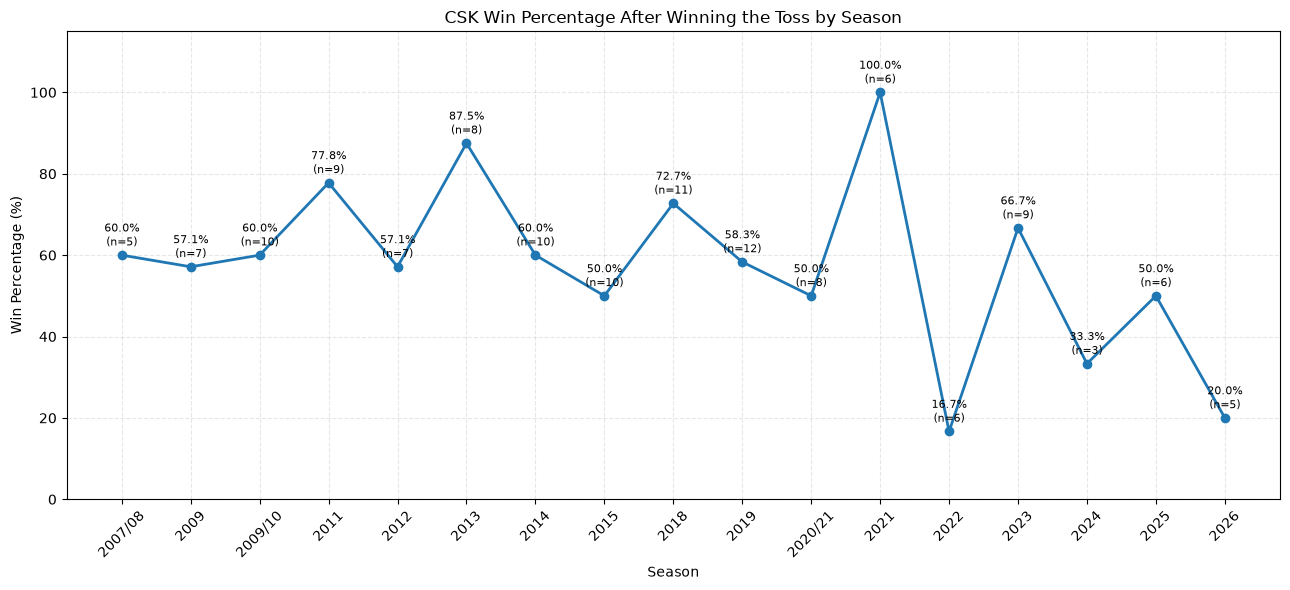

In [131]:
import matplotlib.pyplot as plt

plot_data = toss_check.copy()
plot_data["season"] = plot_data["season"].astype(str)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    plot_data["season"],
    plot_data["win_pct_after_winning_toss"],
    marker="o",
    linewidth=2
)

for _, row in plot_data.iterrows():
    ax.annotate(
        f'{row["win_pct_after_winning_toss"]:.1f}%\n(n={int(row["toss_won_decided_matches"])})',
        (row["season"], row["win_pct_after_winning_toss"]),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

ax.set_title("CSK Win Percentage After Winning the Toss by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Win Percentage (%)")
ax.set_ylim(0, 115)
ax.tick_params(axis="x", rotation=45)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [132]:
csk_toss_decision_impact = con.sql("""
    SELECT
        toss_decision,
        COUNT(*) FILTER (WHERE winner IS NOT NULL) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner IS NOT NULL
              AND LOWER(winner) LIKE '%chennai super kings%'
        ) AS csk_wins,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner IS NOT NULL
                  AND LOWER(winner) LIKE '%chennai super kings%'
            ) / NULLIF(
                COUNT(*) FILTER (WHERE winner IS NOT NULL),
                0
            ),
            2
        ) AS csk_win_percentage
    FROM dbt_prod.fct_matches
    WHERE (
        LOWER(team1) LIKE '%chennai super kings%'
        OR LOWER(team2) LIKE '%chennai super kings%'
    )
      AND LOWER(toss_winner) LIKE '%chennai super kings%'
      AND toss_decision IS NOT NULL
    GROUP BY toss_decision
    ORDER BY toss_decision
""").df()

display(csk_toss_decision_impact)

,toss_decision,decided_matches,csk_wins,csk_win_percentage
0,bat,61,36,59.02
1,field,71,43,60.56


Validation passed.


,toss_decision,decided_matches,csk_wins,csk_win_percentage,calculated_win_percentage
0,bat,61,36,59.02,59.02
1,field,71,43,60.56,60.56


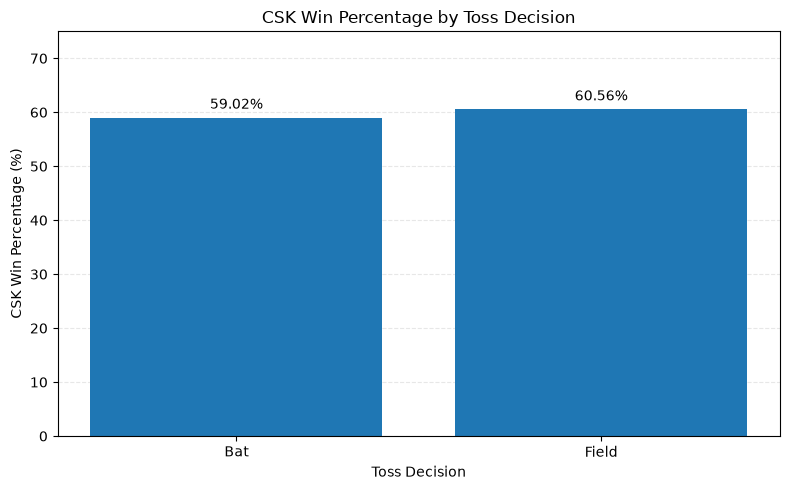

In [133]:
check = csk_toss_decision_impact.copy()

check["calculated_win_percentage"] = (
    100 * check["csk_wins"] / check["decided_matches"]
).round(2)

assert (check["decided_matches"] > 0).all()
assert (check["csk_wins"] <= check["decided_matches"]).all()

assert (
    check["calculated_win_percentage"]
    - check["csk_win_percentage"]
).abs().max() < 0.02, "Win percentage validation failed."

print("Validation passed.")
display(check)


import matplotlib.pyplot as plt

plot_data = csk_toss_decision_impact.copy()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    plot_data["toss_decision"].str.title(),
    plot_data["csk_win_percentage"]
)

ax.bar_label(bars, fmt="%.2f%%", padding=4)

ax.set_title("CSK Win Percentage by Toss Decision")
ax.set_xlabel("Toss Decision")
ax.set_ylabel("CSK Win Percentage (%)")
ax.set_ylim(0, 75)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [134]:
csk_venue_toss_analysis = con.sql("""
    SELECT
        venue,
        toss_decision,
        COUNT(*) FILTER (
            WHERE winner IS NOT NULL
        ) AS decided_matches,
        COUNT(*) FILTER (
            WHERE winner IS NOT NULL
              AND LOWER(winner) LIKE '%chennai super kings%'
        ) AS csk_wins,
        ROUND(
            100.0 * COUNT(*) FILTER (
                WHERE winner IS NOT NULL
                  AND LOWER(winner) LIKE '%chennai super kings%'
            ) / NULLIF(
                COUNT(*) FILTER (
                    WHERE winner IS NOT NULL
                ),
                0
            ),
            2
        ) AS csk_win_percentage
    FROM dbt_prod.fct_matches
    WHERE (
        LOWER(team1) LIKE '%chennai super kings%'
        OR LOWER(team2) LIKE '%chennai super kings%'
    )
      AND LOWER(toss_winner) LIKE '%chennai super kings%'
      AND toss_decision IS NOT NULL
      AND venue IS NOT NULL
    GROUP BY venue, toss_decision
    HAVING COUNT(*) FILTER (WHERE winner IS NOT NULL) >= 3
    ORDER BY venue, toss_decision
""").df()

display(csk_venue_toss_analysis)

,venue,toss_decision,decided_matches,csk_wins,csk_win_percentage
0,Dubai International Cricket Stadium,field,3,2,66.67
1,Eden Gardens,field,3,2,66.67
2,M Chinnaswamy Stadium,field,3,1,33.33
3,"M Chinnaswamy Stadium, Bengaluru",field,3,0,0.00
4,MA Chidambaram Stadium,field,5,4,80.00
5,"MA Chidambaram Stadium, Chepauk",bat,20,15,75.00
6,"MA Chidambaram Stadium, Chepauk",field,3,2,66.67
7,"MA Chidambaram Stadium, Chepauk, Chennai",bat,4,1,25.00
8,"MA Chidambaram Stadium, Chepauk, Chennai",field,7,5,71.43
9,Maharashtra Cricket Association Stadium,field,3,3,100.00


In [135]:
# Standardize common venue-name variants in the existing result

csk_venue_toss_clean = csk_venue_toss_analysis.copy()

csk_venue_toss_clean["venue_clean"] = (
    csk_venue_toss_clean["venue"]
    .replace({
        "MA Chidambaram Stadium": "MA Chidambaram Stadium, Chepauk",
        "MA Chidambaram Stadium, Chepauk, Chennai":
            "MA Chidambaram Stadium, Chepauk",
        "M Chinnaswamy Stadium, Bengaluru":
            "M Chinnaswamy Stadium"
    })
)

# Re-aggregate counts, not percentages
csk_venue_toss_clean = (
    csk_venue_toss_clean
    .groupby(["venue_clean", "toss_decision"], as_index=False)
    .agg(
        decided_matches=("decided_matches", "sum"),
        csk_wins=("csk_wins", "sum")
    )
)

csk_venue_toss_clean["csk_win_percentage"] = (
    100 * csk_venue_toss_clean["csk_wins"]
    / csk_venue_toss_clean["decided_matches"]
).round(2)

csk_venue_toss_clean = csk_venue_toss_clean.sort_values(
    ["venue_clean", "toss_decision"]
).reset_index(drop=True)

display(csk_venue_toss_clean)

,venue_clean,toss_decision,decided_matches,csk_wins,csk_win_percentage
0,Dubai International Cricket Stadium,field,3,2,66.67
1,Eden Gardens,field,3,2,66.67
2,M Chinnaswamy Stadium,field,6,1,16.67
3,"MA Chidambaram Stadium, Chepauk",bat,24,16,66.67
4,"MA Chidambaram Stadium, Chepauk",field,15,11,73.33
5,Maharashtra Cricket Association Stadium,field,3,3,100.00
6,"Narendra Modi Stadium, Ahmedabad",field,3,1,33.33
7,Sharjah Cricket Stadium,field,3,2,66.67
8,Sheikh Zayed Stadium,bat,3,1,33.33
9,Wankhede Stadium,field,8,5,62.50


In [136]:
# List analytical DataFrames currently available

import pandas as pd

analysis_dataframes = []

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        analysis_dataframes.append({
            "dataframe_name": name,
            "rows": len(obj),
            "columns": len(obj.columns),
            "column_names": ", ".join(obj.columns.astype(str))
        })

analysis_inventory = pd.DataFrame(analysis_dataframes)

display(
    analysis_inventory.sort_values(
        "dataframe_name"
    ).reset_index(drop=True)
)

,dataframe_name,rows,columns,column_names
0,_2,5,13,"season, player, player_id, team, total_runs, i..."
1,_3,5,13,"season, player, player_id, team, total_runs, i..."
2,_4,13,6,"column_name, column_type, null, key, default, ..."
3,_52,15,8,"bowler, match_id, innings, delivery_rows, min_..."
4,_56,12,6,"bowler, match_id, innings, delivery_rows, min_..."
...,...,...,...,...
101,unusual_innings,2,9,"match_id, date, season, innings, batting_team,..."
102,venue_chart,27,6,"venue, matches_played, csk_wins, csk_losses, m..."
103,venue_plot,13,5,"venue, decided_matches, csk_wins, csk_losses, ..."
104,wicket_column_check,100,9,"bowler, match_id, innings, over, ball, is_wick..."


In [137]:
print(
    analysis_inventory[
        ["dataframe_name", "rows", "columns"]
    ].to_string(index=False)
)

              dataframe_name  rows  columns
                          __     8        2
                         ___    15       12
                      tables    46        1
                          _2     5       13
                          _3     5       13
                          _4    13        6
                 csk_batting   257       11
                          _7    16        1
                          _9    32        6
               match_columns    32        6
      csk_season_performance    17        7
                season_chart    17        7
                result_check     3        3
    csk_opponent_performance    12        7
              opponent_chart    12        7
          csk_venue_analysis    16        5
                  venue_plot    13        5
       csk_venue_performance    27        6
                 venue_chart    27        6
           jadeja_diagnostic   115        9
          bowling_team_check   166        4
        bowling_schema_check    

In [138]:
import os
import pandas as pd

# Create output directory
output_dir = "outputs"
os.makedirs(output_dir, exist_ok=True)

# Final analytical datasets for Power BI
final_datasets = {
    "csk_season_performance": csk_season_performance,
    "csk_opponent_analysis": csk_opponent_analysis,
    "csk_venue_analysis": csk_venue_analysis,

    "csk_batting_summary": csk_batting_summary,
    "csk_top_run_scorers": csk_top_run_scorers,
    "csk_batting_strike_rate": csk_batting_strike_rate,
    "csk_batter_consistency": csk_batter_consistency,
    "csk_batting_by_season": csk_batting_by_season,
    "csk_boundary_by_season": csk_boundary_by_season,

    "top_csk_bowlers": top_csk_bowlers,
    "csk_bowler_economy": csk_bowler_economy,
    "csk_bowler_comparison": csk_bowler_comparison,

    "csk_scoring_efficiency": csk_scoring_efficiency,
    "csk_phase_by_season": csk_phase_by_season,
    "csk_phase_efficiency": csk_phase_efficiency,
    "csk_phase_risk": csk_phase_risk,

    "csk_chase_analysis": csk_chase_analysis,
    "csk_toss_analysis": csk_toss_analysis,
    "csk_toss_winner_analysis": csk_toss_winner_analysis,
    "csk_toss_by_season": csk_toss_by_season,
    "csk_toss_decision_impact": csk_toss_decision_impact,
    "csk_venue_toss_clean": csk_venue_toss_clean,

    "csk_match_winners": csk_match_winners,
    "csk_player_award_outcomes": csk_player_award_outcomes,
    "csk_player_contribution": csk_player_contribution
}

# Export CSV files
export_results = []

for name, df in final_datasets.items():
    file_path = os.path.join(output_dir, f"{name}.csv")

    df.to_csv(file_path, index=False)

    export_results.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "file": file_path,
        "status": "Exported"
    })

export_report = pd.DataFrame(export_results)

display(export_report)

print(f"\nTotal datasets exported: {len(export_report)}")
print(f"Output directory: {os.path.abspath(output_dir)}")

,dataset,rows,columns,file,status
0,csk_season_performance,17,7,outputs\csk_season_performance.csv,Exported
1,csk_opponent_analysis,11,5,outputs\csk_opponent_analysis.csv,Exported
2,csk_venue_analysis,16,5,outputs\csk_venue_analysis.csv,Exported
3,csk_batting_summary,15,7,outputs\csk_batting_summary.csv,Exported
4,csk_top_run_scorers,15,5,outputs\csk_top_run_scorers.csv,Exported
5,csk_batting_strike_rate,38,5,outputs\csk_batting_strike_rate.csv,Exported
6,csk_batter_consistency,38,6,outputs\csk_batter_consistency.csv,Exported
7,csk_batting_by_season,17,6,outputs\csk_batting_by_season.csv,Exported
8,csk_boundary_by_season,17,8,outputs\csk_boundary_by_season.csv,Exported
9,top_csk_bowlers,10,3,outputs\top_csk_bowlers.csv,Exported



Total datasets exported: 25
Output directory: C:\Users\Raghuvanshii38\outputs


In [139]:
import os
import shutil
import glob

# Source: current export location
source_dir = r"C:\Users\Raghuvanshii38\outputs"

# Destination: GitHub project
project_dir = r"C:\Users\Raghuvanshii38\indian-premier-league"
destination_dir = os.path.join(project_dir, "outputs")

os.makedirs(destination_dir, exist_ok=True)

# Copy all exported CSV files
csv_files = glob.glob(os.path.join(source_dir, "*.csv"))

for file in csv_files:
    shutil.copy2(
        file,
        os.path.join(destination_dir, os.path.basename(file))
    )

# Verify copied files
copied_files = glob.glob(os.path.join(destination_dir, "*.csv"))

print("CSV files copied:", len(copied_files))
print("Destination:", destination_dir)

assert len(copied_files) == 25, "CSV file count does not match!"

print("\nAll 25 datasets are present in the project outputs folder.")

CSV files copied: 25
Destination: C:\Users\Raghuvanshii38\indian-premier-league\outputs

All 25 datasets are present in the project outputs folder.


In [140]:
import os
import pandas as pd
import re

output_dir = r"C:\Users\Raghuvanshii38\indian-premier-league\outputs"

excel_path = os.path.join(output_dir, "CSK_Analytics_Datasets.xlsx")

csv_files = [
    f for f in os.listdir(output_dir)
    if f.lower().endswith(".csv")
]

used_names = set()

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    for file in sorted(csv_files):
        df = pd.read_csv(os.path.join(output_dir, file))

        # Excel sheet names: maximum 31 characters
        sheet_name = re.sub(r'[\[\]:*?/\\]', '_', file[:-4])[:31]

        base_name = sheet_name
        counter = 1

        while sheet_name in used_names:
            suffix = f"_{counter}"
            sheet_name = base_name[:31-len(suffix)] + suffix
            counter += 1

        used_names.add(sheet_name)

        df.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

print("Excel workbook created successfully!")
print("Datasets:", len(csv_files))
print("Location:", excel_path)

Excel workbook created successfully!
Datasets: 25
Location: C:\Users\Raghuvanshii38\indian-premier-league\outputs\CSK_Analytics_Datasets.xlsx


In [143]:
con.sql("""
    SELECT
        COUNT(DISTINCT match_id) AS matches,
        SUM(total_runs) AS total_team_runs,
        SUM(batter_runs) AS batter_runs,
        SUM(extras_total) AS extras
    FROM ipl_cricket.deliveries
    WHERE LOWER(batting_team) LIKE '%chennai super kings%'
""").df()

,matches,total_team_runs,batter_runs,extras
0,265,43600.0,41444.0,2156.0
